# Public Data Indicators for Ex-Ante Financial Control: Procedure BG-RRP-1.015 "School STEM Environment"

**Element 2 (E2)** of the Financial Controller qualification thesis on *"Ex-Ante Control for Legality and Fraud and Irregularity Indicators in the Award and Expenditure of Funds under Procedure BG-RRP-1.015 'School STEM Environment'"*.

**Methodological safeguard:** A statistical indicator in public procurement records is **not** a proven legal violation. Indicators identify measurable patterns before commitment that require documentary verification against internal financial control files (Element 3) and preventive checklist controls (Element 4). In accordance with public registry rules, legal entity and school names and EIK/Bulstat identifiers are preserved throughout tables and analyses, while sole-trader (`ЕТ`) and natural-person names are redacted.

**Author:** Valeriy Beluhov.

## 1. Purpose, Scope, Inputs, and Relational Database Preparation

This study measures ex-ante control indicators verifiable prior to commitment in public data for procedure `BG-RRP-1.015` (National Recovery and Resilience Plan) under Art. 13(3) items 1 and 3 of the Financial Management and Control in the Public Sector Act (FMCPSA), Ministry of Finance Guidelines `ZMF-184/06.03.2020`, and Arts. 17, 20, and 21 of the Public Procurement Act (PPA).

**Working Hypothesis (H2):** Pre-specified decision rule — confirmed if at least two of the three contract-level indicators (`predated`, `split_30d`, `regime_mismatch`) exhibit a lower 95% Wilson confidence bound exceeding **5%** (`0.05`) across participating schools with contracts (`N = 2,222`).

**Primary Inputs (read-only):**
- `openData.xml` and `openData.xsd` (`EXTRACTION_DATE = "2026-09-10"`): ISUN 2020 open data export hashed in `data/MANIFEST.csv`;
- Upstream Element 1 (`adfi-violations-classification@c9bd90d`): `adfi_reports_meta.csv`, `adfi_classification.csv`, `adfi_classification_verbatim.csv`, `classifier_classes.csv`.


In [1]:
from __future__ import annotations

import csv
import math
import re
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import sparse, stats
from statsmodels.discrete.discrete_model import Poisson

EXTRACTION_DATE = "2026-09-10"
PROCEDURE_PREFIX = "BG-RRP-1.015"
EUR_BGN = 1.95583
VAT_FACTOR = 1.20
RATIO_TOLERANCE = 0.03
REGIME_1_CUTOFF = "2023-12-31"
EURO_FROM = "2026-01-01"
RNG_STATE = 2026
WILSON_Z = 1.95996

DATA_DIR = Path("data")
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = Path("fig")
DERIVED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
})

conclusions_log = []


def record_conclusion(part, question, measure, value, interval_low="", interval_high="", interval_method="none", decision="none"):
    """Append one verified quantitative metric row for conclusions_summary.csv."""
    conclusions_log.append({
        "part": str(part),
        "question": str(question),
        "measure": str(measure),
        "value": str(value),
        "interval_low": "" if interval_low == "" else str(interval_low),
        "interval_high": "" if interval_high == "" else str(interval_high),
        "interval_method": str(interval_method),
        "decision": str(decision),
    })


def flush_conclusions():
    """Persist conclusions_summary.csv using Element 1 semicolon-delimited format."""
    df_out = pd.DataFrame(
        conclusions_log,
        columns=["part", "question", "measure", "value", "interval_low", "interval_high", "interval_method", "decision"],
    )
    df_out.to_csv(DERIVED_DIR / "conclusions_summary.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")
    return df_out


def wilson_ci(k: int, n: int, z: float = WILSON_Z):
    """Return (proportion, lower_95, upper_95) using the Wilson score interval."""
    if n <= 0:
        return 0.0, 0.0, 0.0
    p = k / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return p, max(0.0, center - half), min(1.0, center + half)


def bh_fdr(p_values):
    """Compute Benjamini-Hochberg adjusted q-values."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p, kind="stable")
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    q = np.empty_like(p)
    q[order] = np.minimum(np.minimum.accumulate(scaled[::-1])[::-1], 1.0)
    return q


In [2]:
isun_projects = pd.read_csv(DATA_DIR / "isun_projects.csv", dtype=str, keep_default_na=False)
for col in ("total_value", "actually_paid_amount"):
    isun_projects[col] = pd.to_numeric(isun_projects[col])

isun_contracts = pd.read_csv(DATA_DIR / "isun_contracts.csv", dtype=str, keep_default_na=False)
for col in ("amount_raw", "subcontractors_count"):
    isun_contracts[col] = pd.to_numeric(isun_contracts[col])
isun_contracts["subcontractors_count"] = isun_contracts["subcontractors_count"].astype(int)

isun_entities = pd.read_csv(DATA_DIR / "isun_entities.csv", dtype=str, keep_default_na=False)
schools_register = pd.read_csv(DATA_DIR / "schools_register.csv", dtype=str, keep_default_na=False)
for col in schools_register.columns[9:]:
    schools_register[col] = pd.to_numeric(schools_register[col])

adfi_meta = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", dtype=str, keep_default_na=False)
adfi_cls = pd.read_csv(DATA_DIR / "adfi_classification.csv", sep=",", dtype=str, keep_default_na=False)
adfi_verb = pd.read_csv(DATA_DIR / "adfi_classification_verbatim.csv", sep=";", dtype=str, keep_default_na=False)
classifier_classes = pd.read_csv(DATA_DIR / "classifier_classes.csv", sep=";", dtype=str, keep_default_na=False)

contracts = pd.read_csv(DERIVED_DIR / "contracts.csv", dtype=str, keep_default_na=False)
for col in ("contract_row", "delta_t_days", "amount_raw", "amount_eur_incl_vat", "amount_eur_excl_vat", "amount_bgn_excl_vat", "paid_alloc_eur_incl_vat", "subcontractors_count"):
    contracts[col] = pd.to_numeric(contracts[col])

schools = pd.read_csv(DERIVED_DIR / "schools.csv", dtype=str, keep_default_na=False)
for col in ("projects_count", "contracts_count", "register_budget_bgn_incl_vat", "contracted_eur_incl_vat", "contracted_eur_excl_vat", "paid_eur_incl_vat"):
    schools[col] = pd.to_numeric(schools[col])
for col in ("flag_predated", "flag_split_30d", "flag_regime_mismatch", "flag_level1", "flag_bunching_50k"):
    schools[col] = schools[col] == "True"

project_classes = pd.read_csv(DERIVED_DIR / "project_classes.csv", dtype=str, keep_default_na=False)
for col in ("total_value", "actually_paid_amount", "contract_sum_raw", "register_budget_bgn_incl_vat", "register_budget_eur_incl_vat", "paid_eur_incl_vat"):
    project_classes[col] = pd.to_numeric(project_classes[col])

normalized_totals = pd.read_csv(DERIVED_DIR / "normalized_totals.csv")
flags_tbl = pd.read_csv(DERIVED_DIR / "forensic_risk_flags.csv", dtype=str, keep_default_na=False)
for col in ("contract_row", "amount_raw", "amount_eur_excl_vat", "amount_bgn_excl_vat", "threshold_bgn_excl_vat"):
    flags_tbl[col] = pd.to_numeric(flags_tbl[col])
for col in ("flag_predated", "flag_split_30d", "flag_same_day_sub", "flag_regime_mismatch", "flag_level1", "flag_bunching_30k", "flag_bunching_50k", "flag_bunching_80k"):
    flags_tbl[col] = flags_tbl[col] == "True"

assert len(isun_projects) == 2228
assert len(isun_contracts) == 11128
assert len(contracts) == 11128
assert len(schools) == 2222
assert "vendor_role" not in contracts.columns
assert "name" in isun_entities.columns and "vendor_name" in contracts.columns and "school_name" in schools.columns
assert not any("zdoi" in c.lower() for c in schools.columns)

print(f"Loaded {len(isun_projects):,} projects, {len(isun_contracts):,} contracts, {len(isun_entities):,} entities, {len(schools_register):,} register institutions.")
print(f"Loaded {len(adfi_meta):,} ADFI reports ({len(adfi_cls):,} classification rows) and {len(schools):,} STEM schools with contracts.")


Loaded 2,228 projects, 11,128 contracts, 3,973 entities, 2,271 register institutions.
Loaded 560 ADFI reports (1,824 classification rows) and 2,222 STEM schools with contracts.


## 2. Currency and VAT Normalization and Verification of Structural Invariants

ISUN 2020 mixes legacy BGN entries with post-euro entries, with or without 20% VAT. The project is the unit of normalization. The sum of its contracts is divided by the project's budget ceiling in the `BG-RRP-1.015` register (BGN incl. VAT), and the ratio is matched, within a 3% tolerance, to one of four canonical values: `1.0`, `1/1.2`, `1/1.95583`, `1/(1.95583*1.2)`. The match gives the currency and the VAT basis, and every contract of the project inherits both.

Three rules complete the procedure. Contracts signed on or after 2026-01-01 are taken as EUR. Where the ceiling ratio is inconclusive, the currency is inferred from the ratio of paid to contracted amounts, and EUR is assumed when that ratio is inconclusive too. Where the VAT basis stays undetermined, the dominant basis (`incl_vat`) is assumed.

Both bases are needed for financial control:
- **`amount_eur_incl_vat`**: the basis for internal budgetary ceiling checks prior to commitment under Art. 13(3), item 3 FMCPSA;
- **`amount_bgn_excl_vat` / `amount_eur_excl_vat`**: the basis for the procurement thresholds of Art. 20 PPA (`30,000`, `50,000`, `80,000 BGN excl. VAT`). The 20% VAT difference inside `[41,667; 60,000] BGN` decides whether a contract falls below or above the `50,000 BGN` threshold (Class `1.02` in Element 1).

The next cell asserts the structural invariants (counts of projects, schools, contracts, suppliers and register matches, and the agreement of contract sums with the normalized totals) and writes the reconciliation to `data/derived/reconciliation_summary.csv`.

In [3]:
n_projects = len(isun_projects)
n_beneficiaries = project_classes["school_bulstat"].nunique()
n_projects_with_contract = contracts["project_id"].nunique()
n_schools_with_contract = contracts["school_bulstat"].nunique()
n_projects_without_contract = n_projects - n_projects_with_contract
n_contracts = len(contracts)
n_unique_cids = contracts["contract_id"].nunique()
n_duplicate_cids = int(contracts["contract_id"].duplicated().sum())
non_empty_vendors = contracts.loc[contracts["vendor_id"] != "", "vendor_id"]
n_vendors_id = non_empty_vendors.nunique()
n_vendors_eik = contracts.loc[contracts["vendor_eik"] != "", "vendor_eik"].nunique()
n_contracts_no_eik = int((contracts["vendor_eik"] == "").sum())
n_contracts_no_vid = int((contracts["vendor_id"] == "").sum())

total_incl_vat = float(normalized_totals.loc[0, "total_contracted_eur_incl_vat"])
total_excl_vat = float(normalized_totals.loc[0, "total_contracted_eur_excl_vat"])
total_vat_national = round(total_incl_vat - total_excl_vat, 2)
total_paid = float(normalized_totals.loc[0, "total_disbursed_eur_incl_vat"])
total_unpaid = float(normalized_totals.loc[0, "total_unpaid_eur_incl_vat"])
n_default_curr = int(normalized_totals.loc[0, "contracts_currency_by_default"])
n_assumed_vat = int(normalized_totals.loc[0, "contracts_vat_assumed"])
vat_assumed_raw = float(normalized_totals.loc[0, "vat_assumed_amount_raw"])

known_vat_proj = project_classes[project_classes["contract_vat_basis"] != "undetermined"]
incl_share_known = float((known_vat_proj["contract_vat_basis"] == "incl_vat").mean())

assert n_projects == 2228
assert n_beneficiaries == 2227
assert n_projects_with_contract == 2223 and n_projects_without_contract == 5
assert n_schools_with_contract == 2222
assert n_contracts == 11128 and contracts["contract_row"].is_unique
assert n_vendors_id == 1754 and n_vendors_eik == 1732 and n_contracts_no_eik == 46
assert (project_classes["register_match"] == "bulstat").sum() == 2075
assert (project_classes["register_match"] == "name_settlement").sum() == 153
assert abs(contracts["amount_eur_incl_vat"].sum() - total_incl_vat) < 0.02
assert abs(contracts["amount_eur_excl_vat"].sum() - total_excl_vat) < 0.02

reconcil_rows = [
    ("Projects in procedure BG-RRP-1.015", n_projects, "ISUN openData.xml"),
    ("Unique beneficiary schools (register matched)", n_beneficiaries, "One school holds two projects (100% matched)"),
    ("Projects with at least one contract", n_projects_with_contract, "Across 2,222 schools; 5 projects have 0 contracts"),
    ("Contract rows (key: contract_row)", n_contracts, f"{n_duplicate_cids} duplicate contract_id strings"),
    ("Identified suppliers (vendor_id / EIK)", f"{n_vendors_id} / {n_vendors_eik}", f"{n_contracts_no_eik} contracts lack EIK; {n_contracts_no_vid} lacks vendor_id"),
    ("Matched by Bulstat / name+settlement", "2075 / 153", "100% matched against raw MoES register"),
    ("Contracted value incl. VAT (EUR)", f"{total_incl_vat:,.2f}", "Control basis under Art. 13(3)(3) FMCPSA"),
    ("Contracted value excl. VAT (EUR)", f"{total_excl_vat:,.2f}", "EU RRF grant basis; Art. 20 PPA threshold basis"),
    ("National VAT co-financing (EUR)", f"{total_vat_national:,.2f}", "20% VAT component"),
    ("Disbursed payments incl. VAT (EUR)", f"{total_paid:,.2f}", f"{total_paid / total_incl_vat:.2%} of contracted total"),
    ("Unpaid remainder incl. VAT (EUR)", f"{total_unpaid:,.2f}", f"{total_unpaid / total_incl_vat:.2%} open to ex-ante expenditure control"),
    ("Contracts with assumed incl_vat regime", n_assumed_vat, f"Raw sum {vat_assumed_raw:,.2f}; {incl_share_known:.1%} of classified projects are incl_vat"),
]
reconcil_df = pd.DataFrame(reconcil_rows, columns=["invariant", "computed_value", "notes"])
reconcil_df.to_csv(DERIVED_DIR / "reconciliation_summary.csv", index=False, encoding="utf-8", lineterminator="\n")
display(reconcil_df.style.hide(axis="index"))
display(contracts["currency_basis"].value_counts().rename_axis("currency_basis").to_frame("contracts"))

record_conclusion("Section 2", "reconciliation", "projects in BG-RRP-1.015", n_projects)
record_conclusion("Section 2", "reconciliation", "unique beneficiary schools", n_beneficiaries)
record_conclusion("Section 2", "reconciliation", "projects with contract", n_projects_with_contract)
record_conclusion("Section 2", "reconciliation", "schools with contract", n_schools_with_contract)
record_conclusion("Section 2", "reconciliation", "projects without contract", n_projects_without_contract)
record_conclusion("Section 2", "reconciliation", "contracts count", n_contracts)
record_conclusion("Section 2", "reconciliation", "unique contract_id", n_unique_cids)
record_conclusion("Section 2", "reconciliation", "distinct non-empty vendor_id", n_vendors_id)
record_conclusion("Section 2", "reconciliation", "distinct vendor_eik", n_vendors_eik)
record_conclusion("Section 2", "reconciliation", "contracts without vendor_eik", n_contracts_no_eik)
record_conclusion("Section 2", "reconciliation", "total contracted EUR incl VAT", f"{total_incl_vat:.2f}")
record_conclusion("Section 2", "reconciliation", "total contracted EUR excl VAT", f"{total_excl_vat:.2f}")
record_conclusion("Section 2", "reconciliation", "national VAT co-financing EUR", f"{total_vat_national:.2f}")
record_conclusion("Section 2", "reconciliation", "total disbursed EUR incl VAT", f"{total_paid:.2f}")
record_conclusion("Section 2", "reconciliation", "total unpaid remainder EUR incl VAT", f"{total_unpaid:.2f}")
record_conclusion("Section 2", "reconciliation", "unpaid share of contracted value", f"{total_unpaid / total_incl_vat:.6f}")
record_conclusion("Section 2", "reconciliation", "contracts with default currency", n_default_curr)
record_conclusion("Section 2", "reconciliation", "contracts with dominant VAT assumption", n_assumed_vat)
record_conclusion("Section 2", "reconciliation", "assumed VAT raw amount", f"{vat_assumed_raw:.2f}")
record_conclusion("Section 2", "reconciliation", "share of classified projects with incl VAT", f"{incl_share_known:.6f}")
flush_conclusions()
print(f"Currency basis breakdown: {contracts['currency_basis'].value_counts().to_dict()}")


invariant,computed_value,notes
Projects in procedure BG-RRP-1.015,2228,ISUN openData.xml
Unique beneficiary schools (register matched),2227,One school holds two projects (100% matched)
Projects with at least one contract,2223,"Across 2,222 schools; 5 projects have 0 contracts"
Contract rows (key: contract_row),11128,454 duplicate contract_id strings
Identified suppliers (vendor_id / EIK),1754 / 1732,46 contracts lack EIK; 1 lacks vendor_id
Matched by Bulstat / name+settlement,2075 / 153,100% matched against raw MoES register
Contracted value incl. VAT (EUR),"288,593,366.12",Control basis under Art. 13(3)(3) FMCPSA
Contracted value excl. VAT (EUR),"240,494,471.77",EU RRF grant basis; Art. 20 PPA threshold basis
National VAT co-financing (EUR),"48,098,894.35",20% VAT component
Disbursed payments incl. VAT (EUR),"260,070,052.15",90.12% of contracted total


,contracts
currency_basis,
ceiling,5166
default,2221
date,2203
payment,1538


Currency basis breakdown: {'ceiling': 5166, 'default': 2221, 'date': 2203, 'payment': 1538}


## 3. Normative Concept Mapping and Bridge to Element 1 (ADFI Classifier)

Every public-data indicator is operationalized strictly as a control check before commitment under Art. 13(3) items 1 and 3 FMCPSA and linked directly to its corresponding violation classes in Element 1 (`adfi-violations-classification@c9bd90d`). Following the author's statutory specification (Decision 6 and Decision 7), because ISUN records uniform text without distinguishing supplies/services from construction works, all contract-level and bunching evaluations apply the statutory **goods and services thresholds** at the signature date (`30,000 BGN excl. VAT` up to `31.12.2023`; `50,000 BGN excl. VAT` from `01.01.2024`, SG No. 88/20.10.2023). Works limits (`50,000 / 80,000 BGN excl. VAT`) are mapped normatively and shown strictly as visual reference lines in Figure `F2_1`.


In [4]:
cls_summary_e1 = classifier_classes.set_index("class_index")
total_e1_rows = int(pd.to_numeric(classifier_classes["rows_total"]).sum())
total_e1_viol = int(pd.to_numeric(classifier_classes["rows_violation"]).sum())
total_e1_nv = int(pd.to_numeric(classifier_classes["rows_no_violation"]).sum())
assert total_e1_rows == 1824 and total_e1_viol == 1203 and total_e1_nv == 621

# E1 restricted to the ADFI reports on STEM schools of this procedure (school_in_stem in adfi_matches.csv).
adfi_match = pd.read_csv(DERIVED_DIR / "adfi_matches.csv", dtype=str, keep_default_na=False)


def report_norm(key):
    key = re.sub(r"\.md$", "", key)
    return re.sub(r"[^0-9A-Za-zА-Яа-я/\-\[\]]", "", key).replace("Доклад", "").replace("pdf", "")


adfi_match["rk"] = adfi_match["report_key"].map(report_norm)
assert not adfi_match["rk"].duplicated().any()
e1_rows = adfi_cls.assign(rk=adfi_cls["report_id"].map(report_norm)).merge(
    adfi_match[["rk", "school_in_stem", "school_bulstat"]], on="rk", how="left", validate="many_to_one")
assert e1_rows["school_in_stem"].notna().all() and len(e1_rows) == total_e1_rows
e1_rows["is_violation"] = e1_rows["outcome"].str.startswith("violation")
e1_rows["section_no"] = e1_rows["class_index"].map(cls_summary_e1["section_no"])
e1_stem = e1_rows[e1_rows["school_in_stem"] == "True"]
stem_reports = adfi_match[adfi_match["school_in_stem"] == "True"]
n_e1_reports = int(len(stem_reports))
n_e1_schools = int(stem_reports["school_bulstat"].nunique())
n_e1_excluded = int((adfi_match["school_in_stem"] != "True").sum())
stem_e1_rows = int(len(e1_stem))
stem_e1_viol = int(e1_stem["is_violation"].sum())
stem_e1_nv = stem_e1_rows - stem_e1_viol
sec_24_viol = int(e1_stem.loc[e1_stem["section_no"].isin(["2", "3", "4"]), "is_violation"].sum())

sig_dt = pd.to_datetime(contracts["signature_date"])
contracts["regime"] = np.where(sig_dt <= pd.Timestamp(REGIME_1_CUTOFF), 1, 2)
n_reg1 = int((contracts["regime"] == 1).sum())
n_reg2 = int((contracts["regime"] == 2).sum())
assert n_reg1 == 73 and n_reg2 == 11055

def e1_counts(idx_list):
    parts = []
    for ci in idx_list:
        r = e1_stem[e1_stem["class_index"] == ci]
        v = int(r["is_violation"].sum())
        parts.append(f"{ci}: {v} viol / {len(r) - v} no-viol ({r['report_id'].nunique()} reports)")
    return "; ".join(parts)

concepts_rows = [
    {
        "indicator": "predated",
        "bg_term": "Договор преди старта на проекта",
        "control_point": "Ex-ante check before commitment: time eligibility & project start chronology",
        "legal_basis": "Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV",
        "threshold_bgn_excl_vat": "N/A (delta_t_days < 0)",
        "e1_classes": "10.01; 10.02; 7.03",
        "e1_findings_summary": e1_counts(["10.01", "10.02", "7.03"]),
    },
    {
        "indicator": "split_30d",
        "bg_term": "Разделяне на поръчки в 30-дневен прозорец",
        "control_point": "Ex-ante check before commitment: anti-splitting aggregation across 30 days (incl. same day)",
        "legal_basis": "Art. 21(14)-(15) & Art. 20(4) PPA; Art. 13(3)(3) FMCPSA",
        "threshold_bgn_excl_vat": "Regime 1 (<=2023-12-31): 30,000 BGN (73 contracts); Regime 2 (>=2024-01-01): 50,000 BGN (11,055 contracts)",
        "e1_classes": "1.01",
        "e1_findings_summary": e1_counts(["1.01"]),
    },
    {
        "indicator": "regime_mismatch",
        "bg_term": "Несъответствие с приложимия праг по Режим 1",
        "control_point": "Ex-ante check before commitment: statutory threshold at signature date",
        "legal_basis": "Art. 17(1) & Art. 20(3)-(4) PPA",
        "threshold_bgn_excl_vat": "30,000 <= value < 50,000 BGN (Regime 1); >=50,000 tracked alongside",
        "e1_classes": "1.02",
        "e1_findings_summary": e1_counts(["1.02"]),
    },
    {
        "indicator": "bunching_50k",
        "bg_term": "Ценово скупчване под прага от 50 000 лв.",
        "control_point": "Ex-ante check before commitment: market-tested estimated value",
        "legal_basis": "Art. 21(1)-(2) & Art. 20(4) PPA",
        "threshold_bgn_excl_vat": "[47,000.00; 50,000.00) BGN excl. VAT under Regime 2 (works 50k/80k shown in F2_1 only)",
        "e1_classes": "1.01; 1.06",
        "e1_findings_summary": e1_counts(["1.01", "1.06"]),
    },
]
concepts_df = pd.DataFrame(concepts_rows)
concepts_df.to_csv(DERIVED_DIR / "concepts_mapping.csv", index=False, encoding="utf-8", lineterminator="\n")
display(concepts_df.style.hide(axis="index"))

record_conclusion("Section 3", "e1_bridge", "E1 reports on STEM schools", n_e1_reports)
record_conclusion("Section 3", "e1_bridge", "E1 classified rows on STEM schools (violation / no violation)", f"{stem_e1_rows} ({stem_e1_viol} / {stem_e1_nv})")
record_conclusion("Section 3", "e1_bridge", "E1 documentation sections 2-4 violation share", f"{sec_24_viol / stem_e1_viol:.6f}")
record_conclusion("Section 3", "e1_bridge", "contracts under Regime 1 (up to 31.12.2023)", n_reg1)
record_conclusion("Section 3", "e1_bridge", "contracts under Regime 2 (from 01.01.2024)", n_reg2)
flush_conclusions()
print(f"E1 basis: {n_e1_reports} ADFI reports on {n_e1_schools} STEM schools; {n_e1_excluded} reports on non-STEM schools excluded.")
print(f"E1 bridge verified: Sections 2-4 hold {sec_24_viol}/{stem_e1_viol} ({sec_24_viol/stem_e1_viol:.1%}) violations on STEM schools; Regime 1={n_reg1}, Regime 2={n_reg2}.")

indicator,bg_term,control_point,legal_basis,threshold_bgn_excl_vat,e1_classes,e1_findings_summary
predated,Договор преди старта на проекта,Ex-ante check before commitment: time eligibility & project start chronology,Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV,N/A (delta_t_days < 0),10.01; 10.02; 7.03,10.01: 22 viol / 5 no-viol (11 reports); 10.02: 17 viol / 5 no-viol (9 reports); 7.03: 2 viol / 0 no-viol (2 reports)
split_30d,Разделяне на поръчки в 30-дневен прозорец,Ex-ante check before commitment: anti-splitting aggregation across 30 days (incl. same day),Art. 21(14)-(15) & Art. 20(4) PPA; Art. 13(3)(3) FMCPSA,"Regime 1 (<=2023-12-31): 30,000 BGN (73 contracts); Regime 2 (>=2024-01-01): 50,000 BGN (11,055 contracts)",1.01,1.01: 10 viol / 4 no-viol (14 reports)
regime_mismatch,Несъответствие с приложимия праг по Режим 1,Ex-ante check before commitment: statutory threshold at signature date,Art. 17(1) & Art. 20(3)-(4) PPA,"30,000 <= value < 50,000 BGN (Regime 1); >=50,000 tracked alongside",1.02,1.02: 10 viol / 4 no-viol (11 reports)
bunching_50k,Ценово скупчване под прага от 50 000 лв.,Ex-ante check before commitment: market-tested estimated value,Art. 21(1)-(2) & Art. 20(4) PPA,"[47,000.00; 50,000.00) BGN excl. VAT under Regime 2 (works 50k/80k shown in F2_1 only)",1.01; 1.06,1.01: 10 viol / 4 no-viol (14 reports); 1.06: 0 viol / 34 no-viol (31 reports)


E1 basis: 558 ADFI reports on 499 STEM schools; 2 reports on non-STEM schools excluded.
E1 bridge verified: Sections 2-4 hold 903/1195 (75.6%) violations on STEM schools; Regime 1=73, Regime 2=11055.


## 4. Contract-Level Ex-Ante Indicators (`predated`, `split_30d`, `regime_mismatch`)

We measure the three primary contract-level indicators verifiable before signing:
1. **`predated`** (`delta_t_days < 0`): contracts signed before official ISUN project start;
2. **`split_30d`** (Decision 6): sub-threshold contracts (`0 < amount_bgn_excl_vat < threshold`) of the same school and supplier within 30 calendar days (`|d_i - d_j| <= 30`) whose sub-threshold sum reaches or exceeds the applicable goods/services limit (`30,000 BGN` in Regime 1, `50,000 BGN` in Regime 2); strictly encompasses same-day sub-threshold splits (`638` contracts across `241` schools). For methodological comparison with `stem-collusion-npvu`, the broader `SplittingDetector` specification (which also sums above-threshold contracts alongside small contracts) is computed and reported alongside;
3. **`regime_mismatch`**: Regime 1 contracts (`<= 31.12.2023`) in `[30,000; 50,000)` BGN excl. VAT, plus Regime 1 contracts `>= 50,000` BGN excl. VAT reported transparently.

We also check sensitivity to the 8 anomalous signature dates outside `[2023-01-01; 2026-09-10]`.


In [5]:
c_eval = contracts.merge(
    flags_tbl[["contract_row", "flag_predated", "flag_split_30d", "flag_same_day_sub", "flag_regime_mismatch", "threshold_bgn_excl_vat"]],
    on="contract_row",
    validate="one_to_one",
)
c_eval["flag_reg1_ge_30k"] = (c_eval["regime"] == 1) & (c_eval["amount_bgn_excl_vat"] >= 30000.0)
N_SCHOOLS = 2222

def summarize_indicator(mask: pd.Series, ind_key: str, label: str, in_h2: bool, sets_count: str = "", notes: str = ""):
    sub = c_eval[mask]
    n_c = len(sub)
    n_p = sub["project_id"].nunique()
    n_s = sub["school_bulstat"].nunique()
    val_incl = float(sub["amount_eur_incl_vat"].sum())
    val_excl = float(sub["amount_eur_excl_vat"].sum())
    paid = float(sub["paid_alloc_eur_incl_vat"].sum())
    unpaid = val_incl - paid
    sh_c = n_c / len(c_eval)
    p_s, lo_s, hi_s = wilson_ci(n_s, N_SCHOOLS)
    over_5 = bool(lo_s > 0.05) if in_h2 else ""
    return {
        "indicator": ind_key,
        "label": label,
        "n_contracts": n_c,
        "n_projects": n_p,
        "n_sets_windows": sets_count,
        "n_schools": n_s,
        "value_eur_incl_vat": round(val_incl, 2),
        "value_eur_excl_vat": round(val_excl, 2),
        "paid_eur_incl_vat": round(paid, 2),
        "unpaid_eur_incl_vat": round(unpaid, 2),
        "share_contracts": round(sh_c, 6),
        "share_schools": round(p_s, 6),
        "ci95_low": round(lo_s, 6),
        "ci95_high": round(hi_s, 6),
        "in_H2_rule": in_h2,
        "ci95_lower_over_5pct": over_5,
        "notes": notes,
    }

vals_b = c_eval["amount_bgn_excl_vat"].to_numpy()
thrs_b = c_eval["threshold_bgn_excl_vat"].to_numpy()
days_b = (pd.to_datetime(c_eval["signature_date"]) - pd.Timestamp("1970-01-01")).dt.days.to_numpy()
sch_c = pd.factorize(c_eval["school_bulstat"])[0]
ven_c = pd.factorize(c_eval["vendor_id"])[0]
grp_c = pd.factorize(sch_c.astype(np.int64) * (ven_c.max() + 1) + ven_c)[0]

sub_only_idx = np.flatnonzero((vals_b > 0) & (vals_b < thrs_b))
ord_sub = sub_only_idx[np.lexsort((days_b[sub_only_idx], grp_c[sub_only_idx]))]
n_split_30d_clusters = 0
for sl in np.split(ord_sub, np.flatnonzero(np.diff(grp_c[ord_sub])) + 1):
    if len(sl) < 2:
        continue
    d_sl = days_b[sl]
    hit_sl = c_eval["flag_split_30d"].to_numpy()[sl]
    if hit_sl.any():
        n_split_30d_clusters += 1 + int((np.diff(d_sl[hit_sl]) > 30).sum())

assert (c_eval.loc[c_eval["flag_same_day_sub"], "flag_split_30d"]).all(), "Same-day split must be strict subset of split_30d"

pos_idx = np.flatnonzero(vals_b > 0)
ord_pos = np.lexsort((days_b[pos_idx], grp_c[pos_idx]))
key_pos = grp_c[pos_idx][ord_pos].astype(np.int64) * 10**6 + days_b[pos_idx][ord_pos]
cum_pos = np.concatenate([[0.0], np.cumsum(vals_b[pos_idx][ord_pos])])
end_30 = np.searchsorted(key_pos, key_pos, side="right")
beg_30 = np.searchsorted(key_pos, key_pos - 29, side="left")
comp_det30 = np.zeros(len(c_eval), dtype=bool)
comp_det30[pos_idx[ord_pos[((end_30 - beg_30) >= 2) & (vals_b[pos_idx][ord_pos] < thrs_b[pos_idx][ord_pos]) & ((cum_pos[end_30] - cum_pos[beg_30]) >= thrs_b[pos_idx][ord_pos])]]] = True

t21_rows = [
    summarize_indicator(c_eval["flag_predated"], "predated", "Contract signed before project start", True, "", "delta_t_days < 0"),
    summarize_indicator(c_eval["flag_split_30d"], "split_30d", "30-day sub-threshold order splitting", True, str(n_split_30d_clusters), f"30-day sub-threshold windows >= T; includes {int(c_eval['flag_same_day_sub'].sum())} same-day contracts in {c_eval.loc[c_eval['flag_same_day_sub'], 'school_bulstat'].nunique()} schools"),
    summarize_indicator(c_eval["flag_regime_mismatch"], "regime_mismatch", "Regime 1 award in [30k, 50k) BGN excl. VAT", True, "", "Statutory threshold in force <= 2023-12-31"),
    summarize_indicator(c_eval["flag_reg1_ge_30k"], "regime_mismatch_incl_50k", "Regime 1 awards >= 30,000 BGN excl. VAT (total)", False, "", "Includes 5 Regime 1 contracts >= 50,000 BGN excl. VAT"),
]
t21_df = pd.DataFrame(t21_rows)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")
display(t21_df.style.hide(axis="index"))

sig_ts = pd.to_datetime(c_eval["signature_date"])
anom_pre = sig_ts < pd.Timestamp("2023-01-01")
anom_post = sig_ts > pd.Timestamp(EXTRACTION_DATE)
anom_all = anom_pre | anom_post
c_clean = c_eval[~anom_all]
print(f"Date anomalies: {int(anom_all.sum())} ({int(anom_pre.sum())} pre-2023, {int(anom_post.sum())} post-{EXTRACTION_DATE}).")
print(f"Excluding anomalies: predated = {int(c_clean['flag_predated'].sum())} contracts in {c_clean.loc[c_clean['flag_predated'], 'school_bulstat'].nunique()} schools; split_30d = {int(c_clean['flag_split_30d'].sum())} contracts in {c_clean.loc[c_clean['flag_split_30d'], 'school_bulstat'].nunique()} schools.")
print(f"Comparative SplittingDetector (incl. above-T co-contracts in 30d trailing window): {int(comp_det30.sum())} contracts in {c_eval.loc[comp_det30, 'school_bulstat'].nunique()} schools.")

for col, nm in (("flag_predated", "predated"), ("flag_split_30d", "split_30d"), ("flag_regime_mismatch", "regime_mismatch")):
    top_v = c_eval[c_eval[col]].groupby(["vendor_eik", "vendor_name"]).agg(
        contracts=("contract_row", "count"),
        schools=("school_bulstat", "nunique"),
        value_eur_incl_vat=("amount_eur_incl_vat", "sum"),
    ).sort_values(["contracts", "value_eur_incl_vat"], ascending=False).head(5).reset_index()
    print(f"\nTop suppliers for {nm}:")
    display(top_v.style.hide(axis="index").format({"value_eur_incl_vat": "{:,.2f}"}))

for row in t21_rows:
    k = row["indicator"]
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: contracts", row["n_contracts"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: projects", row["n_projects"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: schools", row["n_schools"])
    if row["n_sets_windows"]:
        record_conclusion("Section 4", f"indicator_{k}", f"{k}: 30-day clusters", row["n_sets_windows"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: value EUR incl VAT", f"{row['value_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: value EUR excl VAT", f"{row['value_eur_excl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: paid EUR incl VAT", f"{row['paid_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: unpaid EUR incl VAT", f"{row['unpaid_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: share of contracts", f"{row['share_contracts']:.6f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: share of schools", f"{row['share_schools']:.6f}", f"{row['ci95_low']:.6f}", f"{row['ci95_high']:.6f}", "Wilson", str(row["ci95_lower_over_5pct"]) if row["in_H2_rule"] else "none")

record_conclusion("Section 4", "indicator_split_30d", "same_day_sub_split: contracts (subset of split_30d)", int(c_eval["flag_same_day_sub"].sum()))
record_conclusion("Section 4", "indicator_split_30d", "same_day_sub_split: schools (subset of split_30d)", int(c_eval.loc[c_eval["flag_same_day_sub"], "school_bulstat"].nunique()))
record_conclusion("Section 4", "indicator_split_30d", "comparative SplittingDetector 30d: contracts", int(comp_det30.sum()))
record_conclusion("Section 4", "indicator_split_30d", "comparative SplittingDetector 30d: schools", int(c_eval.loc[comp_det30, "school_bulstat"].nunique()))
record_conclusion("Section 4", "anomalies", "anomalous dates total (pre-2023 / post-extraction)", f"{int(anom_all.sum())} ({int(anom_pre.sum())} / {int(anom_post.sum())})")
record_conclusion("Section 4", "anomalies", "predated schools excluding date anomalies", int(c_clean.loc[c_clean["flag_predated"], "school_bulstat"].nunique()))
flush_conclusions()


indicator,label,n_contracts,n_projects,n_sets_windows,n_schools,value_eur_incl_vat,value_eur_excl_vat,paid_eur_incl_vat,unpaid_eur_incl_vat,share_contracts,share_schools,ci95_low,ci95_high,in_H2_rule,ci95_lower_over_5pct,notes
predated,Contract signed before project start,654,380,,380,11171740.450000,9309783.710000,10536305.150000,635435.300000,0.058771,0.171017,0.155933,0.187237,True,True,delta_t_days < 0
split_30d,30-day sub-threshold order splitting,830,300,314,300,13795099.790000,11495916.490000,12786126.590000,1008973.210000,0.074587,0.135014,0.121433,0.149854,True,True,30-day sub-threshold windows >= T; includes 638 same-day contracts in 241 schools
regime_mismatch,"Regime 1 award in [30k, 50k) BGN excl. VAT",19,17,,17,457652.930000,381377.440000,403706.020000,53946.900000,0.001707,0.007651,0.004782,0.012219,True,False,Statutory threshold in force <= 2023-12-31
regime_mismatch_incl_50k,"Regime 1 awards >= 30,000 BGN excl. VAT (total)",24,22,,22,636582.340000,530485.290000,583268.910000,53313.440000,0.002157,0.009901,0.006548,0.014946,False,,"Includes 5 Regime 1 contracts >= 50,000 BGN excl. VAT"


Date anomalies: 8 (3 pre-2023, 5 post-2026-09-10).
Excluding anomalies: predated = 651 contracts in 379 schools; split_30d = 830 contracts in 300 schools.
Comparative SplittingDetector (incl. above-T co-contracts in 30d trailing window): 1332 contracts in 726 schools.

Top suppliers for predated:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
131468980,",,А1 България“ ЕАД",368,178,"5,185,778.74"
201055457,БАЛИСТИК СЕЛ ЕООД,85,70,"2,227,002.00"
207788103,СКУУЛ КОНСУЛТИНГ ЕООД,47,47,"61,092.43"
203902794,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,23,23,"304,014.15"
201463957,ЕНЕРДЖИ СПЕД ЕООД,11,11,"203,431.79"



Top suppliers for split_30d:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
131468980,",,А1 България“ ЕАД",119,47,"1,918,246.40"
206175784,Ера Билд 2020 ЕООД,93,44,"1,747,878.21"
175342714,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,75,26,"1,258,830.77"
000885099,Кооперация Панда,68,24,"1,075,670.91"
104518906,ВАЛИ КОМПЮТЪРС ООД,34,12,"547,204.83"



Top suppliers for regime_mismatch:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
201463957,ЕНЕРДЖИ СПЕД ЕООД,5,5,"116,350.60"
207019028,АРБИЛД ГРУП ЕООД,2,2,"50,272.92"
202214115,360 Консулт ЕООД,2,2,"46,231.02"
175063752,КЕЙСИЕМ ЕООД,1,1,"29,482.00"
205101667,ХГ Трейд ЕООД,1,1,"28,677.08"


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
63,Section 4,indicator_split_30d,same_day_sub_split: schools (subset of split_30d),241,,,none,none
64,Section 4,indicator_split_30d,comparative SplittingDetector 30d: contracts,1332,,,none,none
65,Section 4,indicator_split_30d,comparative SplittingDetector 30d: schools,726,,,none,none
66,Section 4,anomalies,anomalous dates total (pre-2023 / post-extract...,8 (3 / 5),,,none,none


## 4.5 Level 1 and H2: public data against the ADFI findings in Element 1

**What is done.** Section 4 found three acts that the financial controller checks before the school takes on a commitment (Art. 13(3) items 1 and 3 FMCPSA): signing the contract before the project started (classes 10.01, 10.02 and 7.03 in Element 1); splitting purchases from one supplier within 30 days into contracts each below the threshold whose sum reaches it (Art. 21(14)-(15) and Art. 20(4) PPA, class 1.01); and awarding a contract directly although its value required a call or a procedure (Art. 17(1) and Art. 20(3)-(4) PPA, class 1.02). Here the three acts are combined: a contract counts once, whichever and however many of the acts it carries. This gives the schools and contracts affected and the money involved, with and without VAT, paid and not yet paid.

**Why this matters for Element 1.** In its inspection reports on the STEM schools of this procedure, ADFI records these classes only rarely; most of its findings concern the tender documentation. The public data show whether the few findings mean that the direct awards were lawful, or that the subsequent inspection misses a risk which only ex-ante control before signature can stop. Only the ADFI reports on STEM schools are compared.

**Why one school in twenty (H2).** An act found at a handful of schools is an isolated error, corrected case by case. An act found at more than 5 % of the schools even in the lowest estimate the data allow shows that the control system itself does not stop it. Before the data were examined, H2 set that at least two of the three acts are systemic in this sense. The test is repeated without the contracts with implausible signing dates.

In [6]:
l1_mask = c_eval["flag_predated"] | c_eval["flag_split_30d"] | c_eval["flag_regime_mismatch"]
flag_sum_per_contract = (
    c_eval["flag_predated"].astype(int)
    + c_eval["flag_split_30d"].astype(int)
    + c_eval["flag_regime_mismatch"].astype(int)
)
n_multi_flag = int((flag_sum_per_contract >= 2).sum())

l1_row = summarize_indicator(
    l1_mask,
    "level1_union",
    "Level 1 union (any contract indicator)",
    False,
    "",
    f"{n_multi_flag} contracts carry >=2 Level 1 indicators; programme share {c_eval.loc[l1_mask, 'amount_eur_incl_vat'].sum() / total_incl_vat:.4%}",
)

h2_df = t21_df[t21_df["in_H2_rule"]].copy()
n_passing = int(h2_df["ci95_lower_over_5pct"].sum())
h2_decision = "confirmed" if n_passing >= 2 else "rejected"

c_no_anom = c_eval[~anom_all]
l1_clean = c_no_anom["flag_predated"] | c_no_anom["flag_split_30d"] | c_no_anom["flag_regime_mismatch"]
clean_passing = 0
for col in ("flag_predated", "flag_split_30d", "flag_regime_mismatch"):
    _, lo_c, _ = wilson_ci(c_no_anom.loc[c_no_anom[col], "school_bulstat"].nunique(), N_SCHOOLS)
    if lo_c > 0.05:
        clean_passing += 1
h2_clean_decision = "confirmed" if clean_passing >= 2 else "rejected"

t21_df = pd.concat([t21_df, pd.DataFrame([l1_row])], ignore_index=True)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")

prog_share_l1 = l1_row["value_eur_incl_vat"] / total_incl_vat
print(f"Level 1 union: {l1_row['n_contracts']:,} contracts ({l1_row['share_contracts']:.2%}), {l1_row['n_schools']:,}/2,222 schools ({l1_row['share_schools']:.2%}, 95% CI [{l1_row['ci95_low']:.2%}, {l1_row['ci95_high']:.2%}]).")
print(f"Value incl. VAT: {l1_row['value_eur_incl_vat']:,.2f} EUR ({prog_share_l1:.2%} of programme), excl. VAT: {l1_row['value_eur_excl_vat']:,.2f} EUR, paid: {l1_row['paid_eur_incl_vat']:,.2f} EUR, unpaid: {l1_row['unpaid_eur_incl_vat']:,.2f} EUR.")
print(f"Multi-flagged contracts (>=2 indicators): {n_multi_flag}. H2 passing indicators: {n_passing}/3 -> Decision: {h2_decision.upper()} (excluding anomalies: {clean_passing}/3 -> {h2_clean_decision.upper()}).")

record_conclusion("Section 4.5", "level1_union", "level1_union: contracts", l1_row["n_contracts"])
record_conclusion("Section 4.5", "level1_union", "level1_union: multi-indicator contracts", n_multi_flag)
record_conclusion("Section 4.5", "level1_union", "level1_union: schools", l1_row["n_schools"])
record_conclusion("Section 4.5", "level1_union", "level1_union: share of contracts", f"{l1_row['share_contracts']:.6f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: share of schools", f"{l1_row['share_schools']:.6f}", f"{l1_row['ci95_low']:.6f}", f"{l1_row['ci95_high']:.6f}", "Wilson", "none")
record_conclusion("Section 4.5", "level1_union", "level1_union: value EUR incl VAT", f"{l1_row['value_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: value EUR excl VAT", f"{l1_row['value_eur_excl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: programme value share", f"{prog_share_l1:.6f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: paid EUR incl VAT", f"{l1_row['paid_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: unpaid EUR incl VAT", f"{l1_row['unpaid_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "hypothesis_H2", "indicators with Wilson lower CI > 5%", n_passing, "", "", "none", h2_decision)
record_conclusion("Section 4.5", "hypothesis_H2", "indicators with Wilson lower CI > 5% (excl date anomalies)", clean_passing, "", "", "none", h2_clean_decision)
flush_conclusions()


Level 1 union: 1,403 contracts (12.61%), 638/2,222 schools (28.71%, 95% CI [26.87%, 30.63%]).
Value incl. VAT: 23,691,844.42 EUR (8.21% of programme), excl. VAT: 19,743,203.68 EUR, paid: 22,194,838.94 EUR, unpaid: 1,497,005.47 EUR.
Multi-flagged contracts (>=2 indicators): 100. H2 passing indicators: 2/3 -> Decision: CONFIRMED (excluding anomalies: 2/3 -> CONFIRMED).


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
75,Section 4.5,level1_union,level1_union: programme value share,0.082094,,,none,none
76,Section 4.5,level1_union,level1_union: paid EUR incl VAT,22194838.94,,,none,none
77,Section 4.5,level1_union,level1_union: unpaid EUR incl VAT,1497005.47,,,none,none
78,Section 4.5,hypothesis_H2,indicators with Wilson lower CI > 5%,2,,,none,confirmed


In [7]:
# Economic conclusions of Section 4.5: every figure is taken from this run; the E1 classes and the STEM-only E1 rows (e1_stem) come from Section 3.
ACT = {
    "predated": "signed the contract before the project started, i.e. took on the commitment before the eligibility period",
    "split_30d": "split purchases from one supplier within 30 days into contracts each below the threshold whose sum reaches it",
    "regime_mismatch": "awarded the contract directly although its value required a call or a procedure",
}
MISSED = {
    "predated": "the chronology of the commitment",
    "split_30d": "the 30-day aggregation of orders",
    "regime_mismatch": "the threshold at the signature date",
}
cmap = concepts_df.set_index("indicator")
h2_view = h2_df.set_index("indicator")

def e1_text(ind):
    classes = [c.strip() for c in cmap.loc[ind, "e1_classes"].split(";")]
    hit = e1_stem[e1_stem["class_index"].isin(classes) & e1_stem["is_violation"]]
    names = ", ".join(f"{c} {cls_summary_e1.loc[c, 'class_en']}" for c in classes)
    return len(hit), int(hit["school_bulstat"].nunique()), (f"class {names}" if len(classes) == 1 else f"classes {names}")


def one_in(share):
    return math.ceil(1 / share) if share > 0 else 0


p_, s_, r_ = c_eval["flag_predated"], c_eval["flag_split_30d"], c_eval["flag_regime_mismatch"]
combo = {
    "split only": s_ & ~p_ & ~r_,
    "signed early only": p_ & ~s_ & ~r_,
    "signed early and split": p_ & s_ & ~r_,
    "signed early and direct award above threshold": p_ & r_ & ~s_,
    "split and direct award above threshold": s_ & r_ & ~p_,
    "all three": p_ & s_ & r_,
    "direct award above threshold only": r_ & ~p_ & ~s_,
}
combo_tbl = pd.DataFrame({
    "contracts": {k: int(m.sum()) for k, m in combo.items()},
    "value_eur_incl_vat": {k: round(float(c_eval.loc[m, "amount_eur_incl_vat"].sum()), 2) for k, m in combo.items()},
})
assert int(combo_tbl["contracts"].sum()) == int(l1_row["n_contracts"])

lines = []
for k in ACT:
    row = h2_view.loc[k]
    viol, e1_sch, cls_txt = e1_text(k)
    head = (
        f"{int(row['n_schools']):,} schools ({row['share_schools']:.1%}, at least {row['ci95_low']:.1%}) {ACT[k]}: "
        f"{int(row['n_contracts']):,} contracts worth EUR {row['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT "
        f"({cmap.loc[k, 'legal_basis']}). In E1, ADFI inspected {n_e1_schools} of the {N_SCHOOLS:,} STEM schools ({n_e1_reports} reports) "
        f"and recorded this act ({cls_txt}) as a violation only {viol} times, in {e1_sch} schools. "
    )
    if bool(row["ci95_lower_over_5pct"]):
        tail = (
            f"It means that the act occurs at more than one school in {one_in(row['share_schools'])} and stays above the 5 % rule "
            f"even at the lowest estimate: "
            f"ex-ante control before commitment systematically does not stop it, and the subsequent ADFI inspection "
            f"does not make up for it."
        )
    else:
        tail = (
            f"It means that the act is an isolated error (at most {row['ci95_high']:.1%} of schools) that ex-ante control "
            f"corrects case by case; it does not by itself show a failure of the control system."
        )
    lines.append(head + tail)

lines.append(
    f"Taken together, {l1_row['n_schools']:,} of {N_SCHOOLS:,} schools ({l1_row['share_schools']:.1%}, more than one school in "
    f"{one_in(l1_row['share_schools'])}) took on at least one such commitment: {l1_row['n_contracts']:,} contracts "
    f"({l1_row['share_contracts']:.1%}) worth EUR {l1_row['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT "
    f"(EUR {l1_row['value_eur_excl_vat'] / 1e6:,.2f} m excl. VAT; {prog_share_l1:.1%} of the programme). "
    f"EUR {l1_row['paid_eur_incl_vat'] / 1e6:,.2f} m of it has already been paid and "
    f"EUR {l1_row['unpaid_eur_incl_vat'] / 1e6:,.2f} m is not yet paid. "
    f"It means that ex-ante control at signature did not stop these commitments, and EUR "
    f"{l1_row['paid_eur_incl_vat'] / 1e6:,.2f} m of them has also been paid out."
)
systemic = [k for k in ACT if bool(h2_view.loc[k, "ci95_lower_over_5pct"])]
if h2_decision == "confirmed":
    lines.append(
        f"H2 is confirmed: {n_passing} of the 3 acts are systemic. It means that ex-ante control before commitment "
        f"systematically misses {' and '.join(MISSED[k] for k in systemic)}, the same acts that ADFI records in E1 "
        f"only as isolated cases."
    )
else:
    lines.append(
        f"H2 is rejected: {n_passing} of the 3 acts are systemic. It means that the public data do not show "
        f"a systemic failure of ex-ante control before commitment."
    )
alone = int(combo_tbl.loc["direct award above threshold only", "contracts"])
lines.append(
    f"{n_multi_flag} contracts carry two acts: {combo_tbl.loc['signed early and split', 'contracts']} were signed early and split, "
    f"{combo_tbl.loc['signed early and direct award above threshold', 'contracts']} were signed early and awarded directly "
    f"above the threshold. "
    + ("Every direct award above the threshold was also signed before the project started. " if alone == 0
       else f"{alone} direct awards above the threshold carry no other act. ")
    + "It means that in these contracts two separate checks before commitment failed at once."
)
lines.append(
    f"Without the {int(anom_all.sum())} contracts with implausible signing dates, {clean_passing} of 3 acts remain systemic "
    f"and H2 is {'confirmed' if h2_clean_decision == 'confirmed' else 'rejected'}. "
    f"It means that the result does not depend on data-entry errors."
)
print(f"E1 basis: {n_e1_reports} ADFI reports on {n_e1_schools} STEM schools; {n_e1_excluded} reports on non-STEM schools excluded.\n")
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))
combo_tbl

E1 basis: 558 ADFI reports on 499 STEM schools; 2 reports on non-STEM schools excluded.

1. 380 schools (17.1%, at least 15.6%) signed the contract before the project started, i.e. took on the commitment before the eligibility period: 654 contracts worth EUR 11.17 m incl. VAT (Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV). In E1, ADFI inspected 499 of the 2,222 STEM schools (558 reports) and recorded this act (classes 10.01 Commitment or payment without ex-ante control, 10.02 Commitment or payment without double signature, 7.03 Contract concluded before entry into force of the launch decision) as a violation only 41 times, in 11 schools. It means that the act occurs at more than one school in 6 and stays above the 5 % rule even at the lowest estimate: ex-ante control before commitment systematically does not stop it, and the subsequent ADFI inspection does not make up for it.

2. 300 schools (13.5%, at least 12.1%) split purchases from one supplier within 30 days into contracts each b

,contracts,value_eur_incl_vat
split only,749,12520103.96
signed early only,554,9439091.70
signed early and split,81,1274995.83
signed early and direct award above threshold,19,457652.93
split and direct award above threshold,0,0.00
all three,0,0.00
direct award above threshold only,0,0.00


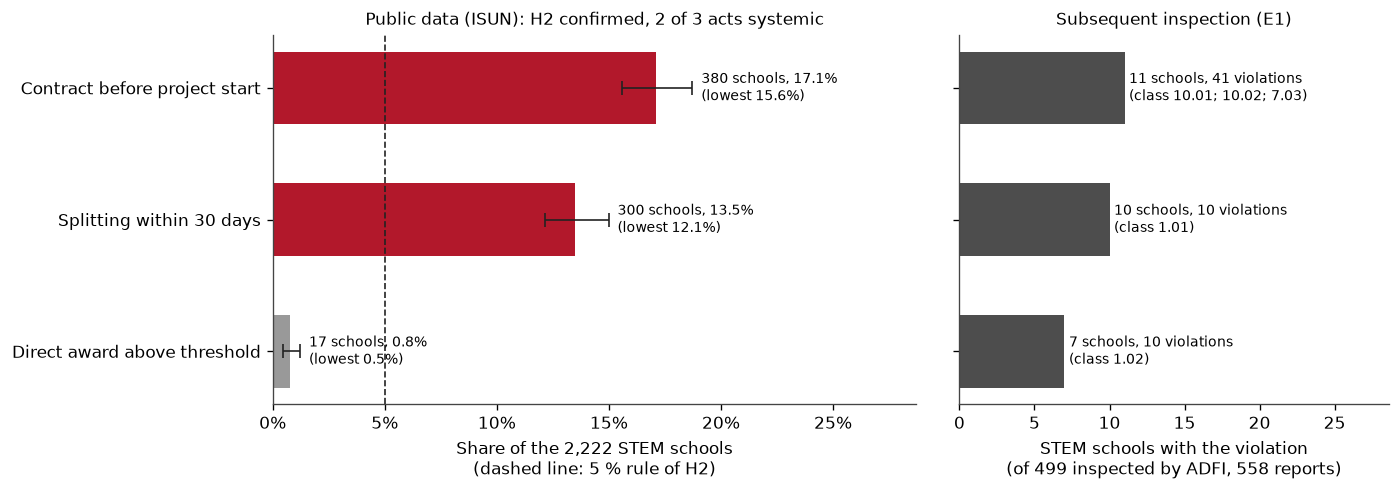

In [8]:
# Figure: for each act, STEM schools in the public data against the 5 % rule of H2, next to the STEM schools in which ADFI recorded it (E1).
fig_keys = list(ACT)
fig_lab = {
    "predated": "Contract before project start",
    "split_30d": "Splitting within 30 days",
    "regime_mismatch": "Direct award above threshold",
}
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.08}, sharey=True)
for i, k in enumerate(fig_keys):
    row = h2_view.loc[k]
    col = "#b2182b" if bool(row["ci95_lower_over_5pct"]) else "#999999"
    axL.barh(i, row["share_schools"], color=col, height=0.55)
    axL.errorbar(row["share_schools"], i,
                 xerr=[[row["share_schools"] - row["ci95_low"]], [row["ci95_high"] - row["share_schools"]]],
                 fmt="none", ecolor="#222222", capsize=4, lw=1)
    axL.text(row["ci95_high"] + 0.004, i,
             f"{int(row['n_schools'])} schools, {row['share_schools']:.1%}\n(lowest {row['ci95_low']:.1%})",
             va="center", fontsize=8.5)
    viol, e1_sch, _ = e1_text(k)
    axR.barh(i, e1_sch, color="#4d4d4d", height=0.55)
    axR.text(e1_sch + 0.3, i, f"{e1_sch} schools, {viol} violations\n(class {cmap.loc[k, 'e1_classes']})",
             va="center", fontsize=8.5)
axL.axvline(0.05, color="#222222", ls="--", lw=1)
axL.set_yticks(range(len(fig_keys)), [fig_lab[k] for k in fig_keys])
axL.invert_yaxis()
axL.xaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals=0))
axL.set_xlim(0, max(h2_view.loc[k, "ci95_high"] for k in fig_keys) + 0.10)
axL.set_xlabel(f"Share of the {N_SCHOOLS:,} STEM schools\n(dashed line: 5 % rule of H2)")
axL.set_title(f"Public data (ISUN): H2 {h2_decision}, {n_passing} of 3 acts systemic", fontsize=10)
axR.set_xlim(0, max(e1_text(k)[1] for k in fig_keys) * 2.6)
axR.set_xlabel(f"STEM schools with the violation\n(of {n_e1_schools} inspected by ADFI, {n_e1_reports} reports)")
axR.set_title("Subsequent inspection (E1)", fontsize=10)
for ax in (axL, axR):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.savefig(FIG_DIR / "F2_H2_systemic_failures.png", bbox_inches="tight")
plt.show()

## 5. Prices set just below the direct-award threshold (`bunching_50k`)

**What is done.** From 1 January 2024 a school may award a contract for goods or services directly, without a public call for offers, only if its value is below 50,000 BGN excl. VAT (Art. 20(4) PPA); at or above that value it must publish a call (Art. 20(3) PPA). This section counts the contracts signed from 2024 whose value lies just below the threshold, from 47,000 BGN up to the threshold, and compares them with the number that the values of the other contracts around the threshold would give if the threshold did not exist. The difference is the number of contracts whose price was brought below the threshold. The comparison is repeated in 14 ways fixed before the data were examined (other widths, other periods, other treatment of VAT and currency), so that the result does not depend on one choice. The exact prices that recur most often are listed as well.

**Why this is not part of H2.** Each of the three acts in Section 4.5 is seen in a single contract: its date or its value breaks a rule. A contract just below the threshold breaks no rule by itself. Only the excess over the expected number, across the whole programme, shows that prices were set to stay below the threshold. The result is therefore an indication for the financial controller, not a finding against a given contract.

**Why this matters for Element 1.** Before signature the financial controller checks that the estimated value of the contract rests on real market research (Art. 21(1)-(2) PPA) and that purchases from one supplier are not split (Art. 21(14)-(15) PPA). In its reports on the STEM schools ADFI checks the same points (classes 1.06 and 1.01). The public data show whether finding no violation there means that the prices were set by the market, or that an inspection of the file does not see a price brought just below the threshold.

**Figure F2_1.** It shows the contracts signed from 2024 around the 50,000 BGN threshold, with the expected number without the threshold, and the contracts signed up to 2023 around the 30,000 BGN threshold then in force. The thresholds for works (50,000 BGN up to 2023, 80,000 BGN from 2024) are drawn for reference only, because ISUN does not say whether a contract is for works.

In [9]:
reg2 = c_eval[c_eval["regime"] == 2].copy()
raw_arr = reg2["amount_raw"].to_numpy()
beur_arr = np.where(reg2["currency"] == "BGN", raw_arr / EUR_BGN, raw_arr)
vb_excl_alt = np.where(reg2["vat_basis"] == "undetermined", "excl_vat", reg2["vat_basis"])
reg2["bgn_excl_if_no_vat"] = np.round(np.where(vb_excl_alt == "incl_vat", beur_arr / VAT_FACTOR, beur_arr) * EUR_BGN, 2)


def fit_poisson_bunching(values, threshold=50000.0, bin_width=1000.0, half_window=15000.0, band_below=3000.0, band_above=3000.0, degree=3):
    """Fit Poisson QML counterfactual polynomial with HC1 standard errors."""
    n_bins = int(round(2.0 * half_window / bin_width))
    edges = threshold - half_window + bin_width * np.arange(n_bins + 1)
    counts, _ = np.histogram(np.asarray(values, dtype=float), bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2.0
    dist = (centers - threshold) / 10000.0
    below = (centers >= threshold - band_below) & (centers < threshold)
    above = (centers >= threshold) & (centers < threshold + band_above)
    X = np.column_stack([dist ** p for p in range(degree + 1)] + [below.astype(float), above.astype(float)])
    model = Poisson(counts, X).fit(disp=0, maxiter=200, cov_type="HC1")
    cf = np.exp(X[:, : degree + 1] @ model.params[: degree + 1])
    b1 = float(model.params[degree + 1])
    se1 = float(model.bse[degree + 1])
    p1 = float(model.pvalues[degree + 1])
    obs_b = int(counts[below].sum())
    exp_b = float(cf[below].sum())
    exc_b = float(np.sum(counts[below] - cf[below]))
    pct_exc = float((np.exp(b1) - 1.0) * 100.0)
    return {
        "edges": edges,
        "centers": centers,
        "counts": counts,
        "counterfactual": cf,
        "below": below,
        "above": above,
        "observed": obs_b,
        "expected": exp_b,
        "excess": exc_b,
        "percent_excess": pct_exc,
        "beta_1": b1,
        "se_1": se1,
        "p_value": p1,
        "converged": bool(model.mle_retvals["converged"]),
    }


pos_reg2 = reg2["amount_bgn_excl_vat"] > 0.0
yr_reg2 = pd.to_datetime(reg2["signature_date"]).dt.year
specs = [
    ("1. Baseline (deg=3, bin=1k, hw=15k, band=3k)", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {}),
    ("2. Undetermined VAT assumed excl. VAT", reg2.loc[reg2["bgn_excl_if_no_vat"] > 0, "bgn_excl_if_no_vat"].to_numpy(), {}),
    ("3. Known VAT basis only", reg2.loc[pos_reg2 & (reg2["vat_basis"] != "undetermined"), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("4. Known currency (excl. default) only", reg2.loc[pos_reg2 & (reg2["currency_basis"] != "default"), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("5. Signed in 2024 only", reg2.loc[pos_reg2 & (yr_reg2 == 2024), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("6. Signed from 2025 onward", reg2.loc[pos_reg2 & (yr_reg2 >= 2025), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("7. Bin width 500 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"bin_width": 500.0}),
    ("8. Bin width 2,000 BGN, bands 4,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"bin_width": 2000.0, "half_window": 16000.0, "band_below": 4000.0, "band_above": 4000.0}),
    ("9. Polynomial degree 2", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"degree": 2}),
    ("10. Polynomial degree 4", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"degree": 4}),
    ("11. Half-window 10,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"half_window": 10000.0}),
    ("12. Half-window 20,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"half_window": 20000.0}),
    ("13. Bands 2,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"band_below": 2000.0, "band_above": 2000.0}),
    ("14. Bands 4,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"band_below": 4000.0, "band_above": 4000.0}),
]

spec_rows = []
base_fit = None
for idx_s, (lbl, vv, kw) in enumerate(specs):
    res = fit_poisson_bunching(vv, **kw)
    assert res["converged"], f"Non-convergence in {lbl}"
    if idx_s == 0:
        base_fit = res
    spec_rows.append({
        "specification": lbl,
        "observed": res["observed"],
        "expected": res["expected"],
        "excess": res["excess"],
        "percent_excess": res["percent_excess"],
        "p_value": res["p_value"],
    })
specs_df = pd.DataFrame(spec_rows)
specs_df["q_bh"] = bh_fdr(specs_df["p_value"].to_numpy())
display(specs_df.style.hide(axis="index").format({"expected": "{:.1f}", "excess": "{:+.1f}", "percent_excess": "{:+.1f}%", "p_value": "{:.4f}", "q_bh": "{:.4f}"}))

b50_mask = (c_eval["regime"] == 2) & (c_eval["amount_bgn_excl_vat"] >= 47000.0) & (c_eval["amount_bgn_excl_vat"] < 50000.0)
b50_max = float(c_eval.loc[(c_eval["regime"] == 2) & (c_eval["amount_bgn_excl_vat"] < 50000.0), "amount_bgn_excl_vat"].max())
b50_row = summarize_indicator(b50_mask, "bunching_50k", "Price bunching in [47,000; 49,999.91] BGN excl. VAT", False, "", f"Poisson QML: obs={base_fit['observed']}, exp={base_fit['expected']:.1f}, excess={base_fit['percent_excess']:+.1f}%, p={base_fit['p_value']:.4f}, q={specs_df.loc[0, 'q_bh']:.4f} -> indication")
t21_df = pd.concat([t21_df, pd.DataFrame([b50_row])], ignore_index=True)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")

focal_bgn = reg2[pos_reg2].groupby("amount_bgn_excl_vat").agg(contracts=("contract_row", "count"), schools=("school_bulstat", "nunique")).sort_values("contracts", ascending=False).head(8).reset_index()
focal_raw = c_eval[c_eval["amount_raw"] > 0].groupby("amount_raw").agg(contracts=("contract_row", "count"), schools=("school_bulstat", "nunique")).sort_values("contracts", ascending=False).head(8).reset_index()
display(focal_bgn.style.hide(axis="index").format({"amount_bgn_excl_vat": "{:,.2f}"}))
display(focal_raw.style.hide(axis="index").format({"amount_raw": "{:,.2f}"}))

record_conclusion("Section 5", "bunching_50k", "bunching_50k: observed contracts in [47k, 50k)", base_fit["observed"])
record_conclusion("Section 5", "bunching_50k", "bunching_50k: max contract value below 50k BGN", f"{b50_max:.2f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: counterfactual expected contracts", f"{base_fit['expected']:.1f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: excess contracts", f"{base_fit['excess']:.1f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: percent excess", f"{base_fit['percent_excess']:.2f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: Poisson QML p-value", f"{base_fit['p_value']:.4f}", "", "", "HC1", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: BH-FDR q-value across 14 specs", f"{specs_df.loc[0, 'q_bh']:.4f}", "", "", "BH-FDR", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: specs significant at p<=0.05 (of 14)", int((specs_df["p_value"] <= 0.05).sum()))
record_conclusion("Section 5", "bunching_50k", "bunching_50k: schools", b50_row["n_schools"])
record_conclusion("Section 5", "bunching_50k", "bunching_50k: share of schools", f"{b50_row['share_schools']:.6f}", f"{b50_row['ci95_low']:.6f}", f"{b50_row['ci95_high']:.6f}", "Wilson", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: value EUR incl VAT", f"{b50_row['value_eur_incl_vat']:.2f}")
flush_conclusions()


specification,observed,expected,excess,percent_excess,p_value,q_bh
"1. Baseline (deg=3, bin=1k, hw=15k, band=3k)",295,184.1,+110.9,+60.2%,0.0341,0.0615
2. Undetermined VAT assumed excl. VAT,280,202.2,+77.8,+38.5%,0.1332,0.1554
3. Known VAT basis only,168,93.2,+74.8,+80.2%,0.0439,0.0615
4. Known currency (excl. default) only,224,140.1,+83.9,+59.9%,0.0978,0.1245
5. Signed in 2024 only,104,54.9,+49.1,+89.5%,0.0420,0.0615
6. Signed from 2025 onward,191,127.9,+63.1,+49.3%,0.0269,0.0615
7. Bin width 500 BGN,295,184.7,+110.3,+59.7%,0.0304,0.0615
"8. Bin width 2,000 BGN, bands 4,000 BGN",356,264.7,+91.3,+34.5%,0.2678,0.2678
9. Polynomial degree 2,295,185.6,+109.4,+58.9%,0.0364,0.0615
10. Polynomial degree 4,295,172.2,+122.8,+71.3%,0.0161,0.0563


amount_bgn_excl_vat,contracts,schools
"24,999.00",91,91
"8,332.99",42,42
"12,500.00",39,39
"24,999.01",34,34
"3,000.00",31,30
"2,083.33",25,25
"41,665.00",25,25
"1,500.01",22,22


amount_raw,contracts,schools
"29,998.80",59,59
"15,338.14",51,51
"5,112.71",44,44
"15,338.15",35,35
"7,669.38",29,29
920.33,23,23
"1,278.23",20,20
"1,840.65",19,18


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
86,Section 5,bunching_50k,bunching_50k: BH-FDR q-value across 14 specs,0.0615,,,BH-FDR,indication
87,Section 5,bunching_50k,bunching_50k: specs significant at p<=0.05 (of...,10,,,none,none
88,Section 5,bunching_50k,bunching_50k: schools,274,,,none,none
89,Section 5,bunching_50k,bunching_50k: share of schools,0.123312,0.110288,0.137637,Wilson,indication


In [10]:
# Economic conclusions of Section 5: every figure is taken from this run; the E1 classes come from concepts_df (Section 3).
b50 = t21_df.set_index("indicator").loc["bunching_50k"]
n_r2 = int(len(reg2))
n_specs = int(len(specs_df))
n_specs_pos = int((specs_df["excess"] > 0).sum())
n_specs_sig = int((specs_df["p_value"] <= 0.05).sum())
b50_proven = bool(specs_df.loc[0, "q_bh"] <= 0.05)
e106 = e1_stem[e1_stem["class_index"] == "1.06"]
e106_viol = int(e106["is_violation"].sum())
e101 = e1_stem[(e1_stem["class_index"] == "1.01") & e1_stem["is_violation"]]
assert cmap.loc["bunching_50k", "e1_classes"] == "1.01; 1.06"

lines = [
    f"Of the {n_r2:,} contracts signed from 2024, {base_fit['observed']} have a value just below the threshold for direct award "
    f"(from 47,000 to {b50_max:,.2f} BGN excl. VAT), while the values of the other contracts around the threshold would give "
    f"about {base_fit['expected']:.0f}: {base_fit['excess']:.0f} contracts more ({base_fit['percent_excess']:+.0f} %). "
    f"These contracts were signed by {int(b50['n_schools']):,} schools ({b50['share_schools']:.1%}) and are worth "
    f"EUR {b50['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT; EUR {b50['paid_eur_incl_vat'] / 1e6:,.2f} m of it has already been paid "
    f"and EUR {b50['unpaid_eur_incl_vat'] / 1e6:,.2f} m is not yet paid. "
    f"It means that schools and suppliers set the price so that the contract stays in direct award, without a public call for offers.",
    (f"The excess appears in all {n_specs} ways of measuring it" if n_specs_pos == n_specs
     else f"The excess appears in {n_specs_pos} of the {n_specs} ways of measuring it")
    + f" and is clear in {n_specs_sig} of them; "
    + ("taken together, it is established. " if b50_proven else "taken together, it is not strong enough to count as proof. ")
    + "It means that a price just below the threshold is a signal for the financial controller to check the market research "
    "behind it, not proof of a violation in a given contract.",
    "The most frequent prices are exact amounts repeated at many schools: "
    + ", ".join(f"{r.amount_bgn_excl_vat:,.2f} BGN excl. VAT in {r.contracts} contracts at {r.schools} schools"
                for r in focal_bgn.head(3).itertuples())
    + ". It means that these prices were not set by each school's own market research.",
    f"In its reports on the {n_e1_schools} STEM schools it inspected, ADFI checked how the estimated value was set "
    f"{len(e106)} times in {e106['rk'].nunique()} reports and found "
    + (f"no violation" if e106_viol == 0 else f"{e106_viol} violations")
    + f"; it recorded splitting of purchases as a violation {len(e101)} times, in {e101['school_bulstat'].nunique()} schools. "
    f"It means that the inspection finds in the file an estimate below the threshold and sees nothing wrong, while across "
    f"the programme {base_fit['excess']:.0f} more contracts than expected sit just below it. Only ex-ante control before signature, "
    f"checking whether the market research is real and whether the school has other contracts with the same supplier, can stop it.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Of the 11,055 contracts signed from 2024, 295 have a value just below the threshold for direct award (from 47,000 to 49,999.91 BGN excl. VAT), while the values of the other contracts around the threshold would give about 184: 111 contracts more (+60 %). These contracts were signed by 274 schools (12.3%) and are worth EUR 8.84 m incl. VAT; EUR 8.37 m of it has already been paid and EUR 0.48 m is not yet paid. It means that schools and suppliers set the price so that the contract stays in direct award, without a public call for offers.

2. The excess appears in all 14 ways of measuring it and is clear in 10 of them; taken together, it is not strong enough to count as proof. It means that a price just below the threshold is a signal for the financial controller to check the market research behind it, not proof of a violation in a given contract.

3. The most frequent prices are exact amounts repeated at many schools: 24,999.00 BGN excl. VAT in 91 contracts at 91 schools, 8,332.99 BGN e

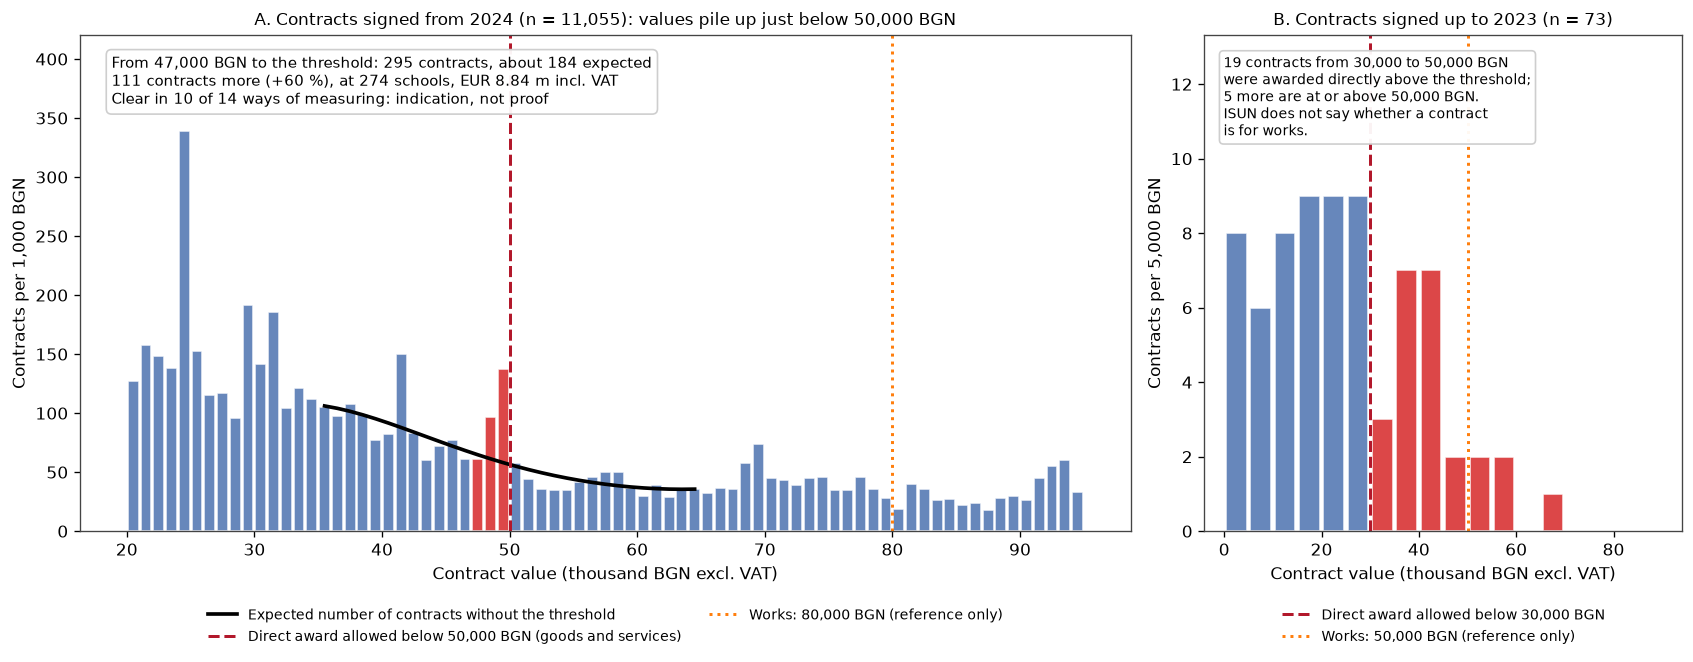

In [11]:
# Figure F2_1: contract values around the direct-award thresholds; every number in the figure is taken from this run.
reg1 = c_eval[c_eval["regime"] == 1]
n_r1 = int(len(reg1))
r1_30_50 = int(((reg1["amount_bgn_excl_vat"] >= 30000.0) & (reg1["amount_bgn_excl_vat"] < 50000.0)).sum())
r1_50 = int((reg1["amount_bgn_excl_vat"] >= 50000.0).sum())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [2.2, 1.0]}, constrained_layout=True)
bin_edges_r2 = np.arange(20000.0, 96000.0, 1000.0)
cnts_r2, _ = np.histogram(reg2.loc[pos_reg2, "amount_bgn_excl_vat"], bins=bin_edges_r2)
ctrs_r2 = (bin_edges_r2[:-1] + bin_edges_r2[1:]) / 2.0
bar_colors = ["#d62728" if (47000.0 <= c < 50000.0) else "#4c72b0" for c in ctrs_r2]
ax1.bar(ctrs_r2 / 1000.0, cnts_r2, width=0.85, color=bar_colors, alpha=0.85, edgecolor="white")
ax1.plot(base_fit["centers"] / 1000.0, base_fit["counterfactual"], color="black", linewidth=2.2,
         label="Expected number of contracts without the threshold")
ax1.axvline(50.0, color="#b2182b", linestyle="--", linewidth=1.8, label="Direct award allowed below 50,000 BGN (goods and services)")
ax1.axvline(80.0, color="#ff7f0e", linestyle=":", linewidth=1.8, label="Works: 80,000 BGN (reference only)")
ax1.set_xlabel("Contract value (thousand BGN excl. VAT)")
ax1.set_ylabel("Contracts per 1,000 BGN")
ax1.set_title(f"A. Contracts signed from 2024 (n = {n_r2:,}): values pile up just below 50,000 BGN", fontsize=10)
ax1.set_ylim(0, float(cnts_r2.max()) * 1.24)
ax1.text(0.03, 0.96,
         f"From 47,000 BGN to the threshold: {base_fit['observed']} contracts, about {base_fit['expected']:.0f} expected\n"
         f"{base_fit['excess']:.0f} contracts more ({base_fit['percent_excess']:+.0f} %), at {int(b50['n_schools']):,} schools, "
         f"EUR {b50['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT\n"
         f"Clear in {n_specs_sig} of {n_specs} ways of measuring: {'established' if b50_proven else 'indication, not proof'}",
         transform=ax1.transAxes, va="top", fontsize=9, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc", alpha=0.95))
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5, frameon=False)

edges_r1 = np.arange(0.0, 95000.0, 5000.0)
cnts_r1, _ = np.histogram(reg1["amount_bgn_excl_vat"], bins=edges_r1)
ctrs_r1 = (edges_r1[:-1] + edges_r1[1:]) / 2.0
cols_r1 = ["#d62728" if c >= 30000.0 else "#4c72b0" for c in ctrs_r1]
ax2.bar(ctrs_r1 / 1000.0, cnts_r1, width=4.2, color=cols_r1, alpha=0.85, edgecolor="white")
ax2.axvline(30.0, color="#b2182b", linestyle="--", linewidth=1.8, label="Direct award allowed below 30,000 BGN")
ax2.axvline(50.0, color="#ff7f0e", linestyle=":", linewidth=1.8, label="Works: 50,000 BGN (reference only)")
ax2.set_xlabel("Contract value (thousand BGN excl. VAT)")
ax2.set_ylabel("Contracts per 5,000 BGN")
ax2.set_title(f"B. Contracts signed up to 2023 (n = {n_r1})", fontsize=10)
ax2.set_ylim(0, max(float(cnts_r1.max()) * 1.48, 12.5))
ax2.text(0.04, 0.96,
         f"{r1_30_50} contracts from 30,000 to 50,000 BGN\nwere awarded directly above the threshold;\n"
         f"{r1_50} more are at or above 50,000 BGN.\nISUN does not say whether a contract\nis for works.",
         transform=ax2.transAxes, va="top", fontsize=8.2, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", alpha=0.95))
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=1, fontsize=8.5, frameon=False)

fig.savefig(FIG_DIR / "F2_1_values_around_thresholds.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Where the acts occur: 28 regions and the profile of Blagoevgrad

**What is done.** For each of the 28 regions (by the regional education office of the school) this section counts the STEM schools with at least one of the three acts of Section 4.5: signing the contract before the project started, splitting purchases from one supplier within 30 days, and awarding a contract directly although its value required a call or a procedure. Each share comes with the range within which it could lie by chance, which is wide in regions with few schools. The acts are also shown one by one, together with the prices just below the direct-award threshold from Section 5, and for each region the supplier with the largest part of the contracted value is named. One test checks whether the regions differ more than chance would allow. Blagoevgrad is then examined municipality by municipality, with the largest supplier's part of the contracted value, and with the ADFI reports on its STEM schools from Element 1.

**Why this matters for Element 1.** If the acts were spread evenly across the country, ADFI and the managing authority could choose the schools to inspect at random. If they are concentrated in some regions, the public data give a map of where control before signature and inspection after it should go first. The ADFI reports on the STEM schools of Blagoevgrad show whether the inspected schools are the ones where the public data find the acts.

**Figure F2_2.** Panel A shows for each region the share of its STEM schools with at least one of the three acts, the range that chance could give, and the share for all regions together; Blagoevgrad is marked. Panel B shows the share for each act separately and for prices just below the threshold. Direct award above the threshold is not drawn separately because it concerns very few schools.

In [12]:
c_eval["flag_level1"] = l1_mask.to_numpy()
c_eval["flag_bunching_50k"] = b50_mask.to_numpy()

sch_base = schools.drop_duplicates("school_bulstat").set_index("school_bulstat")
sch_reg = c_eval.groupby("school_bulstat").agg(
    contracts=("contract_row", "count"),
    contracted_eur_incl_vat=("amount_eur_incl_vat", "sum"),
    contracted_eur_excl_vat=("amount_eur_excl_vat", "sum"),
    paid_eur_incl_vat=("paid_alloc_eur_incl_vat", "sum"),
    flag_predated=("flag_predated", "any"),
    flag_split_30d=("flag_split_30d", "any"),
    flag_regime_mismatch=("flag_regime_mismatch", "any"),
    flag_level1=("flag_level1", "any"),
    flag_bunching_50k=("flag_bunching_50k", "any"),
    l1_contracts=("flag_level1", "sum"),
)
for col in ("school_name", "oblast_ruo", "municipality", "funding_type", "detailed_type", "register_budget_bgn_incl_vat"):
    sch_reg[col] = sch_base[col]
sch_reg["l1_val_incl_vat"] = (
    c_eval.loc[c_eval["flag_level1"]].groupby("school_bulstat")["amount_eur_incl_vat"].sum()
    .reindex(sch_reg.index, fill_value=0.0)
)
sch_reg = sch_reg.reset_index()

c_by_ob_ven = (
    c_eval.groupby(["oblast_ruo", "vendor_id", "vendor_eik", "vendor_name"], as_index=False)["amount_eur_incl_vat"]
    .sum()
    .sort_values(["oblast_ruo", "amount_eur_incl_vat"], ascending=[True, False])
)
ob_top_ven = c_by_ob_ven.drop_duplicates("oblast_ruo").set_index("oblast_ruo")

ob_rows = []
for ob, g in sch_reg.groupby("oblast_ruo"):
    n_s = int(len(g))
    k_l1 = int(g["flag_level1"].sum())
    p_l1, lo_l1, hi_l1 = wilson_ci(k_l1, n_s)
    k_pr = int(g["flag_predated"].sum())
    k_sp = int(g["flag_split_30d"].sum())
    k_rm = int(g["flag_regime_mismatch"].sum())
    k_b5 = int(g["flag_bunching_50k"].sum())
    tot_v = float(g["contracted_eur_incl_vat"].sum())
    top_r = ob_top_ven.loc[ob]
    ob_rows.append({
        "oblast": ob,
        "schools": n_s,
        "contracts": int(g["contracts"].sum()),
        "contracted_eur_incl_vat": round(tot_v, 2),
        "paid_eur_incl_vat": round(float(g["paid_eur_incl_vat"].sum()), 2),
        "predated_schools": k_pr,
        "predated_pct": round(k_pr / n_s * 100.0, 2),
        "split_30d_schools": k_sp,
        "split_30d_pct": round(k_sp / n_s * 100.0, 2),
        "regime_mismatch_schools": k_rm,
        "level1_schools": k_l1,
        "level1_pct": round(p_l1 * 100.0, 2),
        "level1_ci_low": round(lo_l1 * 100.0, 2),
        "level1_ci_high": round(hi_l1 * 100.0, 2),
        "level1_contracts": int(g["l1_contracts"].sum()),
        "level1_val_incl_vat": round(float(g["l1_val_incl_vat"].sum()), 2),
        "bunching_50k_schools": k_b5,
        "bunching_50k_pct": round(k_b5 / n_s * 100.0, 2),
        "top_supplier": str(top_r["vendor_name"]),
        "top_supplier_eik": str(top_r["vendor_eik"]),
        "oblast_c1_pct": round(float(top_r["amount_eur_incl_vat"]) / tot_v * 100.0, 2) if tot_v > 0 else 0.0,
    })

ob_df = pd.DataFrame(ob_rows).sort_values(["level1_pct", "schools", "oblast"], ascending=[False, False, True]).reset_index(drop=True)
ob_df["rank_l1"] = np.arange(1, len(ob_df) + 1)

chi2_ob, p_chi2_ob, dof_ob, _ = stats.chi2_contingency(
    np.column_stack([ob_df["level1_schools"].to_numpy(), (ob_df["schools"] - ob_df["level1_schools"]).to_numpy()])
)
print(f"Regional heterogeneity across 28 oblasts: chi2 = {chi2_ob:.2f} (df={dof_ob}, p={p_chi2_ob:.3e})")
display(ob_df[[
    "rank_l1", "oblast", "schools", "contracts", "level1_schools", "level1_pct",
    "level1_ci_low", "level1_ci_high", "predated_pct", "split_30d_pct",
    "bunching_50k_pct", "oblast_c1_pct", "top_supplier"
]])

top_ob = ob_df.iloc[0]
bot_ob = ob_df.iloc[-1]
blg_ob = ob_df[ob_df["oblast"] == "Благоевград"].iloc[0]
record_conclusion("Section 6", "regional", "regional heterogeneity p-value (chi2 across 28 oblasts)", f"{p_chi2_ob:.8f}", "", "", "chi2", "heterogeneous")
record_conclusion("Section 6", "regional", "highest Level 1 oblast name", str(top_ob["oblast"]))
record_conclusion("Section 6", "regional", "highest Level 1 oblast share (%)", f"{top_ob['level1_pct']:.2f}", f"{top_ob['level1_ci_low']:.2f}", f"{top_ob['level1_ci_high']:.2f}", "Wilson 95%", str(top_ob["oblast"]))
record_conclusion("Section 6", "regional", "lowest Level 1 oblast name", str(bot_ob["oblast"]))
record_conclusion("Section 6", "regional", "lowest Level 1 oblast share (%)", f"{bot_ob['level1_pct']:.2f}", f"{bot_ob['level1_ci_low']:.2f}", f"{bot_ob['level1_ci_high']:.2f}", "Wilson 95%", str(bot_ob["oblast"]))
record_conclusion("Section 6", "regional", "Blagoevgrad rank (of 28)", int(blg_ob["rank_l1"]))
record_conclusion("Section 6", "regional", "Blagoevgrad schools count", int(blg_ob["schools"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 schools count", int(blg_ob["level1_schools"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 schools (%)", f"{blg_ob['level1_pct']:.2f}", f"{blg_ob['level1_ci_low']:.2f}", f"{blg_ob['level1_ci_high']:.2f}", "Wilson 95%", f"{int(blg_ob['level1_schools'])}/{int(blg_ob['schools'])}")
record_conclusion("Section 6", "regional", "Blagoevgrad total contracts count", int(blg_ob["contracts"]))
record_conclusion("Section 6", "regional", "Blagoevgrad total contracted EUR incl VAT", f"{blg_ob['contracted_eur_incl_vat']:.2f}")
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 contracts count", int(blg_ob["level1_contracts"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 contracted EUR incl VAT", f"{blg_ob['level1_val_incl_vat']:.2f}")

blg_c = c_eval[c_eval["oblast_ruo"] == "Благоевград"].copy()
blg_s = sch_reg[sch_reg["oblast_ruo"] == "Благоевград"].copy()
blg_muni_rows = []
for mun, mg in blg_c.groupby("municipality"):
    ms = blg_s[blg_s["municipality"] == mun]
    by_v = mg.groupby(["vendor_eik", "vendor_name"], as_index=False)["amount_eur_incl_vat"].sum().sort_values("amount_eur_incl_vat", ascending=False)
    tot_m = float(mg["amount_eur_incl_vat"].sum())
    blg_muni_rows.append({
        "municipality": mun,
        "schools": int(len(ms)),
        "contracts": int(len(mg)),
        "contracted_eur_incl_vat": round(tot_m, 2),
        "level1_schools": int(ms["flag_level1"].sum()),
        "level1_pct": round(float(ms["flag_level1"].mean()) * 100.0, 1),
        "c1_pct": round(float(by_v.iloc[0]["amount_eur_incl_vat"]) / tot_m * 100.0, 2) if tot_m > 0 else 0.0,
        "top_supplier": str(by_v.iloc[0]["vendor_name"]),
        "top_supplier_eik": str(by_v.iloc[0]["vendor_eik"]),
    })
blg_muni_df = pd.DataFrame(blg_muni_rows).sort_values(["c1_pct", "schools"], ascending=[False, False]).reset_index(drop=True)
print(f"\nBlagoevgrad deep dive: rank {int(blg_ob['rank_l1'])}/28, {int(blg_ob['level1_schools'])}/{int(blg_ob['schools'])} schools ({blg_ob['level1_pct']:.2f}%), {int(blg_ob['contracts'])} contracts ({blg_ob['contracted_eur_incl_vat']:,.2f} EUR incl. VAT), Level 1: {int(blg_ob['level1_contracts'])} contracts ({blg_ob['level1_val_incl_vat']:,.2f} EUR incl. VAT).")
display(blg_muni_df)

for fm_mun in ("Белица", "Банско", "Благоевград"):
    r_m = blg_muni_df[blg_muni_df["municipality"] == fm_mun].iloc[0]
    record_conclusion("Section 6", "regional", f"Blagoevgrad {fm_mun} C1 supplier share (%)", f"{r_m['c1_pct']:.2f}", "", "", "top_supplier", str(r_m["top_supplier"]))

norm_map = dict(zip(project_classes["school_bulstat_isun"], project_classes["school_bulstat"]))
stem_set = set(sch_reg["school_bulstat"])
adfi_m_tmp = adfi_meta.copy()
adfi_m_tmp["stem_b"] = adfi_m_tmp["eik"].map(lambda e: e if e in stem_set else norm_map.get(e, ""))
blg_aud_meta = adfi_m_tmp[adfi_m_tmp["stem_b"].isin(set(blg_s["school_bulstat"]))].copy()
blg_aud_sch = set(blg_aud_meta["stem_b"])
blg_aud_l1 = blg_aud_sch & set(blg_s.loc[blg_s["flag_level1"], "school_bulstat"])
print(f"ADFI audits in Blagoevgrad: {len(blg_aud_meta)} reports across {len(blg_aud_sch)} STEM schools (directorates: {blg_aud_meta['directorate_bg'].value_counts().to_dict()}); {len(blg_aud_l1)} audited schools have Level 1 indicators.")
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI audited schools", int(len(blg_aud_sch)))
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI reports count", int(len(blg_aud_meta)))
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI audited with Level 1", int(len(blg_aud_l1)))
flush_conclusions()

Regional heterogeneity across 28 oblasts: chi2 = 77.40 (df=27, p=9.304e-07)


,rank_l1,oblast,schools,contracts,level1_schools,level1_pct,level1_ci_low,level1_ci_high,predated_pct,split_30d_pct,bunching_50k_pct,oblast_c1_pct,top_supplier
0,1,Перник,41,166,23,56.10,41.04,70.11,46.34,9.76,7.32,32.54,БАЛИСТИК СЕЛ ЕООД
1,2,Монтана,59,244,27,45.76,33.70,58.34,40.68,6.78,10.17,16.42,Офис 1 Запад ЕООД
2,3,Търговище,48,284,21,43.75,30.70,57.72,16.67,29.17,12.50,11.76,",,А1 България“ ЕАД"
3,4,Русе,64,412,26,40.62,29.46,52.85,29.69,12.50,17.19,10.05,СИЕНСИС АД
4,5,Силистра,41,198,16,39.02,25.66,54.27,31.71,9.76,7.32,14.56,",,А1 България“ ЕАД"
5,6,Велико Търново,81,421,30,37.04,27.33,47.92,24.69,13.58,11.11,15.67,ВАЛИ КОМПЮТЪРС ООД
6,7,София-област,92,458,34,36.96,27.80,47.16,18.48,20.65,14.13,13.38,Кооперация Панда
7,8,Благоевград,120,535,43,35.83,27.82,44.73,16.67,22.50,14.17,16.13,Уеб Сървисис ЕООД
8,9,Видин,32,123,11,34.38,20.41,51.69,18.75,15.62,3.12,21.33,Кооперация Панда
9,10,Хасково,79,420,26,32.91,23.55,43.85,21.52,13.92,16.46,20.83,Кооперация Панда



Blagoevgrad deep dive: rank 8/28, 43/120 schools (35.83%), 535 contracts (15,205,734.22 EUR incl. VAT), Level 1: 108 contracts (1,634,844.80 EUR incl. VAT).


,municipality,schools,contracts,contracted_eur_incl_vat,level1_schools,level1_pct,c1_pct,top_supplier,top_supplier_eik
0,Кресна,1,5,124935.98,0,0.0,69.36,Уеб Сървисис ЕООД,200544954
1,Гърмен,8,44,1258429.22,2,25.0,63.41,ГАРАНТ-2004 ЕООД,101661176
2,Якоруда,6,20,465227.30,1,16.7,54.24,Кооперация Панда,000885099
3,Струмяни,1,5,122693.15,0,0.0,49.99,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,175342714
4,Сандански,11,40,1278347.24,3,27.3,46.47,Уеб Сървисис ЕООД,200544954
5,Сатовча,13,53,832451.95,8,61.5,43.40,",,А1 България“ ЕАД",131468980
6,Гоце Делчев,14,63,1818003.36,8,57.1,37.39,Юнион Интерактив ООД,204660454
7,Белица,6,28,739408.02,2,33.3,34.42,Кооперация Панда,000885099
8,Симитли,3,14,377275.67,1,33.3,33.70,",,А1 България“ ЕАД",131468980
9,Хаджидимово,5,17,483804.64,1,20.0,30.22,Юнион Интерактив ООД,204660454


ADFI audits in Blagoevgrad: 22 reports across 20 STEM schools (directorates: {'ДИД4': 22}); 8 audited schools have Level 1 indicators.


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
105,Section 6,regional,Blagoevgrad Банско C1 supplier share (%),22.99,,,top_supplier,СТЕМО ЕООД
106,Section 6,regional,Blagoevgrad Благоевград C1 supplier share (%),26.97,,,top_supplier,АЙ ОФИС ООД
107,Section 6,regional,Blagoevgrad ADFI audited schools,20,,,none,none
108,Section 6,regional,Blagoevgrad ADFI reports count,22,,,none,none


In [13]:
# Economic conclusions of Section 6: every figure is taken from this run; the E1 classes come from concepts_df (Section 3) and the STEM-only E1 rows (e1_stem) from Section 3.
OBLAST_EN = {
    "Благоевград": "Blagoevgrad", "Бургас": "Burgas", "Варна": "Varna",
    "Велико Търново": "Veliko Tarnovo", "Видин": "Vidin", "Враца": "Vratsa",
    "Габрово": "Gabrovo", "Добрич": "Dobrich", "Кърджали": "Kardzhali",
    "Кюстендил": "Kyustendil", "Ловеч": "Lovech", "Монтана": "Montana",
    "Пазарджик": "Pazardzhik", "Перник": "Pernik", "Плевен": "Pleven",
    "Пловдив": "Plovdiv", "Разград": "Razgrad", "Русе": "Ruse",
    "Силистра": "Silistra", "Сливен": "Sliven", "Смолян": "Smolyan",
    "София-град": "Sofia-City", "София-област": "Sofia Oblast", "Софийска област": "Sofia Oblast",
    "Стара Загора": "Stara Zagora", "Търговище": "Targovishte",
    "Хасково": "Haskovo", "Шумен": "Shumen", "Ямбол": "Yambol",
}
ACT_SHORT = {
    "predated_pct": "contracts signed before the project started",
    "split_30d_pct": "purchases from one supplier split within 30 days",
}
nat_share = float(sch_reg["flag_level1"].mean())
p_text = "less than 1 in 1,000" if p_chi2_ob < 0.001 else f"{p_chi2_ob:.3f}"
top3 = ob_df.head(3)
blg_lead = max(ACT_SHORT, key=lambda c: blg_ob[c])
c1_munis = blg_muni_df[(blg_muni_df["c1_pct"] > 50.0) & (blg_muni_df["schools"] >= 2)]
c1_single = blg_muni_df[(blg_muni_df["c1_pct"] > 50.0) & (blg_muni_df["schools"] < 2)]
l1_classes = sorted({c.strip() for k in ("predated", "split_30d", "regime_mismatch") for c in cmap.loc[k, "e1_classes"].split(";")})
blg_set = set(blg_s["school_bulstat"])
blg_e1 = e1_stem[e1_stem["school_bulstat"].isin(blg_set)]
blg_e1_acts = blg_e1[blg_e1["class_index"].isin(l1_classes) & blg_e1["is_violation"]]
n_blg_l1 = int(blg_s["flag_level1"].sum())
assert len(blg_aud_sch) == int(stem_reports.loc[stem_reports["school_bulstat"].isin(blg_set), "school_bulstat"].nunique())

nat_pct = nat_share * 100.0
above = ob_df[ob_df["level1_ci_low"] > nat_pct]
below = ob_df[ob_df["level1_ci_high"] < nat_pct]
n_middle = len(ob_df) - len(above) - len(below)
names_of = lambda d: ", ".join(OBLAST_EN[o] for o in d["oblast"])
blg_c_val = float(blg_c["amount_eur_incl_vat"].sum())
blg_paid = float(blg_c["paid_alloc_eur_incl_vat"].sum())
blg_l1c = blg_c[blg_c["flag_level1"]]
blg_l1_unpaid = float(blg_l1c["amount_eur_incl_vat"].sum() - blg_l1c["paid_alloc_eur_incl_vat"].sum())
BLG_ACTS = {
    "flag_predated": "signed before the project started",
    "flag_split_30d": "split purchases from one supplier within 30 days",
    "flag_regime_mismatch": "direct award although the value required a call or a procedure",
    "flag_bunching_50k": "price just below 50,000 BGN",
}
blg_act_parts = []
for f, txt in BLG_ACTS.items():
    m = blg_c[f]
    blg_act_parts.append(
        f"{txt}: no contract" if int(m.sum()) == 0 else
        f"{txt}: {int(m.sum())} contracts at {blg_c.loc[m, 'school_bulstat'].nunique()} schools, EUR {blg_c.loc[m, 'amount_eur_incl_vat'].sum() / 1e6:,.2f} m"
    )
FOCAL_MUNIS = ("Белица", "Банско", "Благоевград")
aud_by_mun = blg_aud_meta["stem_b"].map(blg_s.set_index("school_bulstat")["municipality"]).value_counts()
focal = blg_muni_df.set_index("municipality").loc[list(FOCAL_MUNIS)]
focal_share = float(focal["level1_schools"].sum() / focal["schools"].sum() * 100.0)
blg_l1_val = float(blg_l1c["amount_eur_incl_vat"].sum())

lines = [
    f"Across the {len(ob_df)} regions, the share of STEM schools with at least one of the three acts ranges from "
    f"{bot_ob['level1_pct']:.1f} % in {OBLAST_EN[bot_ob['oblast']]} to {top_ob['level1_pct']:.1f} % in {OBLAST_EN[top_ob['oblast']]}; for the whole country it is "
    f"{nat_share * 100:.1f} %. The chance that differences of this size arise by accident is {p_text}. "
    f"It means that the acts are not isolated errors spread evenly across the country: they gather in some regions, "
    f"so the control bodies can plan inspections by region according to risk instead of choosing schools at random.",
    f"Measured against the share for the whole country, {len(above)} regions are clearly above it even in the lowest estimate "
    f"({names_of(above)}), {len(below)} are clearly below it even in the highest estimate ({names_of(below)}), and in the other "
    f"{n_middle} the difference could be due to chance. "
    f"It means that the regions to check first can be named from the public data, and that a high share in a region with few schools "
    f"is a reason to look closer, not yet a finding.",
    "The regions with the highest shares get there through different acts: "
    + "; ".join(f"{OBLAST_EN[r.oblast]} {r.level1_pct:.1f} %, mostly {ACT_SHORT[max(ACT_SHORT, key=lambda c: getattr(r, c))]} "
                f"({max(r.predated_pct, r.split_30d_pct):.1f} % of its schools)" for r in top3.itertuples())
    + ". It means that the financial controller in each region has a different point to check first before signature: "
    "the date of the commitment in some regions, the orders placed with the same supplier in others.",
    f"Blagoevgrad is {int(blg_ob['rank_l1'])} of {len(ob_df)}: {int(blg_ob['level1_schools'])} of its {int(blg_ob['schools'])} STEM schools "
    f"({blg_ob['level1_pct']:.1f} %) have at least one act, in {int(blg_ob['level1_contracts'])} of its {int(blg_ob['contracts'])} contracts, "
    f"worth EUR {blg_ob['level1_val_incl_vat'] / 1e6:,.2f} m of EUR {blg_ob['contracted_eur_incl_vat'] / 1e6:,.2f} m incl. VAT. "
    f"The most frequent act there is {ACT_SHORT[blg_lead]} ({blg_ob[blg_lead]:.1f} % of the schools), and "
    f"{blg_ob['bunching_50k_pct']:.1f} % of the schools have a price just below the threshold. "
    + ("It means that in Blagoevgrad the risk lies mainly in how purchases are divided between contracts."
       if blg_lead == "split_30d_pct" else "It means that in Blagoevgrad the risk lies mainly in commitments taken before the project started."),
    f"Of the EUR {blg_c_val / 1e6:,.2f} m contracted in Blagoevgrad (EUR {blg_c['amount_eur_excl_vat'].sum() / 1e6:,.2f} m excl. VAT), "
    f"EUR {blg_paid / 1e6:,.2f} m has been paid and EUR {(blg_c_val - blg_paid) / 1e6:,.2f} m is not yet paid. The contracts with at least one act are "
    f"{len(blg_l1c) / len(blg_c) * 100:.1f} % of the contracts and {blg_l1_val / blg_c_val * 100:.1f} % of the value in the region; "
    f"EUR {blg_l1_unpaid:,.0f} of them is not yet paid. By act: " + "; ".join(blg_act_parts) + ". "
    + (f"It means that almost all of the EUR {blg_l1_val / 1e6:,.2f} m in contracts with an act has already been paid: only EUR {blg_l1_unpaid:,.0f} "
       "can still be stopped, and the rest can only be recovered after an inspection; this is why the check has to come before signature."
       if blg_l1_unpaid < 0.1 * blg_l1_val else
       f"It means that EUR {blg_l1_unpaid:,.0f} in contracts with an act can still be stopped before payment.")
    + (" With no direct award above the threshold in the region, the controller there should look first at orders placed with the same supplier."
       if int(blg_c["flag_regime_mismatch"].sum()) == 0 else ""),
    f"In {len(c1_munis)} municipalities of Blagoevgrad with more than one STEM school, one supplier holds more than half of the contracted value: "
    + "; ".join(f"{r.municipality} {r.c1_pct:.1f} % ({r.top_supplier}, {r.schools} schools)" for r in c1_munis.itertuples())
    + (f". In {', '.join(c1_single['municipality'])} one supplier also holds more than half, but there is only one STEM school, so the share shows only that school's choice"
       if len(c1_single) else "")
    + ". It means that different schools in the same municipality end up with the same supplier; the financial controller should check "
    "whether the offers were really compared or the market research only confirms a supplier chosen in advance.",
    "In the three municipalities named in advance for a closer look: "
    + "; ".join(f"{m} {int(r.schools)} schools, EUR {r.contracted_eur_incl_vat / 1e6:,.2f} m incl. VAT, {int(r.level1_schools)} with an act, "
                f"largest supplier {r.top_supplier} with {r.c1_pct:.1f} % of the value, {int(aud_by_mun.get(m, 0))} ADFI reports"
                for m, r in focal.iterrows())
    + f". Together {focal_share:.1f} % of their schools have an act, against {blg_ob['level1_pct']:.1f} % in the region, and "
    + ("in none of them does one supplier hold half of the value. " if bool((focal["c1_pct"] <= 50.0).all()) else "in some of them one supplier holds more than half of the value. ")
    + ("It means that the public data do not single out these three municipalities: the higher risk in Blagoevgrad lies in "
       + " and ".join(c1_munis["municipality"]) + " and in the schools with acts elsewhere in the region."
       if focal_share < blg_ob["level1_pct"] and bool((focal["c1_pct"] <= 50.0).all()) else
       "It means that the public data confirm the closer look at these municipalities."),
    f"ADFI inspected {len(blg_aud_sch)} STEM schools in Blagoevgrad ({len(blg_aud_meta)} reports); {len(blg_aud_l1)} of them "
    f"({len(blg_aud_l1) / len(blg_aud_sch) * 100:.0f} %) have one of the three acts, close to the {blg_ob['level1_pct']:.0f} % of all schools in the region. "
    f"Of the {n_blg_l1} schools with an act, {n_blg_l1 - len(blg_aud_l1)} were not inspected, and in its reports on the region ADFI "
    + ("did not record any of these acts as a violation. " if len(blg_e1_acts) == 0 else f"recorded these acts as a violation {len(blg_e1_acts)} times. ")
    + "It means that the inspection does not choose schools by the acts that the public data show; the data can direct control to the schools where the acts are.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Across the 28 regions, the share of STEM schools with at least one of the three acts ranges from 11.4 % in Yambol to 56.1 % in Pernik; for the whole country it is 28.7 %. The chance that differences of this size arise by accident is less than 1 in 1,000. It means that the acts are not isolated errors spread evenly across the country: they gather in some regions, so the control bodies can plan inspections by region according to risk instead of choosing schools at random.

2. Measured against the share for the whole country, 4 regions are clearly above it even in the lowest estimate (Pernik, Montana, Targovishte, Ruse), 4 are clearly below it even in the highest estimate (Pleven, Burgas, Dobrich, Yambol), and in the other 20 the difference could be due to chance. It means that the regions to check first can be named from the public data, and that a high share in a region with few schools is a reason to look closer, not yet a finding.

3. The regions with the highest shares get there t

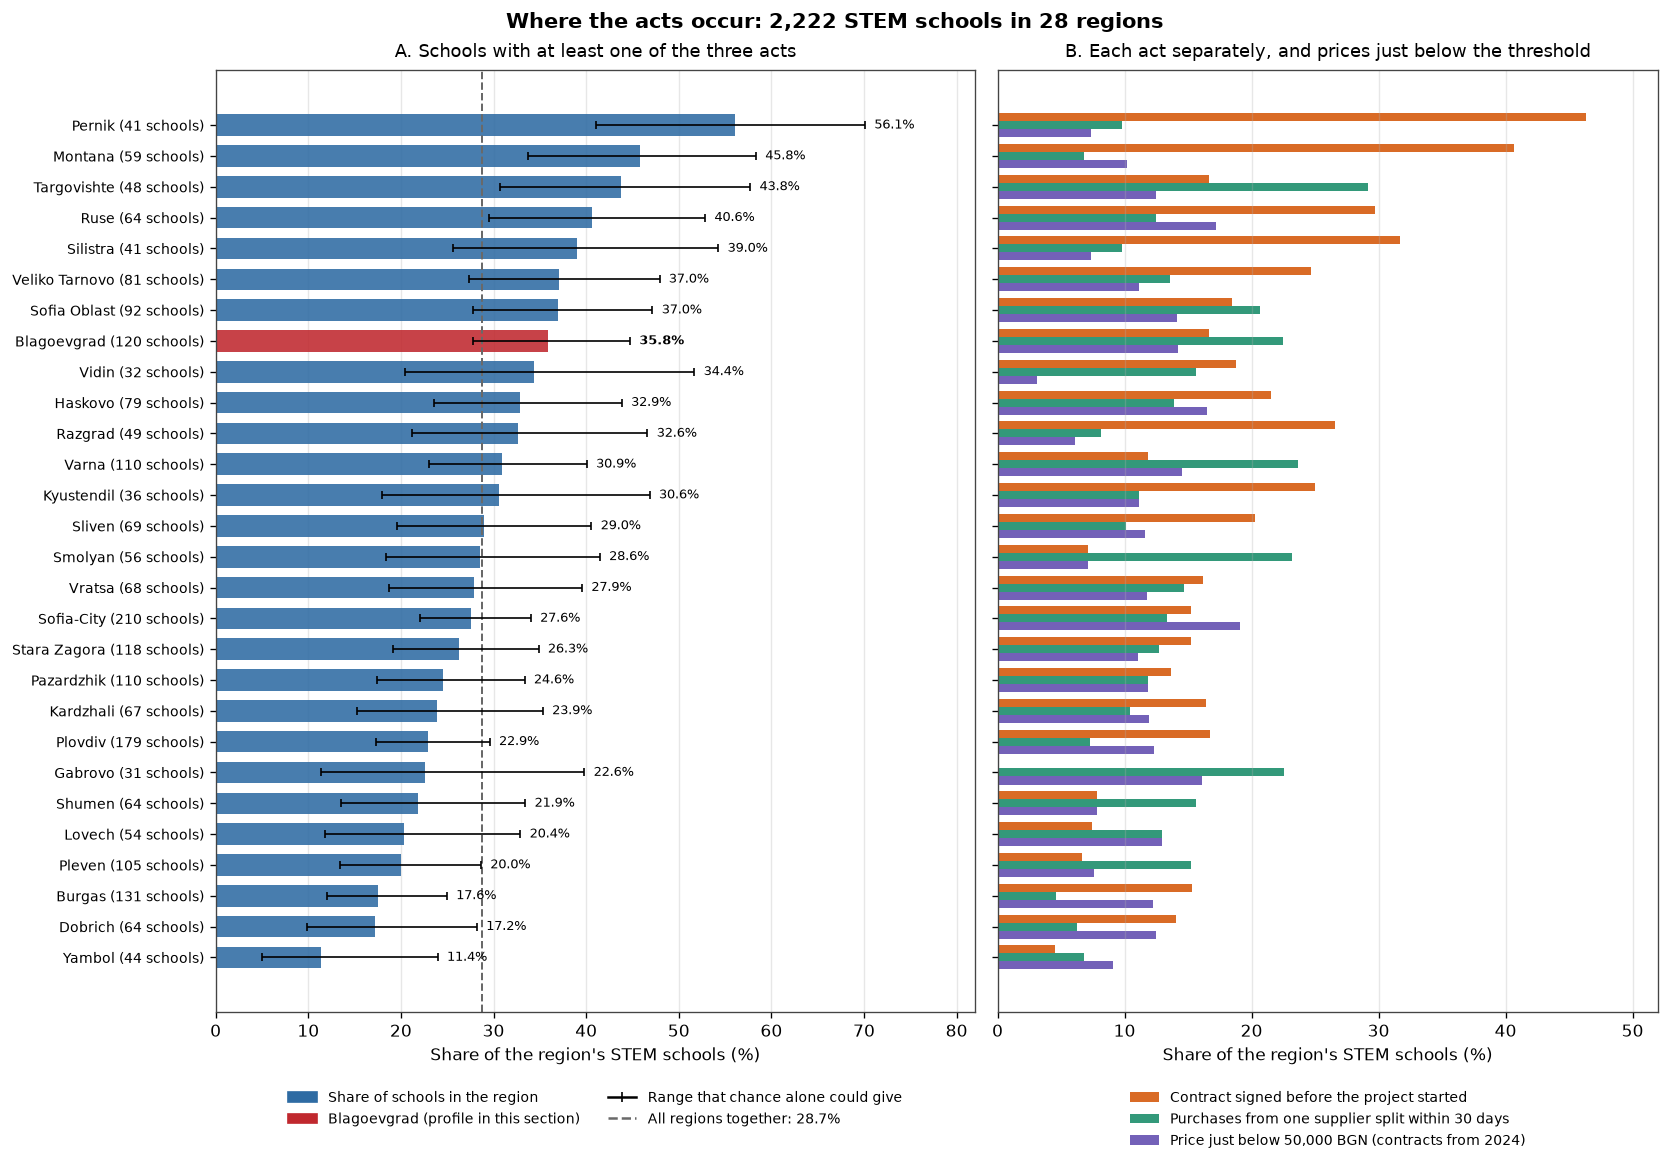

In [14]:
# Figure F2_2: share of STEM schools with the acts by region; every number in the figure is taken from this run.
from matplotlib.patches import Patch

ob_plot = ob_df.iloc[::-1].reset_index(drop=True).copy()
ob_plot["label"] = [f"{OBLAST_EN.get(r['oblast'], r['oblast'])} ({int(r['schools'])} schools)" for _, r in ob_plot.iterrows()]
y_pos = np.arange(len(ob_plot))
nat_l1 = float(sch_reg["flag_level1"].mean() * 100.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 9.6), sharey=True, gridspec_kw={"width_ratios": [1.15, 1.0]}, constrained_layout=True)

colors_l1 = ["#c0282e" if r["oblast"] == "Благоевград" else "#2e6ba3" for _, r in ob_plot.iterrows()]
ax1.barh(y_pos, ob_plot["level1_pct"], color=colors_l1, alpha=0.88, height=0.70, zorder=2)
ax1.errorbar(ob_plot["level1_pct"], y_pos,
             xerr=[ob_plot["level1_pct"] - ob_plot["level1_ci_low"], ob_plot["level1_ci_high"] - ob_plot["level1_pct"]],
             fmt="none", ecolor="black", elinewidth=1.0, capsize=2.5, zorder=3)
ax1.axvline(nat_l1, color="dimgray", linestyle="--", linewidth=1.2)
for idx_row, row in ob_plot.iterrows():
    ax1.text(row["level1_ci_high"] + 1.0, idx_row, f"{row['level1_pct']:.1f}%", va="center", ha="left", fontsize=7.8,
             fontweight="bold" if row["oblast"] == "Благоевград" else "normal")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(ob_plot["label"], fontsize=8.5)
ax1.set_xlabel("Share of the region's STEM schools (%)")
ax1.set_xlim(0, 82)
ax1.set_title("A. Schools with at least one of the three acts", fontsize=10.5, pad=8)
ax1.grid(axis="x", alpha=0.3)
ax1.legend(handles=[
    Patch(color="#2e6ba3", label="Share of schools in the region"),
    Patch(color="#c0282e", label="Blagoevgrad (profile in this section)"),
    plt.Line2D([], [], color="black", marker="|", linestyle="-", label="Range that chance alone could give"),
    plt.Line2D([], [], color="dimgray", linestyle="--", label=f"All regions together: {nat_l1:.1f}%"),
], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8.5, frameon=False)

bar_h = 0.26
ax2.barh(y_pos + bar_h, ob_plot["predated_pct"], height=bar_h, color="#d96b26", label="Contract signed before the project started")
ax2.barh(y_pos, ob_plot["split_30d_pct"], height=bar_h, color="#33997a", label="Purchases from one supplier split within 30 days")
ax2.barh(y_pos - bar_h, ob_plot["bunching_50k_pct"], height=bar_h, color="#7361b8", label="Price just below 50,000 BGN (contracts from 2024)")
ax2.set_xlabel("Share of the region's STEM schools (%)")
ax2.set_xlim(0, 52)
ax2.set_title("B. Each act separately, and prices just below the threshold", fontsize=10.5, pad=8)
ax2.grid(axis="x", alpha=0.3)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=1, fontsize=8.5, frameon=False)

fig.suptitle(f"Where the acts occur: {len(sch_reg):,} STEM schools in {len(ob_df)} regions", fontsize=12.5, fontweight="bold")
fig.savefig(FIG_DIR / "F2_2_indicator_share_by_region.png", dpi=300, bbox_inches="tight")
plt.show()

## 6.3 Who signs the contracts: municipal and state schools, school types, and one supplier per municipality

**What is done.** For the STEM schools, this section compares the share with at least one of the three acts of Section 4.5 (signing the contract before the project started, splitting purchases from one supplier within 30 days, and awarding a contract directly although its value required a call or a procedure). The comparison is made between municipal and state schools (by the funding recorded in the register of the Ministry of Education) and between types of school; types with fewer than 30 STEM schools are grouped as "Other". Each share comes with the range within which it could lie by chance. Two tests check whether the differences are larger than chance would allow: once across the whole country, and once comparing schools only with schools of the same region, so that a difference cannot come from municipal and state schools being in different regions. Then, in each municipality with at least three STEM schools, each school's contracts are compared with those of the other schools of the same municipality: the measure is the part of the school's contracted value that went to the supplier the other schools used most. Municipal and state schools are compared on this measure inside the same region, and inside the same region and budget size. This measure is not part of the rule for H2.

**Why this matters for Element 1.** Every school is a contracting authority, and its financial controller checks each commitment before it is taken (Art. 13(3) FMCPSA). Municipal schools are funded through the municipality, state schools through the ministry. If municipal schools have more acts, or if the schools of one municipality end up with the same supplier, part of the risk lies above the school: many orders from one contractor, direct awards below the threshold and successive linked supplies, which are signs of fraud and irregularity. The school's controller sees only the school's own file, and ADFI inspects one school at a time, so this pattern can be seen only by comparing the schools of a municipality.

**Figure F2_3.** Panel A shows the share of schools with at least one of the three acts for municipal and state schools and for each type of school, the range that chance could give, and the share for all STEM schools. Panel B shows each act separately, and prices just below the threshold from Section 5. Panel C shows the part of a school's value placed with the supplier the other schools of its municipality use most, for municipal and state schools, and the share of municipal schools with an act among those that follow that supplier and those that do not. Panel D shows, from Element 1, the violations ADFI found in the tender documentation per inspected school, by funding and type of school.

In [15]:
# Section 6.3: STEM schools with at least one of the three acts by funding (municipal / state) and by school type, with two permutation tests: across the country and within each region.
reg_meta = schools_register.drop_duplicates("Булстат").set_index("Булстат")
sch_inst = sch_reg.copy()

dt_counts = sch_inst["detailed_type"].value_counts()
small_types = set(dt_counts[dt_counts < 30].index)
sch_inst["type_grouped"] = sch_inst["detailed_type"].where(~sch_inst["detailed_type"].isin(small_types), "Other (<30)")
TYPE_EN = {
    "начално": "Primary (НУ, 1-4)",
    "основно": "Basic (ОУ, 1-7)",
    "средно": "Secondary (СУ, 1-12)",
    "обединено": "United (ОбУ, 1-10)",
    "профилирана гимназия": "Profiled High School (ПГ)",
    "професионална гимназия": "Vocational High School (ПрофГ)",
    "център за специална образователна подкрепа": "Centre for Special Educational Support (ЦСОП)",
    "Other (<30)": "Other (<30 schools)",
}
FUND_EN = {"Общинско": "Municipal", "Държавно": "State", "Частно": "Private", "Духовно": "Spiritual"}
assert set(sch_inst["type_grouped"]) <= set(TYPE_EN)
assert set(sch_inst["funding_type"]) <= set(FUND_EN)


def summarize_group(df_in, col, map_dict=None):
    rows = []
    for key, g in df_in.groupby(col, observed=True):
        n_g = int(len(g))
        k_l1 = int(g["flag_level1"].sum())
        p_l1, lo_l1, hi_l1 = wilson_ci(k_l1, n_g)
        rows.append({
            "category": str(key),
            "label_en": map_dict.get(str(key), str(key)) if map_dict else str(key),
            "schools": n_g,
            "level1_schools": k_l1,
            "level1_pct": round(p_l1 * 100.0, 2),
            "ci_95": f"[{lo_l1*100:.2f}%; {hi_l1*100:.2f}%]",
            "predated_pct": round(float(g["flag_predated"].mean()) * 100.0, 2),
            "split_30d_pct": round(float(g["flag_split_30d"].mean()) * 100.0, 2),
            "bunching_50k_pct": round(float(g["flag_bunching_50k"].mean()) * 100.0, 2),
            "median_contracted_eur": round(float(g["contracted_eur_incl_vat"].median()), 2),
        })
    return pd.DataFrame(rows).sort_values("level1_pct", ascending=False).reset_index(drop=True)


t_tbl = summarize_group(sch_inst, "type_grouped", TYPE_EN)
f_tbl = summarize_group(sch_inst, "funding_type", FUND_EN)

N_PERM_63 = 10000
rng_63 = np.random.default_rng(RNG_STATE)
y_l1 = sch_inst["flag_level1"].to_numpy().astype(float)
ob_codes_63 = pd.factorize(sch_inst["oblast_ruo"], sort=True)[0]
ob_blocks_63 = [np.flatnonzero(ob_codes_63 == g) for g in np.unique(ob_codes_63)]


def chi2_stat(g_codes, y_vals, n_groups):
    k = np.bincount(g_codes, weights=y_vals, minlength=n_groups)
    n = np.bincount(g_codes, minlength=n_groups).astype(float)
    obs = np.column_stack([k, n - k])
    exp = np.outer(n, [y_vals.sum(), len(y_vals) - y_vals.sum()]) / len(y_vals)
    return float(((obs - exp) ** 2 / exp).sum())


def perm_chi2(col):
    g_codes, g_names = pd.factorize(sch_inst[col], sort=True)
    n_groups = len(g_names)
    chi2_obs = chi2_stat(g_codes, y_l1, n_groups)
    null_all = np.empty(N_PERM_63)
    null_ob = np.empty(N_PERM_63)
    for p_i in range(N_PERM_63):
        null_all[p_i] = chi2_stat(g_codes, rng_63.permutation(y_l1), n_groups)
        y_sh = y_l1.copy()
        for blk in ob_blocks_63:
            y_sh[blk] = y_l1[rng_63.permutation(blk)]
        null_ob[p_i] = chi2_stat(g_codes, y_sh, n_groups)
    p_all = (1 + int((null_all >= chi2_obs - 1e-9).sum())) / (N_PERM_63 + 1)
    p_ob = (1 + int((null_ob >= chi2_obs - 1e-9).sum())) / (N_PERM_63 + 1)
    return chi2_obs, n_groups - 1, p_all, p_ob


chi2_f, df_f, p_f_all, p_f_ob = perm_chi2("funding_type")
chi2_t, df_t, p_t_all, p_t_ob = perm_chi2("type_grouped")
tests_63 = pd.DataFrame([
    {"comparison": "Municipal vs State", "groups": df_f + 1, "chi2": round(chi2_f, 2), "p_country": round(p_f_all, 4), "p_within_region": round(p_f_ob, 4)},
    {"comparison": "School type", "groups": df_t + 1, "chi2": round(chi2_t, 2), "p_country": round(p_t_all, 4), "p_within_region": round(p_t_ob, 4)},
])

print(f"Institutional type (types with fewer than 30 STEM schools grouped as Other, n = {int(sch_inst['type_grouped'].eq('Other (<30)').sum())}):")
display(t_tbl)
print("Funding source:")
display(f_tbl)
print(f"Permutation chi2 tests of the Level 1 share ({N_PERM_63:,} permutations; across the country and within the {len(ob_blocks_63)} regions):")
display(tests_63)

other_row = t_tbl[t_tbl["category"] == "Other (<30)"].iloc[0]
record_conclusion("Section 6.3", "institutional", "Other (<30) grouped schools", int(other_row["schools"]))
record_conclusion("Section 6.3", "institutional", "Other (<30) Level 1 share (%)", f"{other_row['level1_pct']:.2f}")
for _, row_c in t_tbl[t_tbl["category"] != "Other (<30)"].iterrows():
    record_conclusion("Section 6.3", "institutional", f"{row_c['label_en']} Level 1 share (%)", f"{row_c['level1_pct']:.2f}", "", "", "Wilson 95%", row_c["ci_95"])
for _, row_f in f_tbl.iterrows():
    record_conclusion("Section 6.3", "institutional", f"{row_f['label_en']} Level 1 share (%)", f"{row_f['level1_pct']:.2f}", "", "", "Wilson 95%", row_f["ci_95"])
record_conclusion("Section 6.3", "institutional", "Municipal vs State chi2 p-value (country)", f"{p_f_all:.4f}", "", "", f"{N_PERM_63} permutations", "")
record_conclusion("Section 6.3", "institutional", "Municipal vs State chi2 p-value (within region)", f"{p_f_ob:.4f}", "", "", f"{N_PERM_63} permutations within oblast", "")
record_conclusion("Section 6.3", "institutional", "School type chi2 p-value (country)", f"{p_t_all:.4f}", "", "", f"{N_PERM_63} permutations", "")
record_conclusion("Section 6.3", "institutional", "School type chi2 p-value (within region)", f"{p_t_ob:.4f}", "", "", f"{N_PERM_63} permutations within oblast", "")

Institutional type (types with fewer than 30 STEM schools grouped as Other, n = 53):


,category,label_en,schools,level1_schools,level1_pct,ci_95,predated_pct,split_30d_pct,bunching_50k_pct,median_contracted_eur
0,Other (<30),Other (<30 schools),53,18,33.96,[22.69%; 47.41%],28.30,7.55,16.98,94645.66
1,начално,"Primary (НУ, 1-4)",117,38,32.48,[24.67%; 41.40%],20.51,14.53,11.11,91324.76
2,основно,"Basic (ОУ, 1-7)",1058,343,32.42,[29.67%; 35.30%],20.79,13.61,8.60,91901.60
3,обединено,"United (ОбУ, 1-10)",73,23,31.51,[22.00%; 42.86%],13.70,19.18,10.96,91954.10
4,средно,"Secondary (СУ, 1-12)",446,109,24.44,[20.68%; 28.63%],12.56,14.57,21.30,174885.42
5,професионална гимназия,Vocational High School (ПрофГ),340,83,24.41,[20.15%; 29.25%],12.06,12.94,13.82,127449.82
6,профилирана гимназия,Profiled High School (ПГ),93,17,18.28,[11.74%; 27.34%],7.53,10.75,8.60,181705.76
7,център за специална образователна подкрепа,Centre for Special Educational Support (ЦСОП),42,7,16.67,[8.32%; 30.60%],16.67,4.76,7.14,90495.79


Funding source:


,category,label_en,schools,level1_schools,level1_pct,ci_95,predated_pct,split_30d_pct,bunching_50k_pct,median_contracted_eur
0,Общинско,Municipal,1932,572,29.61,[27.61%; 31.68%],17.96,13.66,12.27,100590.80
1,Държавно,State,290,66,22.76,[18.31%; 27.92%],11.38,12.41,12.76,126948.76


Permutation chi2 tests of the Level 1 share (10,000 permutations; across the country and within the 28 regions):


,comparison,groups,chi2,p_country,p_within_region
0,Municipal vs State,2,5.78,0.0162,0.0195
1,School type,8,23.88,0.0010,0.0010


In [16]:
units = project_classes[["project_id", "school_bulstat"]].sort_values("project_id").reset_index(drop=True)
units["oblast_ruo"] = units["school_bulstat"].map(reg_meta["Област"]).fillna("").astype(str)
units["municipality"] = units["school_bulstat"].map(reg_meta["Община"]).fillna("").astype(str)
units["funding_type"] = units["school_bulstat"].map(reg_meta["Вид на институцията според финансирането"]).fillna("").astype(str)
units["register_budget_bgn_incl_vat"] = pd.to_numeric(
    units["school_bulstat"].map(reg_meta["Общо средства за изграждане на училищна STEM среда в лв. с ДДС"]),
    errors="coerce",
).fillna(0.0)
units["muni_key"] = [f"{o}|{m}" for o, m in zip(units["oblast_ruo"], units["municipality"])]
units["is_muni"] = (units["funding_type"] == "Общинско").to_numpy()

v_ids, v_codes = np.unique(c_eval["vendor_id"].to_numpy(), return_inverse=True)
u_codes = np.searchsorted(units["project_id"].to_numpy(), c_eval["project_id"].to_numpy())
W_eur = sparse.csr_matrix((c_eval["amount_eur_excl_vat"].to_numpy(), (u_codes, v_codes)), shape=(len(units), len(v_ids)))

mun_codes, mun_names = pd.factorize(units["muni_key"], sort=True)
loo_align = np.full(len(units), np.nan)
loo_leader_idx = np.full(len(units), -1, dtype=int)
for g in np.unique(mun_codes):
    rows_g = np.flatnonzero(mun_codes == g)
    if len(rows_g) < 3:
        continue
    blk = W_eur[rows_g]
    used = np.unique(blk.indices)
    if len(used) == 0:
        continue
    dense = blk[:, used].toarray()
    rest = dense.sum(axis=0) - dense
    leader_pos = rest.argmax(axis=1)
    best_other = rest[np.arange(len(rows_g)), leader_pos]
    own_tot = dense.sum(axis=1)
    ok = (best_other > 1e-6) & (own_tot > 1e-6)
    loo_align[rows_g[ok]] = dense[np.arange(len(rows_g)), leader_pos][ok] / own_tot[ok]
    loo_leader_idx[rows_g[ok]] = used[leader_pos[ok]]

units["loo_align"] = loo_align
keep = np.isfinite(loo_align) & units["funding_type"].isin(["Общинско", "Държавно"]).to_numpy()
vals_a = loo_align[keep]
is_m = units["is_muni"].to_numpy()[keep]

ob_s = units["oblast_ruo"].astype(str).to_numpy()[keep]
sz_tertile = pd.qcut(units.loc[keep, "register_budget_bgn_incl_vat"], 3, labels=["S1", "S2", "S3"]).astype(str).to_numpy()
strata_fine = np.array([f"{o}|{s}" for o, s in zip(ob_s, sz_tertile)])

fine_ok = {}
for st_k in np.unique(strata_fine):
    idx_st = np.flatnonzero(strata_fine == st_k)
    fine_ok[st_k] = (len(idx_st) >= 4) and (is_m[idx_st].sum() >= 1) and ((~is_m[idx_st]).sum() >= 1)
strata_merged = np.array([st_k if fine_ok[st_k] else o for st_k, o in zip(strata_fine, ob_s)])

ob_blocks = [np.flatnonzero(ob_s == o) for o in np.unique(ob_s)]
size_ob_blocks = [np.flatnonzero(strata_merged == st_k) for st_k in np.unique(strata_merged)]

muni_mean = float(vals_a[is_m].mean())
state_mean = float(vals_a[~is_m].mean())
gap_obs = muni_mean - state_mean

rng_l1 = np.random.default_rng(RNG_STATE)
N_PERM_L1 = 10000
n_m_tot = int(is_m.sum())
n_s_tot = int((~is_m).sum())
tot_sum_vals = float(vals_a.sum())

def run_strat_perm(blocks_list, n_perm=N_PERM_L1):
    null_gaps = np.empty(n_perm)
    for p_i in range(n_perm):
        sh = is_m.copy()
        for blk in blocks_list:
            sh[blk] = is_m[rng_l1.permutation(blk)]
        m_sum = float(vals_a[sh].sum())
        null_gaps[p_i] = m_sum / n_m_tot - (tot_sum_vals - m_sum) / n_s_tot
    p_val = (1 + int((null_gaps >= gap_obs - 1e-12).sum())) / (n_perm + 1)
    return null_gaps, p_val

null_ob, p_ob = run_strat_perm(ob_blocks)
null_obsz, p_obsz = run_strat_perm(size_ob_blocks)

units_keep = units.loc[keep, ["project_id", "school_bulstat", "is_muni", "loo_align"]].merge(
    sch_reg[["school_bulstat", "flag_level1", "flag_predated", "flag_split_30d", "flag_regime_mismatch"]],
    on="school_bulstat", how="left"
)
units_keep["high_align_50"] = units_keep["loo_align"] >= 0.50
ha_muni = units_keep[units_keep["is_muni"]]
l1_hi = float(ha_muni.loc[ha_muni["high_align_50"], "flag_level1"].mean() * 100.0)
l1_lo = float(ha_muni.loc[~ha_muni["high_align_50"], "flag_level1"].mean() * 100.0)

print(f"Level 1 Steering (Multi-school municipalities >= 3 schools, n={int(keep.sum())}):")
print(f"  Municipal schools (n={n_m_tot}): mean LOO leader share s_i = {muni_mean:.4f}")
print(f"  State schools (n={n_s_tot}):     mean LOO leader share s_i = {state_mean:.4f}")
print(f"  Municipal - State alignment gap = {gap_obs:+.4f} (+{gap_obs*100:.2f} pp)")
print(f"  10,000 permutations (oblast strata, {len(ob_blocks)} blocks):         p = {p_ob:.4f} (null mean {null_ob.mean():.4f} +/- {null_ob.std():.4f})")
print(f"  10,000 permutations (oblast x size strata, {len(size_ob_blocks)} blocks): p = {p_obsz:.4f} (null mean {null_obsz.mean():.4f} +/- {null_obsz.std():.4f})")
print(f"  Ex-ante control link among municipal schools: LOO >= 50% (n={int(ha_muni['high_align_50'].sum())}) Level 1 share = {l1_hi:.2f}% vs LOO < 50% (n={int((~ha_muni['high_align_50']).sum())}) = {l1_lo:.2f}%")

record_conclusion("Section 6.3", "steering_level1", "LOO multi-school sample size", int(keep.sum()))
record_conclusion("Section 6.3", "steering_level1", "Municipal schools in LOO sample", n_m_tot)
record_conclusion("Section 6.3", "steering_level1", "State schools in LOO sample", n_s_tot)
record_conclusion("Section 6.3", "steering_level1", "Municipal mean LOO alignment s_i", f"{muni_mean:.4f}")
record_conclusion("Section 6.3", "steering_level1", "State mean LOO alignment s_i", f"{state_mean:.4f}")
record_conclusion("Section 6.3", "steering_level1", "Municipal - State alignment gap", f"{gap_obs:.4f}", "", "", "10,000 perm oblast x size", f"p={p_obsz:.4f}")
record_conclusion("Section 6.3", "steering_level1", "Municipal alignment p-value (oblast x size)", f"{p_obsz:.4f}")
record_conclusion("Section 6.3", "steering_level1", "Municipal LOO >= 50% Level 1 rate (%)", f"{l1_hi:.2f}", "", "", "vs <50%", f"{l1_lo:.2f}%")
flush_conclusions()

Level 1 Steering (Multi-school municipalities >= 3 schools, n=2119):
  Municipal schools (n=1829): mean LOO leader share s_i = 0.2103
  State schools (n=290):     mean LOO leader share s_i = 0.1207
  Municipal - State alignment gap = +0.0896 (+8.96 pp)
  10,000 permutations (oblast strata, 28 blocks):         p = 0.0001 (null mean 0.0006 +/- 0.0199)
  10,000 permutations (oblast x size strata, 84 blocks): p = 0.0001 (null mean 0.0135 +/- 0.0190)
  Ex-ante control link among municipal schools: LOO >= 50% (n=476) Level 1 share = 27.73% vs LOO < 50% (n=1353) = 30.38%


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
128,Section 6.3,steering_level1,Municipal mean LOO alignment s_i,0.2103,,,none,none
129,Section 6.3,steering_level1,State mean LOO alignment s_i,0.1207,,,none,none
130,Section 6.3,steering_level1,Municipal - State alignment gap,0.0896,,,"10,000 perm oblast x size",p=0.0001
131,Section 6.3,steering_level1,Municipal alignment p-value (oblast x size),0.0001,,,none,none


In [17]:
# Economic conclusions of Section 6.3: every figure is taken from this run; the H2 result comes from Section 4.5, the prices just below the threshold from Section 5, and the STEM-only E1 rows (e1_stem, stem_reports) from Section 3.
def chance_text(p):
    return "less than 1 in 1,000" if p < 0.001 else f"about {p * 100:.1f} in 100"


def plain(lab):
    name = lab.split(" (")[0].lower()
    return "centres for special educational support" if name.startswith("centre") else name.replace(" school", "") + " schools"


def rng_text(k, n):
    _, lo, hi = wilson_ci(int(k), int(n))
    return f"between {lo * 100:.1f} % and {hi * 100:.1f} %"


ACT_63 = {
    "predated_pct": "contracts signed before the project started",
    "split_30d_pct": "purchases from one supplier split within 30 days",
}
STAGE_24 = ("2", "3", "4")
fm = f_tbl.set_index("label_en").loc["Municipal"]
fs = f_tbl.set_index("label_en").loc["State"]
gap_f = float(fm["level1_pct"] - fs["level1_pct"])
lead_f = max(ACT_63, key=lambda c: fm[c] - fs[c])
other_f = [c for c in ACT_63 if c != lead_f][0]
si63 = sch_inst[sch_inst["funding_type"].isin(["Общинско", "Държавно"])].copy()
si63["fund_en"] = si63["funding_type"].map(FUND_EN)
si63["type_en"] = si63["type_grouped"].map(TYPE_EN)
rm_pct = si63.groupby("fund_en")["flag_regime_mismatch"].mean() * 100.0

# money by funding
ce63 = c_eval.merge(si63[["school_bulstat", "fund_en", "type_en"]], on="school_bulstat", how="inner")
money = ce63.groupby("fund_en").apply(lambda g: pd.Series({
    "val": float(g["amount_eur_incl_vat"].sum()),
    "l1_val": float(g.loc[g["flag_level1"], "amount_eur_incl_vat"].sum()),
    "l1_paid": float(g.loc[g["flag_level1"], "paid_alloc_eur_incl_vat"].sum()),
}))
money["l1_share"] = money["l1_val"] / money["val"] * 100.0

# within region
reg_rows = []
for ob, g in si63.groupby("oblast_ruo"):
    gm, gs = g[g["fund_en"] == "Municipal"], g[g["fund_en"] == "State"]
    reg_rows.append({"oblast": ob, "n_m": len(gm), "pct_m": gm["flag_level1"].mean() * 100.0,
                     "n_s": len(gs), "pct_s": gs["flag_level1"].mean() * 100.0 if len(gs) else np.nan})
reg63 = pd.DataFrame(reg_rows)
n_reg_m_hi = int((reg63["pct_m"] > reg63["pct_s"]).sum())
n_reg_both = int(reg63["pct_s"].notna().sum())
r_m_lo, r_m_hi = reg63.loc[reg63["pct_m"].idxmin()], reg63.loc[reg63["pct_m"].idxmax()]
basic_lab = TYPE_EN["основно"]
reg_b = si63[si63["type_en"] == basic_lab].groupby("oblast_ruo")["flag_level1"].agg(["mean", "size"])
reg_b["pct"] = reg_b["mean"] * 100.0
r_b_lo, r_b_hi = reg_b["pct"].idxmin(), reg_b["pct"].idxmax()

# E1: inspected schools and commitments without ex-ante control recorded by ADFI
aud_set = set(stem_reports["school_bulstat"])
si63["inspected"] = si63["school_bulstat"].isin(aud_set)
insp = si63.groupby("fund_en").agg(n=("inspected", "size"), aud=("inspected", "sum"),
                                   l1=("flag_level1", "sum"),
                                   aud_l1=("inspected", lambda s: int((s & si63.loc[s.index, "flag_level1"]).sum())))
e1_63 = e1_stem.merge(si63[["school_bulstat", "fund_en", "type_en"]], on="school_bulstat", how="inner")
assert len(e1_63) == len(e1_stem)
pre_cls = [c.strip() for c in cmap.loc["predated", "e1_classes"].split(";")]
e1_pre = e1_63[e1_63["class_index"].isin(pre_cls) & e1_63["is_violation"]]
pre_sch = e1_pre.groupby("fund_en")["school_bulstat"].nunique().reindex(["Municipal", "State"]).fillna(0).astype(int)
e1_v24 = e1_63[e1_63["is_violation"] & e1_63["section_no"].astype(str).isin(STAGE_24)]
v24_f = e1_v24.groupby("fund_en").size().reindex(["Municipal", "State"]).fillna(0).astype(int)
v24_t = e1_v24.groupby("type_en").size()
aud_t = si63.groupby("type_en")["inspected"].sum()
v24_tbl = pd.DataFrame({"inspected": aud_t, "violations_24": v24_t}).fillna(0).astype(int)
v24_tbl["per_school"] = v24_tbl["violations_24"] / v24_tbl["inspected"].where(v24_tbl["inspected"] > 0)
v24_tbl = v24_tbl.sort_values("violations_24", ascending=False)
v24_top = v24_tbl.iloc[0]
GYM = [TYPE_EN["профилирана гимназия"], TYPE_EN["професионална гимназия"]]
gym_v24 = int(v24_tbl.loc[GYM, "violations_24"].sum())
gym_aud = int(v24_tbl.loc[GYM, "inspected"].sum())
SEC_NAMES = ", ".join(classifier_classes.drop_duplicates("section_no").set_index("section_no").loc[list(STAGE_24), "section_en"].str.replace(r"^\d+\.\s*", "", regex=True).str.lower())

# school types: acts and budget scale against the thresholds
t_main = t_tbl[t_tbl["category"] != "Other (<30)"].set_index("label_en")
t_hi_lab, t_lo_lab = t_main.index[0], t_main.index[-1]
t_b50_lab = t_main["bunching_50k_pct"].idxmax()
SMALL = [TYPE_EN["начално"], TYPE_EN["основно"]]
LARGE = [TYPE_EN["профилирана гимназия"], TYPE_EN["средно"]]
bud = si63.groupby("type_en")["register_budget_bgn_incl_vat"].median()
ce63["below_thr"] = ce63["amount_bgn_excl_vat"] < ce63["threshold_bgn_excl_vat"]
below_t = ce63.groupby("type_en")["below_thr"].mean() * 100.0
spl_four = ", ".join(f"{t_main.loc[l, 'split_30d_pct']:.1f} %" for l in SMALL + LARGE)
spread_pre = t_main.loc[SMALL, "predated_pct"].mean() - t_main.loc[LARGE, "predated_pct"].mean()
spread_spl = t_main.loc[SMALL, "split_30d_pct"].mean() - t_main.loc[LARGE, "split_30d_pct"].mean()

# steering and the acts
n_munis_loo = int(units.loc[keep, "muni_key"].nunique())
ha_hi = ha_muni[ha_muni["high_align_50"]]
ha_lo = ha_muni[~ha_muni["high_align_50"]]
pre_hi, pre_lo = ha_hi["flag_predated"].mean() * 100.0, ha_lo["flag_predated"].mean() * 100.0
spl_hi, spl_lo = ha_hi["flag_split_30d"].mean() * 100.0, ha_lo["flag_split_30d"].mean() * 100.0

h2v = h2_df.set_index("indicator")
systemic_63 = [k for k in ("predated", "split_30d", "regime_mismatch") if bool(h2v.loc[k, "ci95_lower_over_5pct"])]
sig_f = max(p_f_all, p_f_ob) <= 0.05
sig_t = max(p_t_all, p_t_ob) <= 0.05
sig_l = max(p_ob, p_obsz) <= 0.05

lines = [
    f"Of the {int(fm['schools']):,} municipal STEM schools, {int(fm['level1_schools'])} ({fm['level1_pct']:.1f} %, {rng_text(fm['level1_schools'], fm['schools'])}) "
    f"have at least one of the three acts, against {int(fs['level1_schools'])} of the {int(fs['schools'])} state schools ({fs['level1_pct']:.1f} %, {rng_text(fs['level1_schools'], fs['schools'])}): "
    f"{gap_f:+.1f} percentage points. The chance that a difference of this size arises by accident is {chance_text(p_f_all)} across the country. "
    f"The difference lies in {ACT_63[lead_f]} ({fm[lead_f]:.1f} % against {fs[lead_f]:.1f} %); for {ACT_63[other_f]} the two are close "
    f"({fm[other_f]:.1f} % against {fs[other_f]:.1f} %), and direct awards above the threshold are rare in both ({rm_pct['Municipal']:.1f} % against {rm_pct['State']:.1f} %). "
    f"The contracts with an act are worth EUR {money.loc['Municipal', 'l1_val'] / 1e6:,.2f} m of the EUR {money.loc['Municipal', 'val'] / 1e6:,.2f} m signed by municipal schools "
    f"({money.loc['Municipal', 'l1_share']:.1f} %) and EUR {money.loc['State', 'l1_val'] / 1e6:,.2f} m of EUR {money.loc['State', 'val'] / 1e6:,.2f} m at state schools "
    f"({money.loc['State', 'l1_share']:.1f} %); EUR {(money.loc['Municipal', 'l1_paid'] + money.loc['State', 'l1_paid']) / 1e6:,.2f} m of it has already been paid. "
    + ("It means that municipal schools take on more commitments before the project started, a commitment that the school's financial controller "
       "should have stopped before signature, and that most of this money has already been paid out."
       if sig_f else
       "It means that the difference between municipal and state schools may be due to chance and is not a basis for choosing schools to inspect."),
    f"When each school is compared only with schools of the same region, the chance is {chance_text(p_f_ob)}. In {n_reg_m_hi} of the {n_reg_both} regions "
    f"the share of municipal schools with an act is higher than that of state schools; across the regions it ranges from {r_m_lo['pct_m']:.1f} % in "
    f"{OBLAST_EN.get(r_m_lo['oblast'], r_m_lo['oblast'])} to {r_m_hi['pct_m']:.1f} % in {OBLAST_EN.get(r_m_hi['oblast'], r_m_hi['oblast'])} for municipal schools, "
    f"and from {reg_b.loc[r_b_lo, 'pct']:.1f} % in {OBLAST_EN.get(r_b_lo, r_b_lo)} to {reg_b.loc[r_b_hi, 'pct']:.1f} % in {OBLAST_EN.get(r_b_hi, r_b_hi)} for basic schools. "
    f"In three quarters of the regions there are at most {int(reg63['n_s'].quantile(0.75))} state STEM schools, so a single region says little on its own. "
    + ("It means that the region and the funding of a school both matter at the same time: the municipal difference does not come from where the "
       "municipal schools are, and the differences between regions remain within each kind of school."
       if p_f_ob <= 0.05 else
       "It means that the difference between municipal and state schools comes from the regions where they are."),
    f"ADFI inspected {int(insp.loc['Municipal', 'aud'])} of the municipal schools ({insp.loc['Municipal', 'aud'] / insp.loc['Municipal', 'n'] * 100:.1f} %) and "
    f"{int(insp.loc['State', 'aud'])} of the state schools ({insp.loc['State', 'aud'] / insp.loc['State', 'n'] * 100:.1f} %); of the schools with an act it inspected "
    f"{int(insp.loc['Municipal', 'aud_l1'])} of {int(insp.loc['Municipal', 'l1'])} municipal and {int(insp.loc['State', 'aud_l1'])} of {int(insp.loc['State', 'l1'])} state ones. "
    f"It recorded a commitment or a contract made without the check before it in {pre_sch['Municipal']} municipal and {pre_sch['State']} state schools. "
    "It means that the difference lies in the check that each school's own financial controller makes before signature, the date of the commitment; "
    "the public data show where this check fails, not who performs it in the school, so the reason for the difference cannot be read from them.",
    f"By type of school, the share ranges from {t_main.loc[t_lo_lab, 'level1_pct']:.1f} % at {plain(t_lo_lab)} to {t_main.loc[t_hi_lab, 'level1_pct']:.1f} % at {plain(t_hi_lab)}; "
    f"the chance that the differences arise by accident is {chance_text(p_t_all)} across the country and {chance_text(p_t_ob)} within the same region. "
    f"Primary and basic schools signed contracts before the project started in {t_main.loc[SMALL[0], 'predated_pct']:.1f} % and {t_main.loc[SMALL[1], 'predated_pct']:.1f} % of cases, "
    f"profiled high schools and secondary schools in {t_main.loc[LARGE[0], 'predated_pct']:.1f} % and {t_main.loc[LARGE[1], 'predated_pct']:.1f} %; "
    f"split purchases are close in all four ({spl_four}). "
    + (f"It means that the type of school tells the controller which act to look for first: at {plain(t_hi_lab)} and basic schools the date of the commitment."
       if sig_t else
       "It means that the type of school alone does not tell the controller which act to look for."),
    f"The register gives a median budget of {bud[SMALL[0]]:,.0f} BGN incl. VAT to primary and basic schools, against {bud[LARGE[0]]:,.0f} BGN to profiled high schools "
    f"and secondary schools. The smaller budgets do mean more contracts below the direct-award threshold ({below_t[SMALL[0]]:.1f} % and {below_t[SMALL[1]]:.1f} % of the "
    f"contracts, against {below_t[LARGE[0]]:.1f} % and {below_t[LARGE[1]]:.1f} %), but the gap between small and large schools is "
    f"{spread_pre:+.1f} percentage points for contracts signed before the project started and only {spread_spl:+.1f} for split purchases. "
    f"Prices just below the threshold are most frequent at {plain(t_b50_lab)} ({t_main.loc[t_b50_lab, 'bunching_50k_pct']:.1f} %), which have the larger budgets. "
    "It means that a small budget does not lead schools to split their purchases: more of their contracts are small enough to be awarded directly, "
    "and the act in which they differ is the commitment taken before the project started.",
    f"In the {n_munis_loo} municipalities with at least three STEM schools ({int(keep.sum()):,} schools), a municipal school places on average "
    f"{muni_mean * 100:.1f} % of its contracted value with the supplier that the other schools of its municipality use most, against "
    f"{state_mean * 100:.1f} % for a state school: {gap_obs * 100:+.1f} percentage points. The chance that this arises by accident is "
    f"{chance_text(p_ob)} when schools are compared only within the same region, and {chance_text(p_obsz)} within the same region and budget size. "
    + ("It means that the schools of one municipality end up with the same supplier more often than the state schools next to them: "
       "this points to a choice of supplier shared above the school, which the controller of a single school does not see in its own file."
       if sig_l else
       "It means that municipal schools do not end up with the municipality's main supplier more often than state schools."),
    f"Among the municipal schools, those that place at least half of their value with the municipality's main supplier ({len(ha_hi)} schools) "
    f"have at least one of the three acts in {l1_hi:.1f} % of cases, against {l1_lo:.1f} % for the other {len(ha_lo):,}; "
    f"they signed before the project started in {pre_hi:.1f} % against {pre_lo:.1f} %, and split purchases in {spl_hi:.1f} % against {spl_lo:.1f} %. "
    + ("It means that the shared supplier does not explain the commitments taken before the project started or the split purchases: it is a separate signal, "
       "which the financial controller sees only by comparing the school's supplier with those of the other schools of the municipality."
       if l1_hi <= l1_lo else
       "It means that the schools that follow the municipality's main supplier also have more of the acts that the controller should stop before signature."),
    f"In its reports on the STEM schools ADFI found {len(e1_v24)} violations in the stages of {SEC_NAMES}: {v24_f['Municipal']} at municipal and {v24_f['State']} at state schools. "
    f"Most of them are at {plain(v24_top.name)} ({int(v24_top['violations_24'])} at {int(v24_top['inspected'])} inspected schools, {v24_top['per_school']:.1f} per school); "
    + "; ".join(f"{plain(l)} {int(r.violations_24)} at {int(r.inspected)} ({r.per_school:.1f} per school)" for l, r in v24_tbl.iloc[1:].iterrows() if r.inspected > 0)
    + f". The profiled and vocational high schools together have {gym_v24} of these violations at {gym_aud} inspected schools. "
    + ("It means that the violations in the tender documentation are not concentrated at the high schools: the profiled and vocational high schools, "
       "which have fewer contracts with an act, also have fewer violations per inspected school, so the risk in the documentation does not replace the risk before signature there."
       if gym_v24 / gym_aud < float(v24_top["per_school"]) else
       "It means that the violations in the tender documentation are concentrated at the high schools, where the contracts with an act are fewer."),
    f"For the whole programme, {len(systemic_63)} of the three acts occur at more than one school in twenty, so ex-ante control fails as a system. "
    f"Seen by who signs the contract, this failure is not the same everywhere: the commitment taken before the project started is more frequent at municipal schools "
    f"and at primary and basic schools, while split purchases ({fm['split_30d_pct']:.1f} % against {fs['split_30d_pct']:.1f} %) and prices just below the threshold "
    f"({fm['bunching_50k_pct']:.1f} % against {fs['bunching_50k_pct']:.1f} %) are about the same at municipal and state schools. "
    "It means that the failure to check the date of the commitment depends on the school, while the failure to add up the orders placed with one supplier "
    "and the prices set just below the threshold are common to all schools of the programme.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Of the 1,932 municipal STEM schools, 572 (29.6 %, between 27.6 % and 31.7 %) have at least one of the three acts, against 66 of the 290 state schools (22.8 %, between 18.3 % and 27.9 %): +6.8 percentage points. The chance that a difference of this size arises by accident is about 1.6 in 100 across the country. The difference lies in contracts signed before the project started (18.0 % against 11.4 %); for purchases from one supplier split within 30 days the two are close (13.7 % against 12.4 %), and direct awards above the threshold are rare in both (0.7 % against 1.0 %). The contracts with an act are worth EUR 20.93 m of the EUR 249.00 m signed by municipal schools (8.4 %) and EUR 2.76 m of EUR 39.59 m at state schools (7.0 %); EUR 22.19 m of it has already been paid. It means that municipal schools take on more commitments before the project started, a commitment that the school's financial controller should have stopped before signature, and that most of this money has already bee

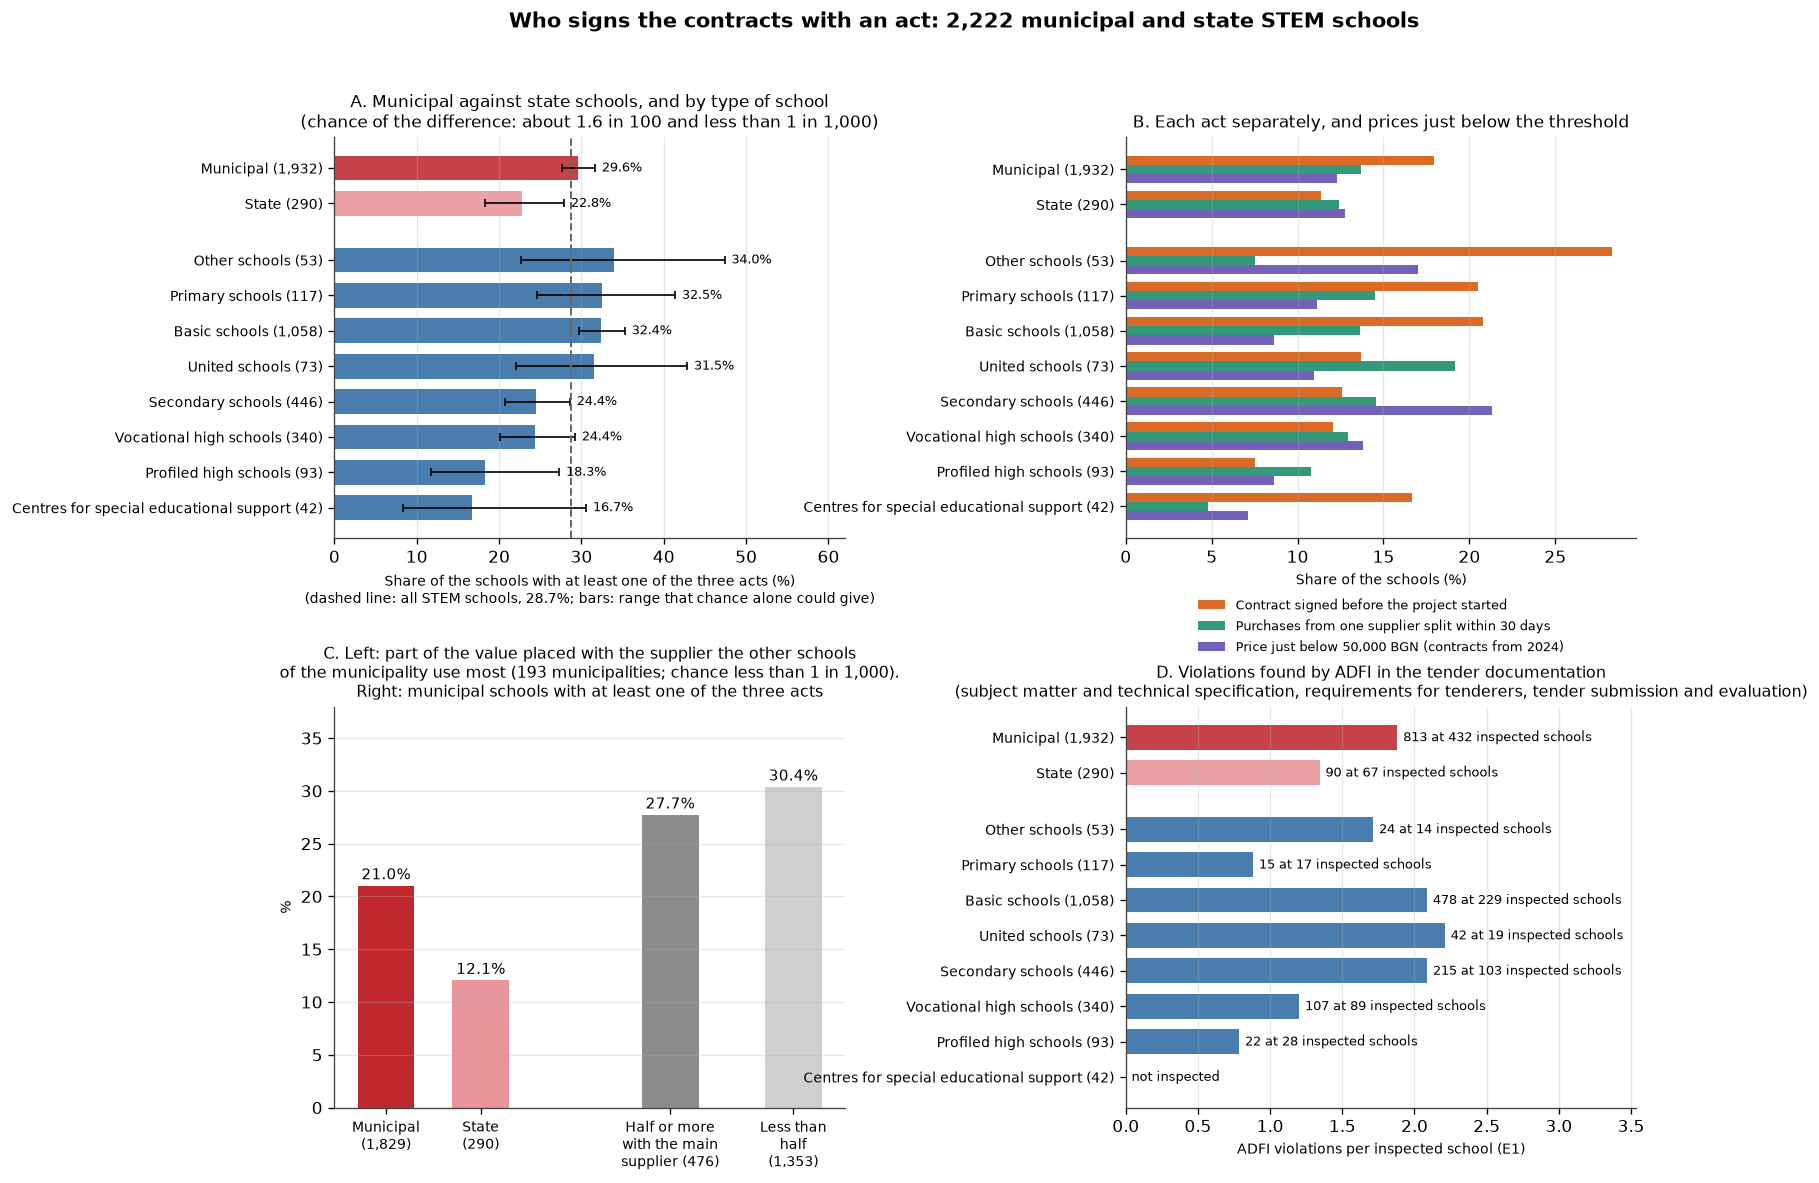

In [18]:
# Figure F2_3: who signs the contracts with an act, and where ADFI finds violations in the documentation; every number in the figure is taken from this run.
grp_rows = []
for lab in ["Municipal", "State"]:
    g = si63[si63["fund_en"] == lab]
    grp_rows.append((lab, g))
for lab in t_tbl["label_en"]:
    grp_rows.append((lab, si63[si63["type_en"] == lab]))
plot63 = []
for lab, g in grp_rows:
    k, n = int(g["flag_level1"].sum()), int(len(g))
    p_, lo_, hi_ = wilson_ci(k, n)
    short = lab if lab in ("Municipal", "State") else plain(lab)[:1].upper() + plain(lab)[1:]
    plot63.append({"label": f"{short} ({n:,})", "pct": p_ * 100, "lo": lo_ * 100, "hi": hi_ * 100,
                   "pre": g["flag_predated"].mean() * 100, "spl": g["flag_split_30d"].mean() * 100,
                   "b50": g["flag_bunching_50k"].mean() * 100, "is_fund": lab in ("Municipal", "State"), "key": lab})
plot63 = pd.DataFrame(plot63)
y63 = np.arange(len(plot63))[::-1].astype(float)
y63[2:] -= 0.6
nat63 = float(sch_inst["flag_level1"].mean() * 100.0)

fig, axs = plt.subplots(2, 2, figsize=(14, 10.5), gridspec_kw={"hspace": 0.42, "wspace": 0.55})
(axA, axB), (axC, axD) = axs

colA = ["#c0282e" if k == "Municipal" else "#e8959a" if k == "State" else "#2e6ba3" for k in plot63["key"]]
axA.barh(y63, plot63["pct"], color=colA, alpha=0.88, height=0.7)
axA.errorbar(plot63["pct"], y63, xerr=[plot63["pct"] - plot63["lo"], plot63["hi"] - plot63["pct"]],
             fmt="none", ecolor="black", elinewidth=1.0, capsize=2.5)
for yy, r in zip(y63, plot63.itertuples()):
    axA.text(r.hi + 0.8, yy, f"{r.pct:.1f}%", va="center", fontsize=8)
axA.axvline(nat63, color="dimgray", ls="--", lw=1.2)
axA.set_yticks(y63, plot63["label"], fontsize=8.5)
axA.set_xlim(0, 62)
axA.set_xlabel(f"Share of the schools with at least one of the three acts (%)\n(dashed line: all STEM schools, {nat63:.1f}%; bars: range that chance alone could give)", fontsize=8.5)
axA.set_title(f"A. Municipal against state schools, and by type of school\n(chance of the difference: {chance_text(p_f_all)} and {chance_text(p_t_all)})", fontsize=10)

bh = 0.26
axB.barh(y63 + bh, plot63["pre"], height=bh, color="#d96b26", label="Contract signed before the project started")
axB.barh(y63, plot63["spl"], height=bh, color="#33997a", label="Purchases from one supplier split within 30 days")
axB.barh(y63 - bh, plot63["b50"], height=bh, color="#7361b8", label="Price just below 50,000 BGN (contracts from 2024)")
axB.set_yticks(y63, plot63["label"], fontsize=8.5)
axB.set_xlabel("Share of the schools (%)", fontsize=8.5)
axB.set_title("B. Each act separately, and prices just below the threshold", fontsize=10)
axB.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, frameon=False)

c_lab = ["Municipal schools", "State schools"]
c_val = [muni_mean * 100, state_mean * 100]
axC.bar([0, 1], c_val, color=["#c0282e", "#e8959a"], width=0.6)
for xx, v in zip([0, 1], c_val):
    axC.text(xx, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9)
axC.bar([3, 4.3], [l1_hi, l1_lo], color=["#8c8c8c", "#cfcfcf"], width=0.6)
for xx, v in zip([3, 4.3], [l1_hi, l1_lo]):
    axC.text(xx, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9)
axC.set_xticks([0, 1, 3, 4.3], [f"Municipal\n({n_m_tot:,})", f"State\n({n_s_tot:,})",
                               f"Half or more\nwith the main\nsupplier ({len(ha_hi):,})", f"Less than\nhalf\n({len(ha_lo):,})"], fontsize=8.5)
axC.set_ylabel("%", fontsize=8.5)
axC.set_ylim(0, max(c_val + [l1_hi, l1_lo]) * 1.25)
axC.set_title(f"C. Left: part of the value placed with the supplier the other schools\nof the municipality use most ({n_munis_loo} municipalities; chance {chance_text(p_obsz)}).\n"
              "Right: municipal schools with at least one of the three acts", fontsize=9.5)

d_rows = [("Municipal", int(insp.loc["Municipal", "aud"]), int(v24_f["Municipal"])), ("State", int(insp.loc["State", "aud"]), int(v24_f["State"]))]
d_rows += [(lab, int(v24_tbl.loc[lab, "inspected"]) if lab in v24_tbl.index else 0,
            int(v24_tbl.loc[lab, "violations_24"]) if lab in v24_tbl.index else 0) for lab in t_tbl["label_en"]]
d_per = [v / a if a else 0.0 for _, a, v in d_rows]
axD.barh(y63, d_per, color=colA, alpha=0.88, height=0.7)
for yy, (lab, a, v), pv in zip(y63, d_rows, d_per):
    axD.text(pv + 0.04, yy, f"{v} at {a} inspected schools" if a else "not inspected", va="center", fontsize=8)
axD.set_yticks(y63, plot63["label"], fontsize=8.5)
axD.set_xlim(0, max(d_per) * 1.6)
axD.set_xlabel("ADFI violations per inspected school (E1)", fontsize=8.5)
axD.set_title(f"D. Violations found by ADFI in the tender documentation\n({SEC_NAMES})", fontsize=9.5)

for ax in axs.flat:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="x" if ax is not axC else "y", alpha=0.3)
fig.suptitle(f"Who signs the contracts with an act: {len(si63):,} municipal and state STEM schools", fontsize=12.5, fontweight="bold")
fig.savefig(FIG_DIR / "F2_3_institutional_profile.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Public data against the ADFI findings of Element 1: class, school and supplier

**What is done.** The three acts of Section 4.5 (signing the contract before the project started, splitting purchases from one supplier within 30 days, and awarding a contract directly although its value required a call or a procedure) and the prices just below the threshold of Section 5 are compared with the ADFI inspection reports on the STEM schools classified in Element 1 (`adfi-violations-classification@c9bd90d`). The comparison is made on three levels:
- **Level A, by class of Element 1.** For each act, the schools with the act are split into inspected and not inspected. The inspected ones are then split by what ADFI recorded in the classes of Element 1 that correspond to the same act (Section 3): a violation, only "no violation", or no finding.
- **Level B, by school.** Among the inspected schools with a finding in Element 1, the share with an act of ADFI is compared between the schools with each act and all of them. ADFI issues an act at most of the schools it inspects, so this share can rise only a little above its overall level; that limit is shown next to each result. The chance of each difference is measured twice: exactly, and by reshuffling the acts of ADFI among the schools. It is also checked whether ADFI chose the schools with an act for inspection more often than the others.
- **Level C, by school and supplier.** In the schools whose reports name a supplier (by its company number or its name in the verbatim text of Element 1), every pair of a school and one of its suppliers is marked as cited by ADFI, and as cited with a violation. The pairs with a contract with an act are compared with all pairs: the chance is measured exactly, by reshuffling only among the suppliers of the same school, and with the value and number of contracts of the pair taken into account. The suppliers cited are listed by name. The pairs are few, so this level has little power.

The three levels are saved in `data/derived/T2_2_adfi_validation.csv`. The school level must reproduce `adfi_validation_results.csv`, prepared in Section 1, which is only read here.

**Why this matters for Element 1.** ADFI inspects after the contract is signed and paid, and most of its findings concern the tender documentation. The acts measured in the public data are checked by the school's financial controller before the commitment is taken (Art. 13(3) FMCPSA). This section shows whether the inspection after the fact records these acts at the schools where the public data show them, and how many schools with these acts it never reaches.

**Figure F2_4.** Panel A shows, for each act and for prices just below the threshold, the part of the schools with the act that ADFI never inspected, inspected without a finding on the act, inspected and wrote "no violation", and inspected and found a violation in the class of the same act. Panel B shows the share of inspected schools with an act of ADFI for each act, against the share for all inspected schools; 100 % is the most any group can reach. Panel C shows how often ADFI inspected the schools with an act and the schools without one, and the value of the contracts with an act at the schools never inspected. Panel D shows the suppliers with the most contracts with an act: at how many schools they signed them, how many of these schools ADFI inspected, and at how many it cites the supplier with a violation.

In [19]:
# Section 7: public-data indicators against the ADFI findings of Element 1 on three levels (A: by E1 class, B: school, C: school-supplier pair) -> T2_2_adfi_validation.csv.
isun_to_reg = project_classes.set_index("school_bulstat_isun")["school_bulstat"].to_dict()
stem_bulstats = set(sch_reg["school_bulstat"])
reg_bulstats = set(schools_register["Булстат"])

norm_rep = lambda s: re.sub(r"(?:pdf)?\.+\s*md$", "", re.sub(r"^(\d{4}/\d{2}/)Доклад\s+", r"\1", re.sub(r"^00\.\s*АДФИ[\\/]", "", str(s)).replace("\\", "/")))
norm_s = lambda s: " ".join(re.sub(r"\s+", " ", str(s).lower().replace("гр.", " ").replace("с.", " ")).split())
norm_cn = lambda n, l: " ".join(w for w in re.sub(r"[^а-яa-z0-9]+", " ", str(n).lower()).split() if len(w) > 1 and w not in {"оу", "су", "ну", "пг", "проф", "гр", "с", "училище", "гимназия"})

sch_lookup_adfi = schools_register[["Булстат", "Пълно наименование на институция", "Населено място"]].drop_duplicates("Булстат").copy()
sch_lookup_adfi["sett_n"] = sch_lookup_adfi["Населено място"].map(norm_s)
sch_lookup_adfi["canon_n"] = [norm_cn(n, l) for n, l in zip(sch_lookup_adfi["Пълно наименование на институция"], sch_lookup_adfi["Населено място"])]

matched_b, matched_stage = [], []
for _, row in adfi_meta.iterrows():
    ek = str(row["eik"]).strip()
    if ek in stem_bulstats:
        matched_b.append(ek)
        matched_stage.append("bulstat")
    elif ek in isun_to_reg:
        matched_b.append(isun_to_reg[ek])
        matched_stage.append("bulstat_isun_map")
    elif ek in reg_bulstats:
        matched_b.append(ek)
        matched_stage.append("bulstat_non_stem")
    else:
        sn = norm_s(row["locality"])
        cn = norm_cn(row["school"], row["locality"])
        cand = sch_lookup_adfi[sch_lookup_adfi["sett_n"] == sn]
        best_b, best_sc, sec_sc = "", -1.0, -1.0
        for _, cr in cand.iterrows():
            s_r = SequenceMatcher(None, cn, cr["canon_n"]).ratio()
            t1, t2 = set(cn.split()), set(cr["canon_n"].split())
            sc = 0.5 * s_r + 0.5 * (len(t1 & t2) / max(len(t1 | t2), 1))
            if sc > best_sc:
                sec_sc, best_sc, best_b = best_sc, sc, cr["Булстат"]
            elif sc > sec_sc:
                sec_sc = sc
        if best_sc >= 0.55 and (best_sc - sec_sc) >= 0.05:
            matched_b.append(best_b)
            matched_stage.append("name_settlement")
        else:
            matched_b.append("")
            matched_stage.append("none")

adfi_m = adfi_meta.copy()
adfi_m["school_bulstat"] = matched_b
adfi_m["match_stage"] = matched_stage
adfi_m["school_in_stem"] = adfi_m["school_bulstat"].isin(stem_bulstats)
adfi_m["rk_base"] = adfi_m["report_key"].str.replace(r"-\[\d+\]$", "", regex=True)

rk_to_sch = adfi_m.set_index("report_key")[["school_bulstat", "directorate_bg", "match_stage"]].to_dict("index")
base_to_sch = adfi_m.set_index("rk_base")[["school_bulstat", "directorate_bg", "match_stage"]].to_dict("index")

cls_full = adfi_cls.copy()
cls_full["rk_norm"] = cls_full["report_id"].map(norm_rep)
cls_full["school_bulstat"] = [rk_to_sch.get(k, base_to_sch.get(k, {})).get("school_bulstat", "") for k in cls_full["rk_norm"]]
cls_full["verb_text"] = adfi_verb["Основа (дословно)"].astype(str) + " || " + adfi_verb["Извод (дословно)"].astype(str)

rk_map = {"violation_with_act": 3, "violation_without_act": 2, "no_violation": 1}
cls_full["rk"] = cls_full["outcome"].map(rk_map).fillna(0).astype(int)

adfi_stem_m = adfi_m[adfi_m["school_in_stem"]].copy()
cls_stem = cls_full[cls_full["school_bulstat"].isin(stem_bulstats)].copy()
aud_schools_meta = set(adfi_stem_m["school_bulstat"])
# The matching of this section gives the same reports, schools and E1 rows as Section 3 (adfi_matches.csv).
assert len(adfi_stem_m) == n_e1_reports and aud_schools_meta == set(stem_reports["school_bulstat"])
assert cls_stem.groupby("school_bulstat").size().sort_index().equals(e1_stem.groupby("school_bulstat").size().sort_index())

print(f"E1 total reports: {len(adfi_m)}; matched to STEM schools: {len(adfi_stem_m)} reports across {len(aud_schools_meta)} unique schools ({adfi_stem_m['match_stage'].value_counts().to_dict()}).")

sch_adfi = sch_reg.copy()
sch_adfi["audited_meta"] = sch_adfi["school_bulstat"].isin(aud_schools_meta)
sch_rk = cls_stem.groupby("school_bulstat")["rk"].max()
sch_adfi["adfi_rk"] = sch_adfi["school_bulstat"].map(sch_rk).fillna(-1).astype(int)
lab_sch = sch_adfi[sch_adfi["adfi_rk"] >= 1].copy()
sanc_arr = (lab_sch["adfi_rk"] == 3).to_numpy()
base_act_rate = float(sanc_arr.mean())
max_lift = 1.0 / base_act_rate
print(f"Level B classified STEM schools: N={len(lab_sch)}, with act K={int(sanc_arr.sum())} ({base_act_rate:.2%}), base-rate ceiling lift = {max_lift:.3f}")

IND_7 = (
    ("Level 1 union", "flag_level1"),
    ("predated", "flag_predated"),
    ("split_30d", "flag_split_30d"),
    ("regime_mismatch", "flag_regime_mismatch"),
    ("bunching_50k", "flag_bunching_50k"),
)
N_PERM_7 = 10000
rng_7 = np.random.default_rng(RNG_STATE)
null_act_7 = np.array([rng_7.permutation(sanc_arr) for _ in range(N_PERM_7)])

level_b_rows = []
for lbl, col in IND_7:
    fl_lab = lab_sch[col].to_numpy()
    n_f, k_f = int(fl_lab.sum()), int((sanc_arr & fl_lab).sum())
    prec = k_f / n_f if n_f else np.nan
    rec = k_f / int(sanc_arr.sum())
    lift = prec / base_act_rate if n_f else np.nan
    p_hyp = float(stats.hypergeom.sf(k_f - 1, len(lab_sch), int(sanc_arr.sum()), n_f)) if n_f else np.nan
    p_perm = (1 + int((null_act_7[:, fl_lab].sum(axis=1) >= k_f).sum())) / (N_PERM_7 + 1) if n_f else np.nan

    a11 = int((sch_adfi["audited_meta"] & sch_adfi[col]).sum())
    a10 = int((sch_adfi["audited_meta"] & ~sch_adfi[col]).sum())
    a01 = int((~sch_adfi["audited_meta"] & sch_adfi[col]).sum())
    a00 = int((~sch_adfi["audited_meta"] & ~sch_adfi[col]).sum())
    sel_or, sel_p = stats.fisher_exact([[a11, a10], [a01, a00]])

    level_b_rows.append({
        "indicator": lbl,
        "flagged_stem_schools": int(sch_adfi[col].sum()),
        "audited_meta_schools": a11,
        "unaudited_schools": a01,
        "classified_N": len(lab_sch),
        "classified_act_K": int(sanc_arr.sum()),
        "flagged_classified_n": n_f,
        "flagged_act_k": k_f,
        "base_rate": round(base_act_rate, 6),
        "precision": round(prec, 6),
        "recall": round(rec, 6),
        "lift": round(lift, 6),
        "max_lift": round(max_lift, 6),
        "p_hypergeometric": round(p_hyp, 6),
        "p_permutation": round(p_perm, 6),
        "selection_OR": round(float(sel_or), 4),
        "selection_p": round(float(sel_p), 6),
    })
t22_b = pd.DataFrame(level_b_rows)

# adfi_validation_results.csv (prepared in Section 1) is read, not rewritten: the school level computed here must reproduce it.
avr_prep = pd.read_csv(DERIVED_DIR / "adfi_validation_results.csv", dtype={"flag_set": str})
assert avr_prep["flag_set"].tolist() == t22_b["indicator"].tolist()
for c_p, c_b in (("N", "classified_N"), ("K", "classified_act_K"), ("n", "flagged_classified_n"), ("k", "flagged_act_k")):
    assert avr_prep[c_p].tolist() == t22_b[c_b].tolist()
for c_p in ("base_rate", "precision", "recall", "lift", "p_hypergeometric"):
    assert np.allclose(avr_prep[c_p].to_numpy(), t22_b[c_p].to_numpy(), atol=1e-6)
print("\nLevel B — School-level validation & audit selection (reproduces adfi_validation_results.csv):")
display(t22_b)

# Level A: for each indicator, the audited schools by what ADFI recorded in the E1 classes of the same act (Section 3, concepts_mapping.csv).
own_cls = {r["indicator"]: [c.strip() for c in r["e1_classes"].split(";")] for _, r in concepts_df.iterrows()}
own_cls["Level 1 union"] = sorted(set(own_cls["predated"]) | set(own_cls["split_30d"]) | set(own_cls["regime_mismatch"]))
level_a_rows = []
for lbl, col in IND_7:
    ind_s = set(sch_adfi.loc[sch_adfi[col], "school_bulstat"])
    aud_s = ind_s & aud_schools_meta
    for cidx in own_cls[lbl] + ["all classes of the act"]:
        cl_set = own_cls[lbl] if cidx == "all classes of the act" else [cidx]
        sub = cls_stem[cls_stem["school_bulstat"].isin(aud_s) & cls_stem["class_index"].isin(cl_set)]
        v_s = set(sub.loc[sub["outcome"].isin(["violation_with_act", "violation_without_act"]), "school_bulstat"])
        a_s = set(sub.loc[sub["outcome"] == "violation_with_act", "school_bulstat"])
        nv_s = set(sub.loc[sub["outcome"] == "no_violation", "school_bulstat"]) - v_s
        level_a_rows.append({
            "indicator": lbl,
            "e1_class": cidx,
            "flagged_schools": len(ind_s),
            "audited": len(aud_s),
            "unaudited": len(ind_s) - len(aud_s),
            "violation": len(v_s),
            "violation_with_act": len(a_s),
            "no_violation_only": len(nv_s),
            "no_finding": len(aud_s) - len(v_s) - len(nv_s),
        })
t22_a = pd.DataFrame(level_a_rows)
print("\nLevel A — audited schools with each indicator by ADFI finding in the E1 classes of the same act:")
display(t22_a)

LOOK_TRANS = str.maketrans("abcehkmoptxyABCEHKMOPTXY", "авсенкмортхуАВСЕНКМОРТХУ")
RE_PUNCT = re.compile(r"[„“”\x22«»\x27`.,;:()\[\]/\\|\-–—]+")
LEGAL_TOKENS = {"еоод", "оод", "ад", "еад", "дззд", "сд", "кд", "ет", "кооперация"}
nf_firm = lambda s: " ".join(t for t in RE_PUNCT.sub(" ", str(s).translate(LOOK_TRANS).lower()).split() if t not in LEGAL_TOKENS)
RE_Q = re.compile(r"(?:,,|[„\x22“”«])([^„\x22“”«»\n,;]{3,70}?)[“\x22”»]")
RE_E = re.compile(r"(?<!\d)(\d{9})(?!\d)")

pre_sup_path = DERIVED_DIR / "adfi_supplier_matches.csv"
pre_sup = pd.read_csv(pre_sup_path, dtype=str, keep_default_na=False) if pre_sup_path.exists() else pd.DataFrame()
pre_cited = {(r["school_bulstat"], r["vendor_id"]): r["cited_violation"] == "True" for _, r in pre_sup.iterrows()}

sv_map = (
    c_eval[c_eval["vendor_id"] != ""].drop_duplicates(["school_bulstat", "vendor_id"])
    .groupby("school_bulstat")
    .apply(lambda g: list(zip(g["vendor_id"], g["vendor_eik"], g["vendor_name"].map(lambda x: "" if "заличено" in str(x) else nf_firm(x)))), include_groups=False)
    .to_dict()
)
pair_hits = {}
for sb, grp in cls_stem.groupby("school_bulstat"):
    vends = sv_map.get(sb, [])
    for _, cr in grp.iterrows():
        tr = str(cr["verb_text"])
        tn = " " + nf_firm(tr) + " "
        es = set(RE_E.findall(tr))
        qs = [nf_firm(m.group(1)) for m in RE_Q.finditer(tr)]
        is_v = cr["outcome"] in ("violation_with_act", "violation_without_act")
        for vid, veik, vn in vends:
            hit = (bool(veik) and veik in es) or (len(vn) >= 4 and f" {vn} " in tn) or any(len(q) >= 4 and (q == vn or SequenceMatcher(None, q, vn).ratio() >= 0.75) for q in qs)
            if (sb, vid) in pre_cited:
                hit = True
                is_v = is_v or pre_cited[(sb, vid)]
            if hit:
                cur = pair_hits.setdefault((sb, vid), {"cited": True, "viol": False})
                if is_v:
                    cur["viol"] = True

named_schools = {k[0] for k in pair_hits}
pairs_df = c_eval[(c_eval["vendor_id"] != "") & c_eval["school_bulstat"].isin(named_schools)].groupby(["school_bulstat", "vendor_id"]).agg(
    contracts=("contract_row", "count"),
    val_incl=("amount_eur_incl_vat", "sum"),
    l1=("flag_level1", "any"),
    vendor_eik=("vendor_eik", "first"),
    vendor_name=("vendor_name", "first"),
).reset_index()
pairs_df["cited"] = [(r["school_bulstat"], r["vendor_id"]) in pair_hits for _, r in pairs_df.iterrows()]
pairs_df["cited_violation"] = [pair_hits.get((r["school_bulstat"], r["vendor_id"]), {}).get("viol", False) for _, r in pairs_df.iterrows()]

n_c_pairs = int(len(pairs_df))
k_c_cited = int(pairs_df["cited"].sum())
k_c_viol = int(pairs_df["cited_violation"].sum())
fl_c = pairs_df["l1"].to_numpy()
cv_c = pairs_df["cited_violation"].to_numpy()
n_c_l1 = int(fl_c.sum())
k_c_l1_v = int((fl_c & cv_c).sum())
rate_c_base = k_c_viol / n_c_pairs if n_c_pairs else 0.0
rate_c_l1 = k_c_l1_v / n_c_l1 if n_c_l1 else 0.0
lift_c = rate_c_l1 / rate_c_base if rate_c_base > 0 else np.nan
p_c_hyp = float(stats.hypergeom.sf(k_c_l1_v - 1, n_c_pairs, k_c_viol, n_c_l1)) if n_c_l1 > 0 else np.nan

# Permutation p for the pairs: the cited violations are shuffled only among the suppliers of the same school.
c_blocks = [np.flatnonzero(pd.factorize(pairs_df["school_bulstat"])[0] == g) for g in range(pairs_df["school_bulstat"].nunique())]
null_c = np.empty(N_PERM_7, dtype=int)
for p_i in range(N_PERM_7):
    cv_sh = cv_c.copy()
    for blk in c_blocks:
        cv_sh[blk] = cv_c[rng_7.permutation(blk)]
    null_c[p_i] = int((cv_sh & fl_c).sum())
p_c_perm = (1 + int((null_c >= k_c_l1_v).sum())) / (N_PERM_7 + 1)

pairs_df["log_val"] = np.log1p(pairs_df["val_incl"])
pairs_df["log_cnt"] = np.log(pairs_df["contracts"])
lfit_c = sm.Logit(pairs_df["cited_violation"].astype(float), sm.add_constant(pairs_df[["l1", "log_val", "log_cnt"]].astype(float))).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(pairs_df["school_bulstat"])[0]}
)
or_c_l1 = float(np.exp(lfit_c.params["l1"]))
p_c_logit = float(lfit_c.pvalues["l1"])

print(f"\nLevel C — Verbatim ADFI supplier mentions across {len(named_schools)} named STEM schools:")
print(f"  All (school, vendor) pairs N = {n_c_pairs}; cited = {k_c_cited}; cited with violation = {k_c_viol} ({rate_c_base:.2%}).")
print(f"  Level 1 flagged pairs: {k_c_l1_v}/{n_c_l1} = {rate_c_l1:.2%} (lift = {lift_c:.3f}, hypergeometric p = {p_c_hyp:.4f}, permutation p within school = {p_c_perm:.4f}; "
      f"Logit OR = {or_c_l1:.2f} with contract value and number fixed, cluster p = {p_c_logit:.4f}).")
print(f"  Limitation: with N = {n_c_pairs} pairs and {n_c_l1} Level 1 pairs the test has low power.")

sch_names_7 = schools.set_index("school_bulstat")["school_name"]
sup_profile = pairs_df[pairs_df["cited"]].assign(school_name=lambda d: d["school_bulstat"].map(sch_names_7)).sort_values(
    ["l1", "cited_violation", "val_incl"], ascending=[False, False, False])[
    ["school_name", "vendor_name", "vendor_eik", "contracts", "val_incl", "l1", "cited_violation"]].reset_index(drop=True)
print(f"\nLevel C — named profile of the {len(sup_profile)} suppliers cited by ADFI (school, supplier, contracts, value EUR incl. VAT, Level 1, cited with violation):")
display(sup_profile)

t22_c = pd.DataFrame([{
    "indicator": "Level 1 union", "N": n_c_pairs, "K": k_c_viol, "n": n_c_l1, "k": k_c_l1_v,
    "base_rate": round(rate_c_base, 6), "precision": round(rate_c_l1, 6), "lift": round(lift_c, 6),
    "p_hypergeometric": round(p_c_hyp, 6), "p_permutation": round(p_c_perm, 6),
    "logit_OR": round(or_c_l1, 4), "logit_p": round(p_c_logit, 6),
}])
B_TO_FILE = {"flagged_stem_schools": "flagged_schools", "audited_meta_schools": "audited", "unaudited_schools": "unaudited",
             "classified_N": "N", "classified_act_K": "K", "flagged_classified_n": "n", "flagged_act_k": "k"}
t22_df = pd.concat([
    t22_a.assign(level="A", unit="school"),
    t22_b.rename(columns=B_TO_FILE).assign(level="B", unit="school"),
    t22_c.assign(level="C", unit="school-supplier pair"),
], ignore_index=True)
T22_COLS = ["level", "unit", "indicator", "e1_class", "flagged_schools", "audited", "unaudited", "violation", "violation_with_act", "no_violation_only", "no_finding",
            "N", "K", "n", "k", "base_rate", "precision", "recall", "lift", "max_lift", "p_hypergeometric", "p_permutation", "selection_OR", "selection_p", "logit_OR", "logit_p"]
assert set(t22_df.columns) == set(T22_COLS)
t22_df = t22_df[T22_COLS]
for c_i in ("flagged_schools", "audited", "unaudited", "violation", "violation_with_act", "no_violation_only", "no_finding", "N", "K", "n", "k"):
    t22_df[c_i] = t22_df[c_i].astype("Int64")
t22_df.to_csv(DERIVED_DIR / "T2_2_adfi_validation.csv", index=False, encoding="utf-8", lineterminator="\n")

row_l1 = t22_b[t22_b["indicator"] == "Level 1 union"].iloc[0]
row_pr = t22_b[t22_b["indicator"] == "predated"].iloc[0]
row_a1 = t22_a[(t22_a["indicator"] == "Level 1 union") & (t22_a["e1_class"] == "all classes of the act")].iloc[0]
record_conclusion("Section 7", "adfi_validation", "ADFI reports matched to STEM", int(len(adfi_stem_m)))
record_conclusion("Section 7", "adfi_validation", "ADFI audited STEM schools (meta)", int(len(aud_schools_meta)))
record_conclusion("Section 7", "adfi_validation", "ADFI classified STEM schools (E1)", int(len(lab_sch)))
record_conclusion("Section 7", "adfi_validation", "ADFI violation-with-act schools", int(sanc_arr.sum()))
record_conclusion("Section 7", "adfi_validation", "ADFI act base rate (%)", f"{base_act_rate * 100.0:.2f}", "", "", "max_lift", f"{max_lift:.3f}")
record_conclusion("Section 7", "adfi_validation", "ADFI base-rate ceiling lift", f"{max_lift:.3f}")
record_conclusion("Section 7", "adfi_validation", "Level 1 flagged audited STEM schools", int(row_l1["audited_meta_schools"]))
record_conclusion("Section 7", "adfi_validation", "Level 1 flagged unaudited STEM schools", int(row_l1["unaudited_schools"]))
record_conclusion("Section 7", "adfi_validation", "Level 1 audited schools with a violation in the classes of the act", int(row_a1["violation"]))
record_conclusion("Section 7", "adfi_validation", "Level 1 audited schools with only no violation in the classes of the act", int(row_a1["no_violation_only"]))
record_conclusion("Section 7", "adfi_validation", "Level 1 audited schools with no finding in the classes of the act", int(row_a1["no_finding"]))
record_conclusion("Section 7", "adfi_validation", "Level 1 ADFI act lift", f"{row_l1['lift']:.4f}", "", "", "hypergeom", f"p={row_l1['p_hypergeometric']:.4f}; p_perm={row_l1['p_permutation']:.4f}")
record_conclusion("Section 7", "adfi_validation", "Level 1 ADFI selection OR", f"{row_l1['selection_OR']:.3f}", "", "", "Fisher exact", f"p={row_l1['selection_p']:.4f}")
record_conclusion("Section 7", "adfi_validation", "Predated ADFI act lift", f"{row_pr['lift']:.4f}", "", "", "hypergeom", f"p={row_pr['p_hypergeometric']:.4f}; p_perm={row_pr['p_permutation']:.4f}")
record_conclusion("Section 7", "adfi_validation", "Predated ADFI selection OR", f"{row_pr['selection_OR']:.3f}", "", "", "Fisher exact", f"p={row_pr['selection_p']:.4f}")
record_conclusion("Section 7", "adfi_validation", "Level C named STEM schools", int(len(named_schools)))
record_conclusion("Section 7", "adfi_validation", "Level C pairs in named schools", n_c_pairs)
record_conclusion("Section 7", "adfi_validation", "Level C cited with violation pairs", k_c_viol)
record_conclusion("Section 7", "adfi_validation", "Level C Level 1 violation lift", f"{lift_c:.3f}", "", "", "Logit cluster OR", f"{or_c_l1:.2f} (p_hyp={p_c_hyp:.4f}; p_perm={p_c_perm:.4f}; p_logit={p_c_logit:.4f})")
flush_conclusions()

E1 total reports: 560; matched to STEM schools: 558 reports across 499 unique schools ({'bulstat': 515, 'bulstat_isun_map': 43}).
Level B classified STEM schools: N=459, with act K=381 (83.01%), base-rate ceiling lift = 1.205

Level B — School-level validation & audit selection (reproduces adfi_validation_results.csv):


,indicator,flagged_stem_schools,audited_meta_schools,unaudited_schools,classified_N,classified_act_K,flagged_classified_n,flagged_act_k,base_rate,precision,recall,lift,max_lift,p_hypergeometric,p_permutation,selection_OR,selection_p
0,Level 1 union,638,180,458,459,381,168,145,0.830065,0.863095,0.380577,1.039792,1.204724,0.095284,0.092391,1.5585,0.000051
1,predated,380,124,256,459,381,117,105,0.830065,0.897436,0.275591,1.081163,1.204724,0.014888,0.015698,1.8949,0.000001
2,split_30d,300,72,228,459,381,66,53,0.830065,0.803030,0.139108,0.967430,1.204724,0.793575,0.799420,1.1056,0.503346
3,regime_mismatch,17,4,13,459,381,4,4,0.830065,1.000000,0.010499,1.204724,1.204724,0.473457,0.472953,1.0629,1.000000
4,bunching_50k,274,70,204,459,381,66,56,0.830065,0.848485,0.146982,1.022190,1.204724,0.410382,0.410859,1.2150,0.189520



Level A — audited schools with each indicator by ADFI finding in the E1 classes of the same act:


,indicator,e1_class,flagged_schools,audited,unaudited,violation,violation_with_act,no_violation_only,no_finding
0,Level 1 union,1.01,638,180,458,7,7,4,169
1,Level 1 union,1.02,638,180,458,3,3,2,175
2,Level 1 union,10.01,638,180,458,3,3,1,176
3,Level 1 union,10.02,638,180,458,2,2,1,177
4,Level 1 union,7.03,638,180,458,0,0,0,180
5,Level 1 union,all classes of the act,638,180,458,11,11,6,163
6,predated,10.01,380,124,256,1,1,1,122
7,predated,10.02,380,124,256,1,1,1,122
8,predated,7.03,380,124,256,0,0,0,124
9,predated,all classes of the act,380,124,256,1,1,1,122



Level C — Verbatim ADFI supplier mentions across 37 named STEM schools:
  All (school, vendor) pairs N = 102; cited = 39; cited with violation = 36 (35.29%).
  Level 1 flagged pairs: 7/13 = 53.85% (lift = 1.526, hypergeometric p = 0.1187, permutation p within school = 0.1973; Logit OR = 2.20 with contract value and number fixed, cluster p = 0.4146).
  Limitation: with N = 102 pairs and 13 Level 1 pairs the test has low power.

Level C — named profile of the 39 suppliers cited by ADFI (school, supplier, contracts, value EUR incl. VAT, Level 1, cited with violation):


,school_name,vendor_name,vendor_eik,contracts,val_incl,l1,cited_violation
0,"Основно училище ""Свети княз Борис І""",",,А1 България“ ЕАД",131468980,2,115262.160000,True,True
1,"Второ основно училище ""Христо Смирненски""",",,А1 България“ ЕАД",131468980,3,74565.190000,True,True
2,"Основно училище ""Христо Смирненски""",",,А1 България“ ЕАД",131468980,4,69522.730000,True,True
3,"Основно училище ""Христо Смирненски""",ДЕЗОН--БГ ЕООД,200790030,3,68840.220000,True,True
4,"Първо основно училище ""Свети Климент Охридски""",БАЛИСТИК СЕЛ ЕООД,201055457,2,67185.990000,True,True
5,"Начално училище""Васил Левски""",",,А1 България“ ЕАД",131468980,2,59875.756073,True,True
6,Основно училище Иван Вазов,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,203902794,1,14725.210000,True,True
7,"Основно училище ""Св.св.Кирил и Методий""",",,А1 България“ ЕАД",131468980,3,76625.284406,True,False
8,"Втора английска езикова гимназия ""Томас Джефер...",Алегро Пловдив ООД,203791792,1,184536.000000,False,True
9,"Средно училище ""Цанко Церковски""",",,А1 България“ ЕАД",131468980,2,162648.972000,False,True


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
147,Section 7,adfi_validation,Predated ADFI selection OR,1.895,,,Fisher exact,p=0.0000
148,Section 7,adfi_validation,Level C named STEM schools,37,,,none,none
149,Section 7,adfi_validation,Level C pairs in named schools,102,,,none,none
150,Section 7,adfi_validation,Level C cited with violation pairs,36,,,none,none


In [20]:
# Economic conclusions of Section 7: every figure is taken from this run; H2 comes from Section 4.5, the municipal and state schools from Section 6.3 and the STEM-only E1 rows (e1_stem) from Section 3.
ACT_7 = {
    "predated": "contracts signed before the project started",
    "split_30d": "purchases from one supplier split within 30 days",
    "regime_mismatch": "direct awards above the threshold",
    "bunching_50k": "prices just below the threshold",
}
b7 = t22_b.set_index("indicator")
a7 = t22_a[t22_a["e1_class"] == "all classes of the act"].set_index("indicator")
a7c = t22_a.set_index(["indicator", "e1_class"])
l1b, prb = b7.loc["Level 1 union"], b7.loc["predated"]
l1a = a7.loc["Level 1 union"]

n_sch_7 = int(len(sch_adfi))
n_aud_all = int(sch_adfi["audited_meta"].sum())
n_l1_7 = int(sch_adfi["flag_level1"].sum())
n_aud_l1 = int(l1b["audited_meta_schools"])
n_aud_no = n_aud_all - n_aud_l1
n_no_l1 = n_sch_7 - n_l1_7

unaud_l1 = set(sch_adfi.loc[sch_adfi["flag_level1"] & ~sch_adfi["audited_meta"], "school_bulstat"])
ce_un = c_eval[c_eval["flag_level1"] & c_eval["school_bulstat"].isin(unaud_l1)]
val_un = float(ce_un["amount_eur_incl_vat"].sum())
paid_un = float(ce_un["paid_alloc_eur_incl_vat"].sum())


def other_viol(lbl, col):
    """Inspected schools with the act at which ADFI found a violation only in other classes of Element 1."""
    aud_s = set(sch_adfi.loc[sch_adfi[col], "school_bulstat"]) & aud_schools_meta
    sub = cls_stem[cls_stem["school_bulstat"].isin(aud_s) & ~cls_stem["class_index"].isin(own_cls[lbl]) & cls_stem["outcome"].str.startswith("violation")]
    return int(sub["school_bulstat"].nunique())


oth7 = {lbl: other_viol(lbl, col) for lbl, col in IND_7}
doc_share = sec_24_viol / stem_e1_viol * 100.0
r106 = e1_stem[e1_stem["class_index"] == "1.06"]
n106, n106_v = int(len(r106)), int(r106["is_violation"].sum())
h2v_7 = h2_df.set_index("indicator")
systemic_7 = [k for k in ("predated", "split_30d", "regime_mismatch") if bool(h2v_7.loc[k, "ci95_lower_over_5pct"])]
fm7 = f_tbl.set_index("label_en").loc["Municipal"]
fs7 = f_tbl.set_index("label_en").loc["State"]


def act_line(k, cls_txt):
    r = a7.loc[k]
    aud, v, nv, nf = int(r["audited"]), int(r["violation"]), int(r["no_violation_only"]), int(r["no_finding"])
    return (f"Of the {int(r['flagged_schools'])} STEM schools with {ACT_7[k]}, ADFI inspected {aud}. At {oth7[k]} of them it found violations in other classes, "
            +
            (f"but a violation in {cls_txt} at only {v} ({v / aud * 100:.1f} %); " if v else f"but none in {cls_txt}; ")
            + f"at {nv} it wrote that there was no violation, and at {nf} ({nf / aud * 100:.1f} %) "
            "it made no finding on this act. ")


# Named profile: the suppliers with the most contracts with an act, against what ADFI recorded about them.
ce_v = c_eval[c_eval["vendor_id"] != ""]
sup7 = ce_v.groupby("vendor_id").agg(
    supplier=("vendor_name", "first"),
    contracts=("contract_row", "count"),
    predated=("flag_predated", "sum"),
    split_30d=("flag_split_30d", "sum"),
    regime_mismatch=("flag_regime_mismatch", "sum"),
    with_act=("flag_level1", "sum"),
)
act_sch = ce_v[ce_v["flag_level1"]].groupby("vendor_id")["school_bulstat"].apply(set)
sup7 = sup7[sup7["with_act"] > 0].copy()
sup7["schools_with_act"] = [len(act_sch[v]) for v in sup7.index]
sup7["inspected_schools_with_act"] = [len(act_sch[v] & aud_schools_meta) for v in sup7.index]
sup7["schools_cited_with_violation"] = [sum(1 for (sb, vid), h in pair_hits.items() if vid == v and h["viol"]) for v in sup7.index]
sup7 = sup7.sort_values(["with_act", "contracts"], ascending=False).reset_index(drop=True)
n_sup_act = int(len(sup7))
n_sup_cited = int((sup7["schools_cited_with_violation"] > 0).sum())
top7 = sup7.head(6)
print(f"Suppliers with at least one contract with an act: {n_sup_act}; of them cited by ADFI with a violation at one or more schools: {n_sup_cited}. The ten with the most contracts with an act:")
display(sup7.head(10))

cited_sch = pairs_df[pairs_df["cited"]].groupby("vendor_name")["school_bulstat"].nunique().sort_values(ascending=False)
top_cited = cited_sch.index[0]
top_cited_act = int(sup7.loc[sup7["supplier"] == top_cited, "with_act"].sum())
top_cited_all = int(ce_v.loc[ce_v["vendor_name"] == top_cited, "contract_row"].count())

lines = [
    f"Of the {n_sch_7:,} STEM schools with contracts, ADFI inspected {n_aud_all} ({n_aud_all / n_sch_7 * 100:.1f} %) and {n_sch_7 - n_aud_all:,} were never inspected. "
    f"Of the {n_l1_7} schools with at least one of the three acts it inspected {n_aud_l1} ({n_aud_l1 / n_l1_7 * 100:.1f} %), against {n_aud_no} of the {n_no_l1:,} schools "
    f"without them ({n_aud_no / n_no_l1 * 100:.1f} %); the chance that this difference arises by accident is {chance_text(l1b['selection_p'])}. "
    f"The other {len(unaud_l1)} schools with an act were never inspected; their contracts with an act are worth EUR {val_un / 1e6:.2f} m, "
    f"of which EUR {(val_un - paid_un) / 1e6:.2f} m has not yet been paid. "
    f"It means that ADFI already inspects the schools with these acts more often, but {len(unaud_l1) / n_l1_7 * 100:.1f} % of them remain outside any inspection: "
    "for them the check of the financial controller before signature is the only control, and part of the money can still be stopped before payment.",
    act_line("split_30d", "the class for split purchases") + (
        "This is one of the acts that H2 found to be systemic. " if "split_30d" in systemic_7 else "")
    + "It means that the inspection after the fact almost never adds up the orders placed with one supplier within 30 days, "
    "although the public data show this sum for every school before the next order is signed.",
    act_line("predated", "the classes for a commitment taken without ex-ante control") + (
        "This is one of the acts that H2 found to be systemic, " if "predated" in systemic_7 else "")
    + f"and Section 6.3 found it more often at municipal schools ({fm7['predated_pct']:.1f} % against {fs7['predated_pct']:.1f} %). "
    "It means that the inspection after the fact almost never records a contract signed before the project started, "
    "although the date of the contract and the start of the project are both before the financial controller at signature.",
    act_line("regime_mismatch", "the class for a wrong procedure") + (
        "H2 found this act to be systemic. " if "regime_mismatch" in systemic_7 else "H2 found this act at too few schools to be systemic. ")
    + "It means that the direct award above the threshold is an isolated error, both in the public data and in the inspections.",
    act_line("bunching_50k", "the classes for split purchases and for an estimated value without market research")
    + f"In all {n106} rows of the class for an estimated value without market research on STEM schools, ADFI recorded "
    + ("no violation. " if n106_v == 0 else f"a violation {n106_v} times. ")
    + "It means that the prices set just below the threshold, found in Section 5, are almost never recorded by the inspection: "
    "the estimated value of the contract is checked by the financial controller before the procedure is chosen.",
    f"Taken together, at the {n_aud_l1} inspected schools with an act ADFI recorded a violation in the classes of the same act at {int(l1a['violation'])} "
    f"({int(l1a['violation']) / n_aud_l1 * 100:.1f} %) and wrote that there was no violation at {int(l1a['no_violation_only'])}; at "
    f"{n_aud_l1 - int(l1a['violation'])} ({(n_aud_l1 - int(l1a['violation'])) / n_aud_l1 * 100:.1f} %) the act measured in the public data led to no violation in the report. "
    f"At {oth7['Level 1 union']} of the same schools ADFI did find violations, and {doc_share:.1f} % of all its violations at STEM schools concern the tender documentation. "
    "It means that the few findings of Element 1 in these classes do not show that the contracts were lawful: they show what the inspection examines, "
    "the documentation of the procedures, and not the moment of the commitment.",
    f"ADFI issued an act at {int(l1b['classified_act_K'])} of the {int(l1b['classified_N'])} inspected schools with a finding in Element 1 ({l1b['base_rate'] * 100:.1f} %), "
    f"so at any group of schools the share with an act can be at most {l1b['max_lift']:.2f} times this level. At the schools with at least one of the three acts it is "
    f"{l1b['precision'] * 100:.1f} % ({int(l1b['flagged_act_k'])} of {int(l1b['flagged_classified_n'])}), {l1b['lift']:.2f} times, with a chance of {chance_text(l1b['p_permutation'])}; "
    f"at the schools that signed before the project started {prb['precision'] * 100:.1f} % ({int(prb['flagged_act_k'])} of {int(prb['flagged_classified_n'])}), "
    f"{prb['lift']:.2f} times, with a chance of {chance_text(prb['p_permutation'])}. "
    + ("It means that the acts of ADFI hardly separate the schools, because ADFI issues an act almost everywhere it inspects; only the schools "
       "that signed before the project started receive more acts than chance would give, and these acts are for other violations."
       if prb["p_permutation"] <= 0.05 < l1b["p_permutation"] else
       "It means that the acts of ADFI hardly separate the schools, because ADFI issues an act almost everywhere it inspects."),
    f"In {len(named_schools)} inspected schools the reports name a supplier of the school; these schools have {n_c_pairs} school–supplier pairs, of which "
    f"{k_c_viol} are cited with a violation ({rate_c_base * 100:.1f} %). Of the {n_c_l1} pairs with a contract with an act, {k_c_l1_v} are cited with a violation "
    f"({rate_c_l1 * 100:.1f} %): {lift_c:.1f} times as often, with a chance of {chance_text(p_c_hyp)}, {chance_text(p_c_perm)} within the same school, "
    f"and {chance_text(p_c_logit)} with the value and number of contracts taken into account ({or_c_l1:.1f} times). "
    + ("It means that the suppliers of the contracts with an act are cited with a violation more often, but the named pairs are too few "
       "for this to be told apart from chance, so the reports of ADFI neither confirm nor reject the indicators at the level of the supplier."
       if max(p_c_hyp, p_c_perm, p_c_logit) > 0.05 else
       "It means that the suppliers of the contracts with an act are cited by ADFI with a violation more often than the other suppliers of the same schools."),
    f"Of the {n_sup_act} suppliers with at least one contract with an act, ADFI cites {n_sup_cited} with a violation. The suppliers with the most contracts with an act are "
    + "; ".join(f"{r.supplier}: {int(r.with_act)} contracts with an act ({int(r.predated)} signed before the project started, {int(r.split_30d)} split) "
                f"at {int(r.schools_with_act)} schools, {int(r.inspected_schools_with_act)} of them inspected, " + (f"cited with a violation at {int(r.schools_cited_with_violation)} {'school' if r.schools_cited_with_violation == 1 else 'schools'}" if r.schools_cited_with_violation else "never cited with a violation")
                for r in top7.itertuples())
    + f". The supplier cited at most schools, {top_cited} ({int(cited_sch.iloc[0])} schools), has {top_cited_act} contracts with an act among its {top_cited_all:,}. "
    "It means that a supplier with many contracts with an act at many schools is rarely cited by ADFI, even at the schools it inspected, "
    "so this risk becomes visible only when the contracts of one supplier are read across schools, as the public data allow.",
    f"For the whole programme, {len(systemic_7)} of the three acts occur at more than one school in twenty, so ex-ante control fails as a system (H2). "
    f"The inspection after the fact records these acts at {int(l1a['violation'])} of the {n_aud_l1} inspected schools with an act and does not reach {len(unaud_l1)} others. "
    "It means that the public data and the reports of ADFI look at different moments of the same contract: ADFI examines the procedure after the contract, "
    "the indicators show the commitment before it. The comparison does not prove that each indicator is a violation; it shows that the risk measured by H2 "
    "is rarely found by the inspection after the fact, so the place where it can be stopped is the check of the financial controller of the school before the commitment is taken.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

Suppliers with at least one contract with an act: 156; of them cited by ADFI with a violation at one or more schools: 12. The ten with the most contracts with an act:


,supplier,contracts,predated,split_30d,regime_mismatch,with_act,schools_with_act,inspected_schools_with_act,schools_cited_with_violation
0,",,А1 България“ ЕАД",751,368,119,1,410,193,43,7
1,Ера Билд 2020 ЕООД,179,0,93,0,93,44,21,0
2,БАЛИСТИК СЕЛ ЕООД,169,85,0,0,85,70,38,2
3,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,434,1,75,0,76,27,7,1
4,Кооперация Панда,1254,4,68,0,72,28,4,11
5,СКУУЛ КОНСУЛТИНГ ЕООД,148,47,0,0,47,47,18,0
6,ВАЛИ КОМПЮТЪРС ООД,206,0,34,0,34,12,1,0
7,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,99,23,0,1,23,23,3,1
8,БИЛДИНГ ПРОПЪРТИС ХОЛД ЕООД,55,0,23,0,23,4,0,0
9,КАН УЧТЕХСПОРТ БЪЛГАРИЯ ООД,416,0,22,0,22,10,6,1


1. Of the 2,222 STEM schools with contracts, ADFI inspected 499 (22.5 %) and 1,723 were never inspected. Of the 638 schools with at least one of the three acts it inspected 180 (28.2 %), against 319 of the 1,584 schools without them (20.1 %); the chance that this difference arises by accident is less than 1 in 1,000. The other 458 schools with an act were never inspected; their contracts with an act are worth EUR 17.25 m, of which EUR 1.12 m has not yet been paid. It means that ADFI already inspects the schools with these acts more often, but 71.8 % of them remain outside any inspection: for them the check of the financial controller before signature is the only control, and part of the money can still be stopped before payment.

2. Of the 300 STEM schools with purchases from one supplier split within 30 days, ADFI inspected 72. At 51 of them it found violations in other classes, but a violation in the class for split purchases at only 2 (2.8 %); at 2 it wrote that there was no violati

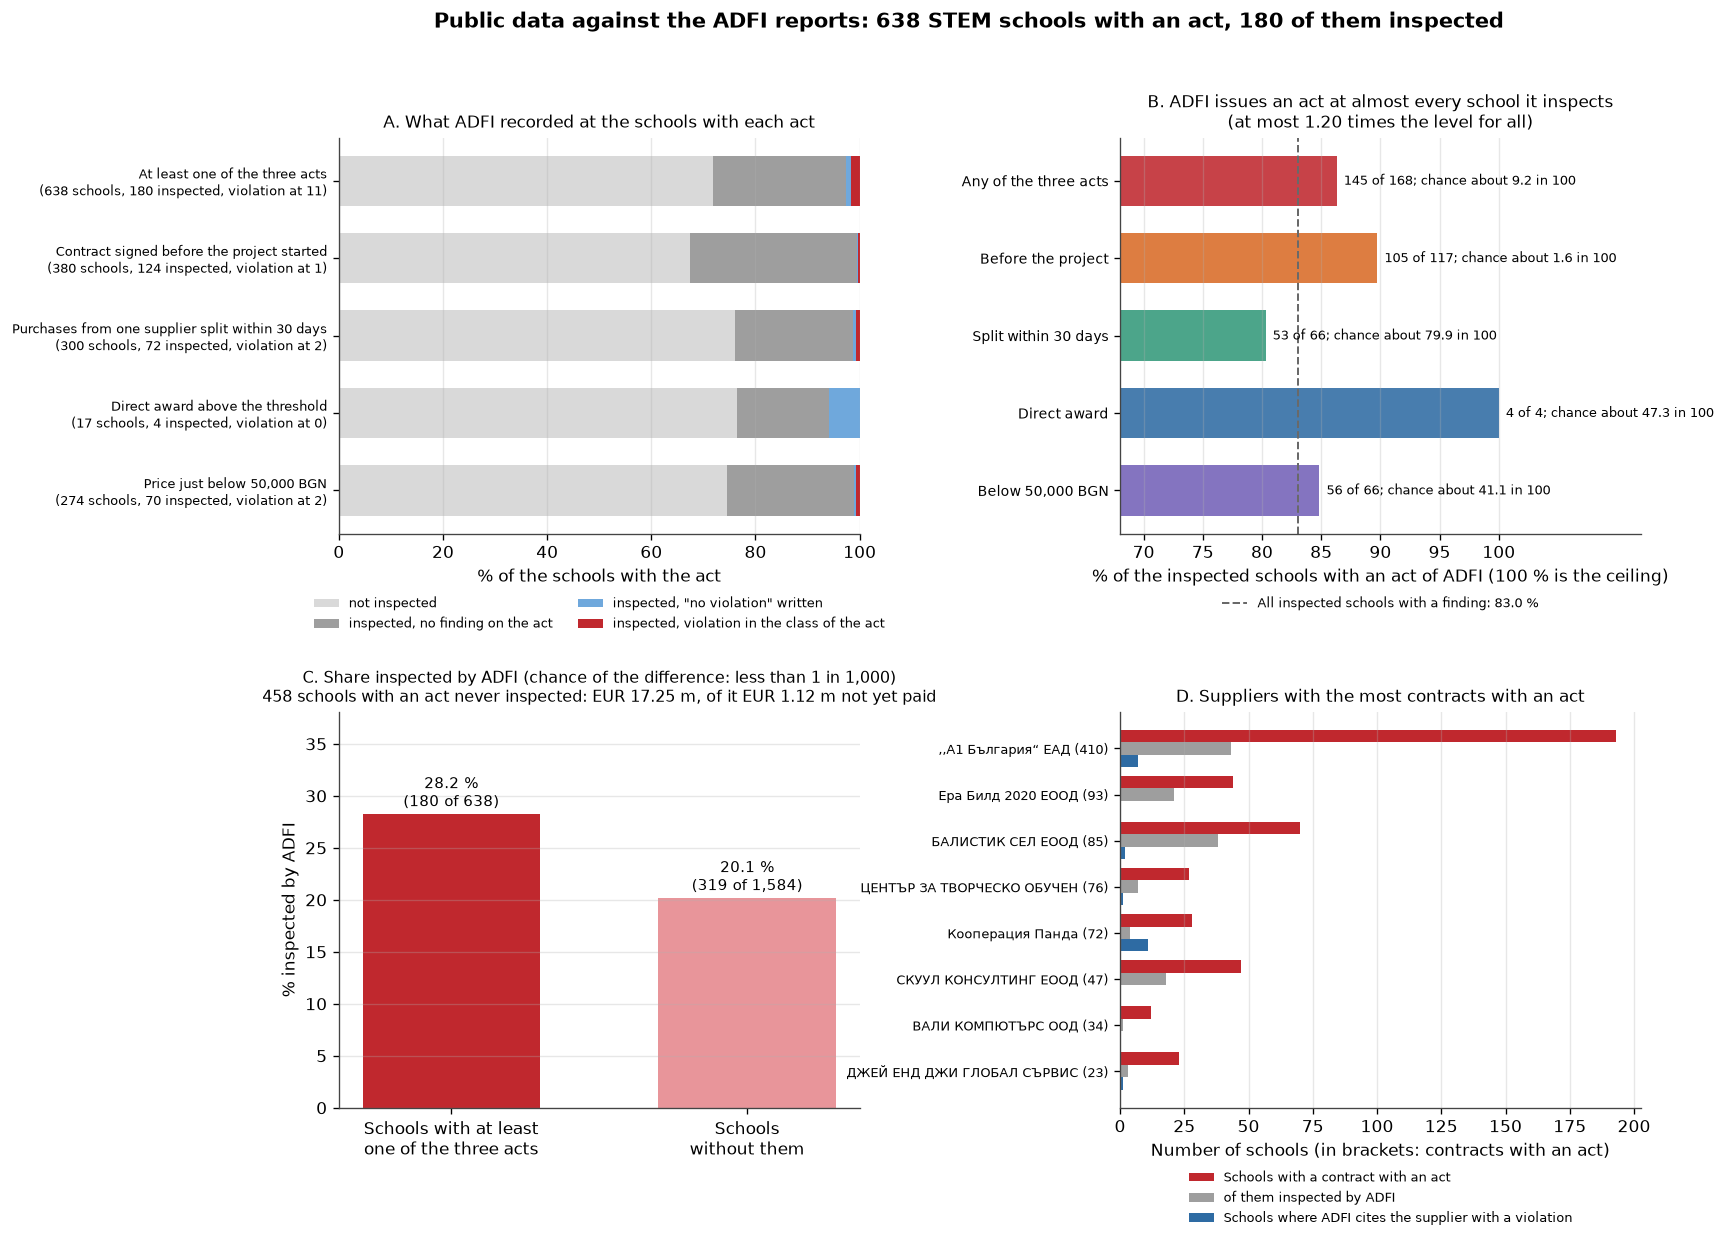

In [21]:
# Figure F2_4: what ADFI recorded at the schools with each act, and which suppliers it names; every number in the figure is taken from this run.
COL_7 = {"Level 1 union": "#c0282e", "predated": "#d96b26", "split_30d": "#33997a", "regime_mismatch": "#2e6ba3", "bunching_50k": "#7361b8"}
LAB_7 = {
    "Level 1 union": "At least one of the three acts",
    "predated": "Contract signed before the project started",
    "split_30d": "Purchases from one supplier split within 30 days",
    "regime_mismatch": "Direct award above the threshold",
    "bunching_50k": "Price just below 50,000 BGN",
}
SHORT_7 = {"Level 1 union": "Any of the three acts", "predated": "Before the project", "split_30d": "Split within 30 days",
           "regime_mismatch": "Direct award", "bunching_50k": "Below 50,000 BGN"}
order_7 = [lbl for lbl, _ in IND_7]

fig, axs = plt.subplots(2, 2, figsize=(14, 10.5), gridspec_kw={"hspace": 0.45, "wspace": 0.5})
axA, axB, axC, axD = axs.flat

# A. Schools with each act: not inspected, inspected with no finding on the act, "no violation" only, violation in the class of the act.
yA = np.arange(len(order_7))[::-1]
seg = [("not inspected", "unaudited", "#d9d9d9"), ("inspected, no finding on the act", "no_finding", "#9e9e9e"),
       ("inspected, \"no violation\" written", "no_violation_only", "#6fa8dc"), ("inspected, violation in the class of the act", "violation", "#c0282e")]
left = np.zeros(len(order_7))
for name, col, colr in seg:
    vals = np.array([a7.loc[k, col] / a7.loc[k, "flagged_schools"] * 100 for k in order_7], dtype=float)
    axA.barh(yA, vals, left=left, color=colr, height=0.65, label=name)
    left += vals
axA.set_yticks(yA, [f"{LAB_7[k]}\n({int(a7.loc[k, 'flagged_schools'])} schools, {int(a7.loc[k, 'audited'])} inspected, violation at {int(a7.loc[k, 'violation'])})" for k in order_7], fontsize=8)
axA.set_xlim(0, 100)
axA.set_xlabel("% of the schools with the act")
axA.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=7.5, frameon=False)
axA.set_title("A. What ADFI recorded at the schools with each act", fontsize=10)

# B. Share of inspected schools with an act of ADFI, by act, against the level for all and the ceiling.
yB = np.arange(len(order_7))[::-1]
precB = np.array([b7.loc[k, "precision"] * 100 for k in order_7], dtype=float)
axB.barh(yB, precB, color=[COL_7[k] for k in order_7], height=0.65, alpha=0.88)
for y, k, p in zip(yB, order_7, precB):
    axB.text(p + 0.6, y, f"{int(b7.loc[k, 'flagged_act_k'])} of {int(b7.loc[k, 'flagged_classified_n'])}; chance {chance_text(b7.loc[k, 'p_permutation'])}",
             va="center", fontsize=7.5)
axB.axvline(base_act_rate * 100, color="dimgray", ls="--", lw=1.2, label=f"All inspected schools with a finding: {base_act_rate * 100:.1f} %")
axB.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=7.5, frameon=False)
axB.set_yticks(yB, [SHORT_7[k] for k in order_7], fontsize=8.5)
axB.set_xlim(base_act_rate * 100 - 15, 112)
axB.set_xticks(np.arange(70, 101, 5))
axB.set_xlabel("% of the inspected schools with an act of ADFI (100 % is the ceiling)")
axB.set_title(f"B. ADFI issues an act at almost every school it inspects\n(at most {max_lift:.2f} times the level for all)", fontsize=10)

# C. Share inspected: schools with and without an act.
c7 = [n_aud_l1 / n_l1_7 * 100, n_aud_no / n_no_l1 * 100]
axC.bar([0, 1], c7, color=["#c0282e", "#e8959a"], width=0.6)
for x, v, k, n in zip([0, 1], c7, [n_aud_l1, n_aud_no], [n_l1_7, n_no_l1]):
    axC.text(x, v + 0.8, f"{v:.1f} %\n({k} of {n:,})", ha="center", fontsize=9)
axC.set_xticks([0, 1], ["Schools with at least\none of the three acts", "Schools\nwithout them"])
axC.set_ylim(0, max(c7) * 1.35)
axC.set_ylabel("% inspected by ADFI")
axC.set_title(f"C. Share inspected by ADFI (chance of the difference: {chance_text(l1b['selection_p'])})\n"
              f"{len(unaud_l1)} schools with an act never inspected: EUR {val_un / 1e6:.2f} m, of it EUR {(val_un - paid_un) / 1e6:.2f} m not yet paid", fontsize=9.5)

# D. Suppliers with the most contracts with an act: their schools with an act, inspected, cited with a violation.
d7 = sup7.head(8).iloc[::-1]
yD = np.arange(len(d7))
bh7 = 0.27
axD.barh(yD + bh7, d7["schools_with_act"], height=bh7, color="#c0282e", label="Schools with a contract with an act")
axD.barh(yD, d7["inspected_schools_with_act"], height=bh7, color="#9e9e9e", label="of them inspected by ADFI")
axD.barh(yD - bh7, d7["schools_cited_with_violation"], height=bh7, color="#2e6ba3", label="Schools where ADFI cites the supplier with a violation")
axD.set_yticks(yD, [f"{s[:26]} ({int(n)})" for s, n in zip(d7["supplier"], d7["with_act"])], fontsize=8)
axD.set_xlabel("Number of schools (in brackets: contracts with an act)")
axD.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=7.5, frameon=False)
axD.set_title("D. Suppliers with the most contracts with an act", fontsize=10)

for ax in axs.flat:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y" if ax is axC else "x", alpha=0.3)
fig.suptitle(f"Public data against the ADFI reports: {n_l1_7} STEM schools with an act, {n_aud_l1} of them inspected", fontsize=12.5, fontweight="bold")
fig.savefig(FIG_DIR / "F2_4_adfi_validation.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Market concentration and steering at the level of the region and the country

**What is done.** The contracts of all suppliers (by company number and name; the names of sole traders are removed) are put together for the whole programme, and the steering of Section 6.3, measured there inside one municipality, is measured at two higher levels:
- **Concentration.** The share of the programme held by the largest supplier, the five and the ten largest, and the index of concentration (HHI: the sum of the squared shares of all suppliers, close to 0 when the value is spread over many suppliers and 10,000 when one supplier holds everything). For the two largest suppliers: value with and without VAT, paid and not yet paid, share of the programme, contracts, schools, subcontractors, contracts below the direct-award threshold, and contracts signed before the project started or split within 30 days.
- **Region (oblast).** For every supplier and region it is checked whether the supplier works with more schools of the region than its size in the whole country would give. Suppliers that meet at the same schools more often than their size would give are joined into groups, and each group is compared with 10,000 random networks in which every school keeps its number of suppliers and every supplier its number of schools. Two measures are taken for each group: how evenly its suppliers share schools with each other (more tied together) and what part of the links of its suppliers stays inside the group (more closed). In the table, a group is marked Robust when both measures are above those of 9 in 10 random networks, Suspicious when above 8 in 10, and Ordinary otherwise; the labels describe only this comparison, not the suppliers.
- **Country.** It is checked whether the two largest suppliers meet at more schools than their size would give, against the same 10,000 networks.
- **Link to ex-ante control.** For each group of suppliers, the share of contracts signed before the project started, split within 30 days, or awarded directly above the threshold is compared with the share at the suppliers outside the groups. The regions are compared with the regions of Section 6 that are clearly above or below the country in the acts, and the two largest suppliers with the ADFI findings of Section 7.

The steering is measured outside the rule of H2. It follows the signs of fraud and irregularity of the course material (slides 24, 27 and 28): many orders with one contractor, a single source below the threshold, and successive linked deliveries. Supplier roles and consultants are not used, because the ISUN data do not contain them. A group of suppliers is a pattern in the public data: it does not show that the suppliers are connected or act together. The first lines of the output record how the random networks were built, so that the run can be repeated.

**Why this matters for ex-ante control.** The financial controller of a school sees only the contracts of that school. A supplier that holds a large part of the programme, or a group of suppliers that share the same schools, can be seen only across schools. This section shows how large this concentration is, and whether the acts that the controller must stop before signature are more frequent inside the groups.

**Figure F2_5.** Panel A shows the ten largest suppliers by their share of the programme, with the number of their contracts with an act and, for the two largest, the acts by kind. Panel B shows how many schools the two largest suppliers share, against the 10,000 random networks and against the number their size would give. Panel C shows, for each group of suppliers, the share of contracts with an act with its 95 % range, against the share at the suppliers outside the groups; a group with few contracts has a wide range. Panel D shows, by region, the share of school–supplier links in which the supplier works with more schools of the region than its size would give, coloured by whether the region is clearly above or below the country in the acts (Section 6).

The five limitations of the study close the section (Section 8.1).

In [22]:
# Section 8: concentration of the programme by supplier (company number and name; sole-trader names removed) and the profile of the two largest suppliers.
ven_tbl = (
    c_eval[c_eval["vendor_id"] != ""]
    .assign(below_thr=lambda d: d["amount_bgn_excl_vat"] < d["threshold_bgn_excl_vat"])
    .groupby(["vendor_id", "vendor_eik", "vendor_name"], as_index=False)
    .agg(
        contracts=("contract_row", "count"),
        schools=("school_bulstat", "nunique"),
        oblasts=("oblast_ruo", "nunique"),
        municipalities=("municipality", "nunique"),
        val_incl_eur=("amount_eur_incl_vat", "sum"),
        val_excl_eur=("amount_eur_excl_vat", "sum"),
        predated_contracts=("flag_predated", "sum"),
        split_30d_contracts=("flag_split_30d", "sum"),
        regime_mismatch_contracts=("flag_regime_mismatch", "sum"),
        level1_contracts=("flag_level1", "sum"),
        val_paid_eur=("paid_alloc_eur_incl_vat", "sum"),
        subcontractors=("subcontractors_count", "sum"),
        below_threshold_contracts=("below_thr", "sum"),
    )
    .sort_values("val_excl_eur", ascending=False)
    .reset_index(drop=True)
)
tot_ven_excl = float(ven_tbl["val_excl_eur"].sum())
ven_tbl["share_val_pct"] = ven_tbl["val_excl_eur"] / tot_ven_excl * 100.0
c1_pct = float(ven_tbl["share_val_pct"].iloc[0])
c5_pct = float(ven_tbl["share_val_pct"].iloc[:5].sum())
c10_pct = float(ven_tbl["share_val_pct"].iloc[:10].sum())
hhi_val = float((ven_tbl["share_val_pct"] ** 2).sum())
c1_cnt = float(ven_tbl.sort_values("contracts", ascending=False)["contracts"].iloc[0] / ven_tbl["contracts"].sum() * 100.0)
c5_cnt = float(ven_tbl.sort_values("contracts", ascending=False)["contracts"].iloc[:5].sum() / ven_tbl["contracts"].sum() * 100.0)

print(f"Suppliers (unique vendor_id): {len(ven_tbl)} (unique EIK: {ven_tbl.loc[ven_tbl['vendor_eik']!='', 'vendor_eik'].nunique()})")
print(f"Value concentration (EUR excl. VAT): C1={c1_pct:.2f}%, C5={c5_pct:.2f}%, C10={c10_pct:.2f}%, HHI={hhi_val:.1f} (Contract-count C1={c1_cnt:.2f}%, C5={c5_cnt:.2f}%)")
display(ven_tbl.head(10)[["vendor_eik", "vendor_name", "schools", "oblasts", "contracts", "val_incl_eur", "share_val_pct", "level1_contracts"]])

record_conclusion("Section 8", "concentration", "unique supplier vendor_id count", int(len(ven_tbl)))
record_conclusion("Section 8", "concentration", "unique supplier EIK count", int(ven_tbl.loc[ven_tbl["vendor_eik"] != "", "vendor_eik"].nunique()))
record_conclusion("Section 8", "concentration", "Top-1 supplier name", str(ven_tbl.iloc[0]["vendor_name"]))
record_conclusion("Section 8", "concentration", "Top-1 supplier value share C1 (%)", f"{c1_pct:.2f}", "", "", "entity", str(ven_tbl.iloc[0]["vendor_name"]))
record_conclusion("Section 8", "concentration", "Top-5 suppliers value share C5 (%)", f"{c5_pct:.2f}")
record_conclusion("Section 8", "concentration", "Top-10 suppliers value share C10 (%)", f"{c10_pct:.2f}")
record_conclusion("Section 8", "concentration", "Supplier value HHI", f"{hhi_val:.1f}")

tot_prog_incl = float(c_eval["amount_eur_incl_vat"].sum())
top2 = ven_tbl.iloc[:2].copy()
top2["val_unpaid_eur"] = top2["val_incl_eur"] - top2["val_paid_eur"]
top2["share_prog_incl_pct"] = top2["val_incl_eur"] / tot_prog_incl * 100.0
top2_view = top2[["vendor_eik", "vendor_name", "val_incl_eur", "val_excl_eur", "val_paid_eur", "val_unpaid_eur", "share_prog_incl_pct", "contracts", "schools",
                  "subcontractors", "below_threshold_contracts", "predated_contracts", "split_30d_contracts", "regime_mismatch_contracts", "level1_contracts"]]
print("\nThe two largest suppliers by value:")
display(top2_view)
print(f"Together: EUR {top2['val_incl_eur'].sum():,.2f} incl. VAT ({top2['val_incl_eur'].sum() / tot_prog_incl * 100:.2f} % of the programme), "
      f"{int(top2['contracts'].sum()):,} contracts, {int(top2['below_threshold_contracts'].sum()):,} of them below the direct-award threshold, "
      f"{int(top2['level1_contracts'].sum())} with at least one of the three acts.")
for r in top2.itertuples():
    record_conclusion("Section 8", "concentration_top2", f"{r.vendor_name} ({r.vendor_eik}) value EUR incl VAT / excl VAT", f"{r.val_incl_eur:.2f}", "", "", "excl VAT", f"{r.val_excl_eur:.2f}")
    record_conclusion("Section 8", "concentration_top2", f"{r.vendor_name} ({r.vendor_eik}) paid / unpaid EUR incl VAT", f"{r.val_paid_eur:.2f}", "", "", "unpaid", f"{r.val_unpaid_eur:.2f}")
    record_conclusion("Section 8", "concentration_top2", f"{r.vendor_name} ({r.vendor_eik}) contracts / schools / subcontractors", f"{int(r.contracts)} / {int(r.schools)} / {int(r.subcontractors)}")
    record_conclusion("Section 8", "concentration_top2", f"{r.vendor_name} ({r.vendor_eik}) contracts below threshold / predated / split_30d", f"{int(r.below_threshold_contracts)} / {int(r.predated_contracts)} / {int(r.split_30d_contracts)}")

Suppliers (unique vendor_id): 1754 (unique EIK: 1732)
Value concentration (EUR excl. VAT): C1=14.61%, C5=33.60%, C10=44.74%, HHI=358.6 (Contract-count C1=11.27%, C5=28.72%)


,vendor_eik,vendor_name,schools,oblasts,contracts,val_incl_eur,share_val_pct,level1_contracts
0,000885099,Кооперация Панда,581,28,1254,4.216522e+07,14.611851,72
1,131468980,",,А1 България“ ЕАД",298,28,751,1.912906e+07,6.628946,410
2,175342714,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,161,27,434,1.258283e+07,4.360428,76
3,204660454,Юнион Интерактив ООД,164,26,305,1.219395e+07,4.225667,10
4,202395053,ЕВРОКЛАС – КОНСУЛТ ЕООД,143,14,341,1.088546e+07,3.772226,10
5,201055457,БАЛИСТИК СЕЛ ЕООД,92,17,169,9.061433e+06,3.140131,85
6,128049011,КАН УЧТЕХСПОРТ БЪЛГАРИЯ ООД,355,26,416,7.843423e+06,2.718044,22
7,200544954,Уеб Сървисис ЕООД,59,13,119,5.481065e+06,1.899398,16
8,175063752,КЕЙСИЕМ ЕООД,61,18,101,5.036811e+06,1.745447,2
9,175415627,КОНТРАКС АД,49,20,98,4.735687e+06,1.641096,3



The two largest suppliers by value:


,vendor_eik,vendor_name,val_incl_eur,val_excl_eur,val_paid_eur,val_unpaid_eur,share_prog_incl_pct,contracts,schools,subcontractors,below_threshold_contracts,predated_contracts,split_30d_contracts,regime_mismatch_contracts,level1_contracts
0,000885099,Кооперация Панда,4.216522e+07,3.513768e+07,3.907706e+07,3.088158e+06,14.610598,1254,581,0,758,4,68,0,72
1,131468980,",,А1 България“ ЕАД",1.912906e+07,1.594088e+07,1.765092e+07,1.478134e+06,6.628377,751,298,0,556,368,119,1,410


Together: EUR 61,294,273.71 incl. VAT (21.24 % of the programme), 2,005 contracts, 1,314 of them below the direct-award threshold, 482 with at least one of the three acts.


In [23]:
# Section 8: school-supplier network, links beyond supplier size (BiCM, BH q <= 0.01), Louvain supplier groups, and 10,000 random networks with the same degrees.
import time
t_bicm0 = time.perf_counter()
v_ids_b, v_codes_b = np.unique(c_eval["vendor_id"], return_inverse=True)
u_codes_b = np.searchsorted(units["project_id"].to_numpy(), c_eval["project_id"].to_numpy())
B_mat = sparse.coo_matrix((np.ones(len(u_codes_b), dtype=np.int32), (u_codes_b, v_codes_b)), shape=(len(units), len(v_ids_b))).tocsr()
B_mat.data[:] = 1
sch_deg = np.asarray(B_mat.sum(axis=1)).ravel()
ven_deg = np.asarray(B_mat.sum(axis=0)).ravel()
O_mat = (B_mat.T @ B_mat).tocsr()

k_arr, d_arr = sch_deg.astype(np.float64), ven_deg.astype(np.float64)
act_u = k_arr > 0
x_u = np.where(act_u, k_arr / np.sqrt(B_mat.nnz), 0.0)
y_v = d_arr / np.sqrt(B_mat.nnz)
for it_b in range(500):
    xy = np.outer(x_u[act_u], y_v)
    p_mat = xy / (1.0 + xy)
    res_b = max(float(np.abs(p_mat.sum(axis=1) - k_arr[act_u]).max()), float(np.abs(p_mat.sum(axis=0) - d_arr).max()))
    if res_b < 1e-10:
        break
    x_u[act_u] = k_arr[act_u] / (y_v[None, :] / (1.0 + xy)).sum(axis=1)
    xy = np.outer(x_u[act_u], y_v)
    y_v = d_arr / (x_u[act_u, None] / (1.0 + xy)).sum(axis=0)
P_act = np.outer(x_u[act_u], y_v)
P_act = P_act / (1.0 + P_act)

upper_o = sparse.triu(O_mat, k=1).tocoo()
pord = np.lexsort((upper_o.col, upper_o.row))
pa, pb_idx, ov = upper_o.row[pord], upper_o.col[pord], upper_o.data[pord].astype(np.int64)

n_pts = int(act_u.sum()) + 1
angles = 2.0 * np.pi * np.arange(n_pts // 2 + 1) / n_pts
u_spec = np.exp(-1j * angles) - 1.0
P_T = np.ascontiguousarray(P_act.T)
p_bicm = np.empty(len(ov))
for idx_p in range(len(ov)):
    q = P_T[pa[idx_p]] * P_T[pb_idx[idx_p]]
    small = q < 1e-3
    tot = np.zeros(len(u_spec), dtype=np.complex128)
    if small.any():
        qs = q[small]
        pw, up = np.ones_like(qs), np.ones_like(u_spec)
        for o in range(1, 7):
            pw, up = pw * qs, up * u_spec
            tot += (-1.0) ** (o + 1) * pw.sum() / o * up
    if (~small).any():
        tot += np.log1p(q[~small, None] * u_spec[None, :]).sum(axis=0)
    pmf = np.fft.irfft(np.exp(tot), n=n_pts)
    tail = float(pmf[ov[idx_p]:].sum())
    if tail < 1e-9:
        cpmf = np.array([1.0])
        for qi in q:
            cpmf = np.convolve(cpmf, [1.0 - qi, qi])
        tail = float(cpmf[ov[idx_p]:].sum())
    p_bicm[idx_p] = min(max(tail, 0.0), 1.0)

M_bicm = len(v_ids_b) * (len(v_ids_b) - 1) // 2
s_ord_b = np.argsort(p_bicm, kind="stable")
scaled_b = p_bicm[s_ord_b] * M_bicm / np.arange(1, len(p_bicm) + 1)
q_bicm = np.empty_like(p_bicm)
q_bicm[s_ord_b] = np.minimum(np.minimum.accumulate(scaled_b[::-1])[::-1], 1.0)
bicm_valid = q_bicm <= 0.01

G_bb = nx.Graph()
G_bb.add_edges_from(zip(pa[bicm_valid].tolist(), pb_idx[bicm_valid].tolist()))
parts = nx.community.louvain_communities(G_bb, resolution=1.0, seed=RNG_STATE)
groups = sorted((sorted(pt) for pt in parts if len(pt) >= 3), key=lambda pt: (-len(pt), pt[0]))
print(f"BiCM converged it={it_b}, res={res_b:.2e}, pairs O>=1={len(ov)}/{M_bicm}, BH q<=0.01 links={int(bicm_valid.sum())}, backbone nodes={G_bb.number_of_nodes()}, Louvain groups (size>=3)={len(groups)} ({[len(g) for g in groups]}), time={time.perf_counter()-t_bicm0:.2f}s")

t_mc0 = time.perf_counter()
B_csr = B_mat.tocsr()
B_csr.sort_indices()
indptr = B_csr.indptr.astype(np.int64)
deg_row = np.diff(indptr)
edge_sch = np.repeat(np.arange(B_csr.shape[0]), deg_row)
edge_ven = B_csr.indices.astype(np.int16)
row_f, row_l = indptr[:-1], indptr[1:] - 1
slots = np.arange(int(deg_row.max()))
n_edges = len(edge_ven)
CHAINS, N_SAMPLES = 100, 10000
rounds = N_SAMPLES // CHAINS
state = np.tile(edge_ven, (CHAINS, 1))
rows_c = np.arange(CHAINS)
col_c = rows_c[:, None]
rng_mc = np.random.default_rng(RNG_STATE)

def advance_mc(steps):
    for f in range(0, steps, 256):
        sz = min(256, steps - f)
        draws = rng_mc.integers(0, n_edges, size=(2, sz, CHAINS))
        for l1, l2 in zip(draws[0], draws[1]):
            s1, s2 = edge_sch[l1], edge_sch[l2]
            v1, v2 = state[rows_c, l1], state[rows_c, l2]
            dist = (s1 != s2) & (v1 != v2)
            r1 = np.minimum(row_f[s1][:, None] + slots, row_l[s1][:, None])
            r2 = np.minimum(row_f[s2][:, None] + slots, row_l[s2][:, None])
            blk = (state[col_c, r1] == v2[:, None]).any(axis=1) | (state[col_c, r2] == v1[:, None]).any(axis=1)
            sw = dist & ~blk
            ch = rows_c[sw]
            state[ch, l1[sw]] = v2[sw]
            state[ch, l2[sw]] = v1[sw]

BURN_STEPS = 6 * n_edges
THIN_STEPS = n_edges
samples_mc = np.empty((N_SAMPLES, n_edges), dtype=np.int16)
advance_mc(BURN_STEPS)
samples_mc[:CHAINS] = state
for r_i in range(1, rounds):
    advance_mc(THIN_STEPS)
    samples_mc[r_i * CHAINS:(r_i + 1) * CHAINS] = state
t_mc = time.perf_counter() - t_mc0
n_unique_mc = int(len(np.unique(samples_mc, axis=0)))

orig_mask = np.zeros(B_mat.shape, dtype=bool)
orig_mask[edge_sch, edge_ven] = True
ret_share = np.concatenate([orig_mask[edge_sch[None, :], samples_mc[i:i + 500]].mean(axis=1) for i in range(0, N_SAMPLES, 500)])
P_full = np.zeros(B_mat.shape)
P_full[act_u] = P_act
bicm_plateau = float(P_full[edge_sch, edge_ven].sum() / n_edges)
print(f"10,000 degree-preserving random bipartite networks completed in {t_mc:.1f}s (burn={BURN_STEPS}, thin={THIN_STEPS}, unique={n_unique_mc}/10000); retained link share = {ret_share.mean():.4f} (BiCM plateau = {bicm_plateau:.4f})")
assert n_unique_mc >= 9900

BiCM converged it=23, res=4.25e-11, pairs O>=1=8049/1539135, BH q<=0.01 links=80, backbone nodes=90, Louvain groups (size>=3)=9 ([10, 5, 4, 4, 4, 4, 3, 3, 3]), time=15.56s
10,000 degree-preserving random bipartite networks completed in 33.8s (burn=43374, thin=7229, unique=10000/10000); retained link share = 0.0535 (BiCM plateau = 0.0535)


In [24]:
# Section 8: Level 2 (oblast) links beyond supplier size, supplier groups against 10,000 networks and their contract indicators, Level 3 (country) overlap of the two largest suppliers.
units_act = units[act_u].reset_index(drop=True)
B_act = B_mat[act_u, :]
oblast_names = sorted(units_act["oblast_ruo"].astype(str).unique())
ov_ob_rows = []
for ob in oblast_names:
    rm = (units_act["oblast_ruo"].astype(str) == ob).to_numpy()
    n_r = int(rm.sum())
    k_ir = np.asarray(B_act[rm, :].sum(axis=0)).ravel().astype(int)
    for vi in np.flatnonzero(k_ir >= 2):
        p_h = float(stats.hypergeom.sf(k_ir[vi] - 1, len(units_act), int(ven_deg[vi]), n_r))
        exp_b = float(P_act[rm, vi].sum())
        ov_ob_rows.append((ob, v_ids_b[vi], int(ven_deg[vi]), n_r, int(k_ir[vi]), exp_b, p_h))
df_ov_ob = pd.DataFrame(ov_ob_rows, columns=["oblast", "vendor_id", "d_nat", "n_ob", "k_ob", "exp_bicm", "p_hyp"])
pad_ones = np.ones(max(0, 28 * len(v_ids_b) - len(df_ov_ob)))
df_ov_ob["q_bh"] = bh_fdr(np.concatenate([df_ov_ob["p_hyp"].to_numpy(), pad_ones]))[:len(df_ov_ob)]
sig_ov_ob = df_ov_ob[df_ov_ob["q_bh"] <= 0.01].copy()
print(f"Level 2 Oblast supplier concentration over size: {len(sig_ov_ob)} significant (vendor, oblast) pairs out of {len(df_ov_ob)} tested (q <= 0.01), covering {int(sig_ov_ob['k_ob'].sum())} school links.")

occ_idx = np.flatnonzero(deg_row > 0)
starts_mc = indptr[:-1][occ_idx]
others_mc = deg_row[occ_idx] - 1.0

def eval_group_metrics(states, grp):
    pres = np.stack([np.logical_or.reduceat(states == m, starts_mc, axis=1) for m in grp], axis=2)
    ms = range(len(grp))
    pairs = [(a_m, b_m) for a_m in ms for b_m in ms if a_m < b_m]
    ov_g = np.stack([(pres[:, :, a_m] & pres[:, :, b_m]).sum(axis=1) for a_m, b_m in pairs], axis=1).astype(np.float64)
    s_in = 2.0 * ov_g.sum(axis=1)
    s_all = sum(pres[:, :, a_m].astype(np.float64) @ others_mc for a_m in ms)
    s_out = s_all - s_in
    pos_g = ov_g > 0
    np_g = pos_g.sum(axis=1)
    lmean = np.where(pos_g, np.log(np.where(pos_g, ov_g, 1.0)), 0.0).sum(axis=1) / np.maximum(np_g, 1)
    amean = ov_g.sum(axis=1) / np.maximum(np_g, 1)
    cg = np.where(np_g > 0, np.exp(lmean) / np.where(amean > 0, amean, 1.0), 0.0)
    eg = np.where(s_in + s_out > 0, s_in / np.where(s_in + s_out > 0, s_in + s_out, 1.0), 0.0)
    return cg, eg

ven_eik_map = c_eval.drop_duplicates("vendor_id").set_index("vendor_id")["vendor_eik"].to_dict()
ven_nam_map = c_eval.drop_duplicates("vendor_id").set_index("vendor_id")["vendor_name"].to_dict()
ven_grp_map = {}
for gi, g in enumerate(groups, 1):
    gid = f"G{gi:02d}"
    for vi in g:
        ven_grp_map[v_ids_b[vi]] = gid
c_eval["steering_group"] = c_eval["vendor_id"].map(ven_grp_map).fillna("Out of groups")

obs_st = edge_ven[None, :]
rng_reg = np.random.default_rng(RNG_STATE)
ob_act_codes = pd.factorize(units_act["oblast_ruo"].astype(str))[0]
out_gc0 = c_eval[c_eval["steering_group"] == "Out of groups"]
out_l1 = int(out_gc0["flag_level1"].sum())
grp_eval_rows = []
for gi, g in enumerate(groups, 1):
    gid = f"G{gi:02d}"
    oc, oe = eval_group_metrics(obs_st, g)
    oc_r, oe_r = round(float(oc[0]), 12), float(oe[0])
    nc_l, ne_l = [], []
    for i in range(0, N_SAMPLES, 500):
        cg_p, eg_p = eval_group_metrics(samples_mc[i:i + 500], g)
        nc_l.append(cg_p)
        ne_l.append(eg_p)
    nc = np.round(np.concatenate(nc_l), 12)
    ne = np.concatenate(ne_l)
    c80, c90 = np.percentile(nc, [80, 90])
    e80, e90 = np.percentile(ne, [80, 90])
    p_joint = (1 + int(((nc >= oc_r) & (ne >= oe_r)).sum())) / (N_SAMPLES + 1)
    cls_lbl = "Robust" if (oc_r >= c90 and oe_r >= e90) else ("Suspicious" if (oc_r >= c80 and oe_r >= e80) else "Ordinary")

    sub_gc = c_eval[c_eval["steering_group"] == gid]
    g_sch_obs = (np.asarray(B_act[:, g].sum(axis=1)).ravel() > 0).astype(int)
    max_ob_obs = int(pd.Series(g_sch_obs).groupby(ob_act_codes).sum().max())
    n_g_sch = int(g_sch_obs.sum())
    ob_probs = np.bincount(ob_act_codes) / len(ob_act_codes)
    ob_null_draws = rng_reg.multinomial(n_g_sch, ob_probs, size=10000).max(axis=1)
    p_reg_max = (1 + int((ob_null_draws >= max_ob_obs).sum())) / 10001

    top_members = "; ".join(f"{ven_nam_map[v_ids_b[idx]]} ({ven_eik_map[v_ids_b[idx]]})" for idx in g[:3])
    grp_eval_rows.append({
        "group_id": gid,
        "n_vendors": len(g),
        "C_G": round(oc_r, 4),
        "E_G": round(oe_r, 4),
        "p_joint_10k": round(p_joint, 4),
        "classification": cls_lbl,
        "max_oblast_schools": max_ob_obs,
        "p_oblast_perm_10k": round(p_reg_max, 4),
        "contracts": int(len(sub_gc)),
        "schools": int(sub_gc["school_bulstat"].nunique()),
        "val_incl_eur": round(float(sub_gc["amount_eur_incl_vat"].sum()), 2),
        "level1_pct": round(float(sub_gc["flag_level1"].mean()) * 100.0, 2),
        "predated_pct": round(float(sub_gc["flag_predated"].mean()) * 100.0, 2),
        "split_30d_pct": round(float(sub_gc["flag_split_30d"].mean()) * 100.0, 2),
        "regime_mismatch_pct": round(float(sub_gc["flag_regime_mismatch"].mean()) * 100.0, 2),
        "level1_p_vs_out": round(float(stats.fisher_exact([[int(sub_gc["flag_level1"].sum()), int((~sub_gc["flag_level1"]).sum())],
                                                           [out_l1, int(len(out_gc0)) - out_l1]])[1]), 4),
        "top_members_sample": top_members,
    })

out_gc = c_eval[c_eval["steering_group"] == "Out of groups"]
grp_eval_rows.append({
    "group_id": "Out of groups",
    "n_vendors": int(len(v_ids_b) - sum(len(g) for g in groups)),
    "C_G": np.nan,
    "E_G": np.nan,
    "p_joint_10k": np.nan,
    "classification": "Reference",
    "max_oblast_schools": np.nan,
    "p_oblast_perm_10k": np.nan,
    "contracts": int(len(out_gc)),
    "schools": int(out_gc["school_bulstat"].nunique()),
    "val_incl_eur": round(float(out_gc["amount_eur_incl_vat"].sum()), 2),
    "level1_pct": round(float(out_gc["flag_level1"].mean()) * 100.0, 2),
    "predated_pct": round(float(out_gc["flag_predated"].mean()) * 100.0, 2),
    "split_30d_pct": round(float(out_gc["flag_split_30d"].mean()) * 100.0, 2),
    "regime_mismatch_pct": round(float(out_gc["flag_regime_mismatch"].mean()) * 100.0, 2),
    "level1_p_vs_out": np.nan,
    "top_members_sample": "All suppliers outside G01-G09",
})

df_grps = pd.DataFrame(grp_eval_rows)
print("\nLouvain Supplier Groups vs. 10,000 Random Bipartite Networks & Ex-Ante Control Indicators:")
display(df_grps)

panda_pos = int(np.flatnonzero(v_ids_b == ven_tbl["vendor_id"].iloc[0])[0])
a1_pos = int(np.flatnonzero(v_ids_b == ven_tbl["vendor_id"].iloc[1])[0])
obs_pa = int(O_mat[panda_pos, a1_pos])
exp_pa_bicm = float((P_act[:, panda_pos] * P_act[:, a1_pos]).sum())
mc_pa = np.concatenate([
    (np.logical_or.reduceat(samples_mc[i:i + 500] == panda_pos, starts_mc, axis=1) & np.logical_or.reduceat(samples_mc[i:i + 500] == a1_pos, starts_mc, axis=1)).sum(axis=1)
    for i in range(0, N_SAMPLES, 500)
])
p_pa_ge = (1 + int((mc_pa >= obs_pa).sum())) / (N_SAMPLES + 1)
p_pa_le = (1 + int((mc_pa <= obs_pa).sum())) / (N_SAMPLES + 1)
print(f"\nLevel 3 Country Overlap ({ven_tbl['vendor_name'].iloc[0]} deg={int(ven_deg[panda_pos])}, {ven_tbl['vendor_name'].iloc[1]} deg={int(ven_deg[a1_pos])}):")
print(f"  Observed shared schools = {obs_pa}; BiCM expected = {exp_pa_bicm:.2f}; 10,000-network MC mean = {mc_pa.mean():.2f} +/- {mc_pa.std():.2f}; p(MC >= obs) = {p_pa_ge:.4f}; p(MC <= obs) = {p_pa_le:.4f}.")
print("  Conclusion at country level: the overlap between the top two suppliers is "
      + ("BELOW" if p_pa_le <= 0.05 else ("ABOVE" if p_pa_ge <= 0.05 else "NOT DIFFERENT FROM")) + " what their size gives in the 10,000 networks.")

grp_only = df_grps[df_grps["group_id"] != "Out of groups"]
max_l1_g = grp_only.sort_values("level1_pct", ascending=False).iloc[0]
min_l1_g = grp_only.sort_values("level1_pct", ascending=True).iloc[0]
print(f"Supplier groups with a Level 1 share different from the suppliers outside the groups (Fisher exact, p <= 0.05): {int((grp_only['level1_p_vs_out'] <= 0.05).sum())} of {len(grp_only)}.")
top2_cnt = int(ven_tbl["contracts"].iloc[:2].sum())
top2_val_incl = float(ven_tbl["val_incl_eur"].iloc[:2].sum())
top2_share = float(ven_tbl["share_val_pct"].iloc[:2].sum())
a1_l1_cnt = int(ven_tbl["level1_contracts"].iloc[1])

record_conclusion("Section 8", "steering_levels_2_3", "Top-2 leaders combined contracts", top2_cnt)
record_conclusion("Section 8", "steering_levels_2_3", "Top-2 leaders combined value EUR incl VAT", f"{top2_val_incl:.2f}")
record_conclusion("Section 8", "steering_levels_2_3", "Top-2 leaders combined value share (%)", f"{top2_share:.2f}")
record_conclusion("Section 8", "steering_levels_2_3", "Second-largest supplier Level 1 contracts", a1_l1_cnt)
record_conclusion("Section 8", "steering_levels_2_3", "BiCM valid links (q<=0.01)", int(bicm_valid.sum()))
record_conclusion("Section 8", "steering_levels_2_3", "Backbone nodes", int(G_bb.number_of_nodes()))
record_conclusion("Section 8", "steering_levels_2_3", "Louvain supplier groups (size>=3)", int(len(groups)))
record_conclusion("Section 8", "steering_levels_2_3", "10,000 networks unique count", n_unique_mc, "", "", "swap MC", f"burn={BURN_STEPS}, thin={THIN_STEPS}")
record_conclusion("Section 8", "steering_levels_2_3", "Oblast excess vendor-oblast cells", int(len(sig_ov_ob)))
record_conclusion("Section 8", "steering_levels_2_3", "Oblast excess school links count", int(sig_ov_ob["k_ob"].sum()))
record_conclusion("Section 8", "steering_levels_2_3", "Country top-2 suppliers observed shared schools", obs_pa, "", "", "BiCM exp", f"{exp_pa_bicm:.2f}; p(MC <= obs)={p_pa_le:.4f}")
record_conclusion("Section 8", "steering_levels_2_3", "Country top-2 suppliers 10k MC expected mean", f"{mc_pa.mean():.2f}", f"{mc_pa.mean() - 1.96 * mc_pa.std():.2f}", f"{mc_pa.mean() + 1.96 * mc_pa.std():.2f}", "10,000 networks", f"p={p_pa_ge:.4f}")
record_conclusion("Section 8", "steering_levels_2_3", "Highest group Level 1 rate (%)", f"{max_l1_g['level1_pct']:.2f}", "", "", "group", str(max_l1_g["group_id"]))
record_conclusion("Section 8", "steering_levels_2_3", "Lowest group Level 1 rate (%)", f"{min_l1_g['level1_pct']:.2f}", "", "", "group", str(min_l1_g["group_id"]))
for r in grp_only.itertuples():
    record_conclusion("Section 8", "steering_groups", f"{r.group_id} Level 1 rate (%) vs out of groups", f"{r.level1_pct:.2f}", "", "", "Fisher exact vs out of groups", f"p={r.level1_p_vs_out:.4f}; {r.classification}")
record_conclusion("Section 8", "steering_groups", "Out of groups Level 1 rate (%)", f"{float(out_gc['flag_level1'].mean()) * 100:.2f}")
flush_conclusions()

Level 2 Oblast supplier concentration over size: 184 significant (vendor, oblast) pairs out of 981 tested (q <= 0.01), covering 1693 school links.

Louvain Supplier Groups vs. 10,000 Random Bipartite Networks & Ex-Ante Control Indicators:


,group_id,n_vendors,C_G,E_G,p_joint_10k,classification,max_oblast_schools,p_oblast_perm_10k,contracts,schools,val_incl_eur,level1_pct,predated_pct,split_30d_pct,regime_mismatch_pct,level1_p_vs_out,top_members_sample
0,G01,10,0.5556,0.5492,0.0001,Ordinary,65.0,0.0002,1083,429,2.393470e+07,7.85,4.52,3.32,0.00,0.0000,Естет-Мебел ЕООД (208044399); РЕСТОР СТРОЙ ЕОО...
1,G02,5,1.0000,0.5405,0.0001,Robust,13.0,0.0001,44,15,6.634126e+05,18.18,0.00,18.18,0.00,0.3732,ЗЕЛЕНО УПРАВЛЕНИЕ ООД (204051460); БЕСТКОНСУЛТ...
2,G03,4,0.9251,0.2320,0.0001,Ordinary,15.0,0.0001,85,27,2.416198e+06,15.29,1.18,14.12,0.00,0.6313,ОФИС ГРУП БГ ЕООД (201978117); ВНС - Ремонт ЕО...
3,G04,4,0.9682,0.3179,0.0001,Suspicious,5.0,0.0150,30,14,1.210431e+06,23.33,23.33,0.00,0.00,0.1131,[физическо лице — заличено] (); [физическо лиц...
4,G05,4,0.9854,0.9444,0.0001,Robust,21.0,0.0002,374,88,9.420902e+06,6.95,6.95,0.00,0.27,0.0001,Аксес Саунд ЕООД (206368790); ДЖЕЙ ЕНД ДЖИ ЕДЮ...
5,G06,4,0.8808,0.4660,0.0001,Ordinary,30.0,0.0001,96,36,2.201952e+06,0.00,0.00,0.00,0.00,0.0000,ДИ ЕЙЧ БИЛДИНГ ЕООД (131203665); ККС ЕООД (208...
6,G07,3,1.0000,0.2162,0.0001,Robust,18.0,0.0001,89,38,3.294179e+06,0.00,0.00,0.00,0.00,0.0000,Валперс Консулт ЕООД (126608480); ФЛАШКОМ ЕООД...
7,G08,3,0.9701,0.2839,0.0001,Suspicious,15.0,0.0001,62,16,2.591642e+06,9.68,1.61,8.06,0.00,0.4591,Ю4Кей ЕООД (205912196); КУПА България ООД (202...
8,G09,3,0.9953,0.7586,0.0001,Ordinary,16.0,0.0001,106,28,2.863620e+06,22.64,15.09,7.55,6.60,0.0097,ЕНЕРДЖИ СПЕД ЕООД (201463957); БОЛД СЪЛЮШЪНС Е...
9,Out of groups,1715,NaN,NaN,NaN,Reference,NaN,NaN,9159,2012,2.399963e+08,13.47,6.05,8.31,0.12,NaN,All suppliers outside G01-G09



Level 3 Country Overlap (Кооперация Панда deg=581, ,,А1 България“ ЕАД deg=298):
  Observed shared schools = 46; BiCM expected = 91.86; 10,000-network MC mean = 74.67 +/- 6.93; p(MC >= obs) = 1.0000; p(MC <= obs) = 0.0001.
  Conclusion at country level: the overlap between the top two suppliers is BELOW what their size gives in the 10,000 networks.
Supplier groups with a Level 1 share different from the suppliers outside the groups (Fisher exact, p <= 0.05): 5 of 9.


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
186,Section 8,steering_groups,G06 Level 1 rate (%) vs out of groups,0.00,,,Fisher exact vs out of groups,p=0.0000; Ordinary
187,Section 8,steering_groups,G07 Level 1 rate (%) vs out of groups,0.00,,,Fisher exact vs out of groups,p=0.0000; Robust
188,Section 8,steering_groups,G08 Level 1 rate (%) vs out of groups,9.68,,,Fisher exact vs out of groups,p=0.4591; Suspicious
189,Section 8,steering_groups,G09 Level 1 rate (%) vs out of groups,22.64,,,Fisher exact vs out of groups,p=0.0097; Ordinary


In [25]:
# Economic conclusions of Section 8: every figure is taken from this run; H2 comes from Section 4.5, the regions from Section 6, the municipal steering from Section 6.3 and the ADFI findings from Section 7.
t2 = ven_tbl.iloc[:2]
n_c_all = int(len(c_eval))
l1_rate_all = float(c_eval["flag_level1"].mean() * 100.0)
top2_ids = list(t2["vendor_id"])
c_t2 = c_eval[c_eval["vendor_id"].isin(top2_ids)]
t2_schools = int(c_t2["school_bulstat"].nunique())
t2_paid = float(t2["val_paid_eur"].sum())
t2_below = int(t2["below_threshold_contracts"].sum())
t2_sub = int(t2["subcontractors"].sum())
n_links = int(B_mat.nnz)
sig_links = int(sig_ov_ob["k_ob"].sum())
sig_vendors = int(sig_ov_ob["vendor_id"].nunique())
sig_oblasts = int(sig_ov_ob["oblast"].nunique())

g8 = df_grps[df_grps["group_id"] != "Out of groups"].copy()
o8 = df_grps[df_grps["group_id"] == "Out of groups"].iloc[0]
n_joint8 = int((g8["p_joint_10k"] <= 0.05).sum())
g8_regional = int((g8["p_oblast_perm_10k"] <= 0.05).sum())
n_robust = int((g8["classification"] == "Robust").sum())
n_susp = int((g8["classification"] == "Suspicious").sum())
n_ord = int((g8["classification"] == "Ordinary").sum())
g8_hi = g8[(g8["level1_p_vs_out"] <= 0.05) & (g8["level1_pct"] > o8["level1_pct"])]
g8_lo = g8[(g8["level1_p_vs_out"] <= 0.05) & (g8["level1_pct"] < o8["level1_pct"])]
g8_hi_ns = g8[(g8["level1_p_vs_out"] > 0.05) & (g8["level1_pct"] > o8["level1_pct"])]
grp_text = lambda d: "; ".join(f"{r.group_id} ({r.level1_pct:.1f} % of {int(r.contracts)} contracts, {int(r.schools)} schools)" for r in d.itertuples()) or "none"
grp_members = {f"G{gi:02d}": [ven_nam_map[v_ids_b[idx]] for idx in g] for gi, g in enumerate(groups, 1)}
t2_groups = {n: ven_grp_map.get(v, "") for n, v in zip(t2["vendor_name"], t2["vendor_id"])}

h2v_8 = h2_df.set_index("indicator")
systemic_8 = [k for k in ("predated", "split_30d", "regime_mismatch") if bool(h2v_8.loc[k, "ci95_lower_over_5pct"])]
sup7_i = sup7.set_index("supplier")

# The two largest suppliers against the ADFI findings of Section 7 (a school is counted once, even where both suppliers have a contract with an act there).
t2_act_sch = set().union(*(act_sch[v] for v in top2_ids if v in act_sch.index))
t2_act_aud = len(t2_act_sch & aud_schools_meta)

# Regions: share of the school-supplier links beyond supplier size (Figure F2_5, Panel D), against the regions of Section 6.
links_ob = pd.Series(np.diff(B_act.indptr), index=units_act["oblast_ruo"].astype(str)).groupby(level=0).sum()
sig_ob = sig_ov_ob.groupby("oblast")["k_ob"].sum().reindex(links_ob.index, fill_value=0)
d8 = (sig_ob / links_ob * 100.0).sort_values()
above6 = {OBLAST_EN.get(o, o) for o in above["oblast"]}
below6 = {OBLAST_EN.get(o, o) for o in below["oblast"]}
d8_status = pd.Series(["above" if OBLAST_EN.get(o, o) in above6 else ("below" if OBLAST_EN.get(o, o) in below6 else "middle") for o in d8.index], index=d8.index)
top_d8 = d8.iloc[::-1].head(4)


def region_status(o):
    s = d8_status[o]
    return ("clearly above the country in the acts, Section 6" if s == "above"
            else ("clearly below the country in the acts, Section 6" if s == "below" else "not different from the country in the acts, Section 6"))


def adfi_text(name, vid):
    if name not in sup7_i.index:
        return "has no contract with an act"
    r = sup7_i.loc[name]
    cited = int(r["schools_cited_with_violation"])
    cited_act = sum(1 for (sb, v), h in pair_hits.items() if v == vid and h["viol"] and sb in act_sch.get(vid, set()))
    txt = (f"ADFI inspected {int(r['inspected_schools_with_act'])} of its {int(r['schools_with_act'])} schools with an act, and its reports cite this supplier with a violation at "
           + (f"{cited} {'school' if cited == 1 else 'schools'}" if cited else "no school"))
    if cited and cited_act < cited:
        txt += (f", {cited_act} of them among its schools with an act" if cited_act else ", none of them among its schools with an act")
        txt += " (the other citations are at schools where its contracts show none of the three acts)"
    return txt


def cited_act_of(i):
    vid = t2["vendor_id"].iloc[i]
    k = sum(1 for (sb, v), h in pair_hits.items() if v == vid and h["viol"] and sb in act_sch.get(vid, set()))
    return str(k) if k else "none"


def act_parts(r):
    return (f"{int(r.level1_contracts)} contracts with at least one of the three acts ({r.level1_contracts / r.contracts * 100:.1f} % of its contracts; "
            f"{int(r.predated_contracts)} signed before the project started, {int(r.split_30d_contracts)} split within 30 days, "
            f"{int(r.regime_mismatch_contracts)} awarded directly above the threshold)")


def of_text(k, n):
    return f"all {n}" if k == n else f"{k} of the {n}"


def main_act(r):
    return "the contract signed before the project started" if r.predated_contracts >= r.split_30d_contracts else "the purchases split within 30 days"


def group_of(name):
    g = t2_groups[name]
    return f"in group {g}" if g else "in none of the groups"


lines = [
    f"The {len(ven_tbl):,} suppliers of the programme share its value unequally: the largest holds {c1_pct:.1f} % of the value without VAT, the five largest "
    f"{c5_pct:.1f} % and the ten largest {c10_pct:.1f} %. The index of concentration of the whole programme is {hhi_val:.0f}, on a scale from close to 0, when the value is spread over many suppliers, to 10,000, when one supplier holds everything. "
    f"The two largest, {t2['vendor_name'].iloc[0]} and {t2['vendor_name'].iloc[1]}, together hold "
    f"EUR {top2_val_incl / 1e6:.2f} m with VAT ({top2_val_incl / tot_prog_incl * 100:.1f} % of the programme; EUR {t2['val_excl_eur'].sum() / 1e6:.2f} m without VAT), "
    f"of which EUR {t2_paid / 1e6:.2f} m has been paid and EUR {(top2_val_incl - t2_paid) / 1e6:.2f} m not yet. They reached this through {top2_cnt:,} separate contracts "
    f"signed by {t2_schools:,} schools, {t2_below:,} of them ({t2_below / top2_cnt * 100:.1f} %) below the direct-award threshold, and with "
    + (f"{t2_sub} subcontractors. " if t2_sub else "no subcontractor. ")
    + "It means that the risk is not the power of one supplier over the market of the whole country: it is that about a fifth of the programme was bought "
    "from two suppliers in many small contracts signed by separate schools, so that the financial controller of each school saw only its own contract "
    "and not the size of the whole purchase. Section 6.3 found the same inside one municipality.",
    f"Across all contracts of the programme, {l1_rate_all:.1f} % carry at least one of the three acts. {t2['vendor_name'].iloc[0]} has "
    + act_parts(t2.iloc[0]) + "; " + adfi_text(t2["vendor_name"].iloc[0], t2["vendor_id"].iloc[0]) + f". {t2['vendor_name'].iloc[1]} has " + act_parts(t2.iloc[1]) + "; "
    + adfi_text(t2["vendor_name"].iloc[1], t2["vendor_id"].iloc[1]) + ". "
    + f"It means that the two largest suppliers carry different acts: at {t2['vendor_name'].iloc[0]} mostly {main_act(t2.iloc[0])}, at {t2['vendor_name'].iloc[1]} mostly {main_act(t2.iloc[1])}. "
    + f"Both are visible in the public data before signature, while the inspection after the fact cites {t2['vendor_name'].iloc[0]} with a violation at {cited_act_of(0)} and "
    f"{t2['vendor_name'].iloc[1]} at {cited_act_of(1)} of their schools with an act (Section 7).",
    f"The two largest suppliers work together at {obs_pa} schools, against {mc_pa.mean():.1f} on average in the 10,000 random networks in which every school and "
    f"every supplier keep their number of partners ({exp_pa_bicm:.1f} by the size of the two suppliers alone); "
    + (f"so few shared schools would arise by accident with a chance of {chance_text(p_pa_le)}. At {t2_schools - obs_pa:,} of their {t2_schools:,} schools only one of the two has a contract. "
       "It means that the two largest suppliers do not work together across the country: each works mostly with its own schools, "
       "so their share of the programme is not the result of a joint national presence. The public data do not show whether the other one made an offer at these schools."
       if p_pa_le <= 0.05 else
       (f"so many shared schools would arise by accident with a chance of {chance_text(p_pa_ge)}. "
        "It means that the two largest suppliers meet at more schools than their size would give."
        if p_pa_ge <= 0.05 else
        "It means that the two largest suppliers meet at about as many schools as their size would give.")),
    f"In {of_text(sig_oblasts, units_act['oblast_ruo'].nunique())} regions, {sig_vendors} suppliers work with more schools of the region than their size in the country would give ({len(sig_ov_ob)} supplier–region pairs "
    f"out of {len(df_ov_ob)} tested). These pairs cover {sig_links:,} of the {n_links:,} school–supplier links ({sig_links / n_links * 100:.1f} %). "
    "The share is highest in "
    + "; ".join(f"{OBLAST_EN.get(o, o)} ({v:.1f} %; {region_status(o)})" for o, v in top_d8.items())
    + f"; and lowest in {OBLAST_EN.get(d8.index[0], d8.index[0])} ({d8.iloc[0]:.1f} %). "
    f"Section 6.3 found the same at the level of the municipality: municipal schools placed {muni_mean * 100:.1f} % of their value with the leading supplier "
    f"of the municipality, against {state_mean * 100:.1f} % at state schools. "
    "It means that the same suppliers recur at the schools of one region more often than their size explains: a pattern that the financial controller "
    "of one school cannot see in its own file, because it appears only when the schools of one region are read together. "
    "A region where suppliers recur is not always a region with more acts, so the recurrence of a supplier shows where to look, not a violation.",
    f"{len(g8)} groups of {int(g8['n_vendors'].sum())} suppliers meet at the same schools more often than their size would give. Together they hold "
    f"{int(g8['contracts'].sum()):,} contracts worth EUR {g8['val_incl_eur'].sum() / 1e6:.2f} m with VAT. "
    + ("Neither of the two largest suppliers is in a group. " if not any(t2_groups.values())
       else f"{t2['vendor_name'].iloc[0]} is {group_of(t2['vendor_name'].iloc[0])} and {t2['vendor_name'].iloc[1]} {group_of(t2['vendor_name'].iloc[1])}. ")
    + f"{of_text(n_joint8, len(g8)).capitalize()} groups are both more tied together and more closed than the random networks give at the same time "
    f"(chance {chance_text(float(g8.loc[g8['p_joint_10k'] <= 0.05, 'p_joint_10k'].max()))}), and {of_text(g8_regional, len(g8))} groups are concentrated in one region more than chance would give. "
    f"Taken one measure at a time, {n_robust} groups are above 9 in 10 random networks on both measures (marked Robust in the table), {n_susp} above 8 in 10 (Suspicious) "
    f"and {n_ord} below that (Ordinary); the labels describe only this comparison, not the suppliers. "
    "It means that small sets of suppliers return together to the same schools of one region, which fits the signs of many orders with one contractor and "
    "successive linked deliveries; the pattern does not show that the suppliers are connected or act together.",
    f"The share of contracts with at least one of the three acts is {g8['level1_pct'].min():.1f} %–{g8['level1_pct'].max():.1f} % in the groups, against "
    f"{o8['level1_pct']:.1f} % at the suppliers outside them. It is higher than outside, beyond chance, in: {grp_text(g8_hi)}"
    + "".join(f", whose suppliers are {', '.join(grp_members[r.group_id])}" for r in g8_hi.itertuples())
    + f"; and lower in: {grp_text(g8_lo)}. "
    + (f"It is also higher in {grp_text(g8_hi_ns)}, but these groups have so few contracts that the difference could be due to chance. " if len(g8_hi_ns) else "")
    + "It means that a group of suppliers does not by itself mark a contract with an act: the acts concentrate in some groups and are absent in others, "
    "so the check before signature remains the check of each contract, its date, the orders already placed with the same supplier and the threshold that applies.",
    f"For the whole programme, {len(systemic_8)} of the three acts ({' and '.join(ACT_7[k] for k in systemic_8)}) occur at more than one school in twenty, "
    "so ex-ante control fails as a system (H2). "
    f"Section 8 adds where this happens: a fifth of the value at two suppliers, {sig_links / n_links * 100:.1f} % of the school–supplier links concentrated by region, "
    f"and {len(g8)} groups of suppliers that return to the same schools. Of the {len(t2_act_sch):,} schools with an act at the two largest suppliers, ADFI inspected {t2_act_aud} (Section 7). "
    "It means that the risk of H2 is built up across many schools and many small contracts, while each financial controller checks one school; "
    "the public data show the whole picture before the contract is signed, the inspection after the fact does not.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. The 1,754 suppliers of the programme share its value unequally: the largest holds 14.6 % of the value without VAT, the five largest 33.6 % and the ten largest 44.7 %. The index of concentration of the whole programme is 359, on a scale from close to 0, when the value is spread over many suppliers, to 10,000, when one supplier holds everything. The two largest, Кооперация Панда and ,,А1 България“ ЕАД, together hold EUR 61.29 m with VAT (21.2 % of the programme; EUR 51.08 m without VAT), of which EUR 56.73 m has been paid and EUR 4.57 m not yet. They reached this through 2,005 separate contracts signed by 833 schools, 1,314 of them (65.5 %) below the direct-award threshold, and with no subcontractor. It means that the risk is not the power of one supplier over the market of the whole country: it is that about a fifth of the programme was bought from two suppliers in many small contracts signed by separate schools, so that the financial controller of each school saw only its own contra

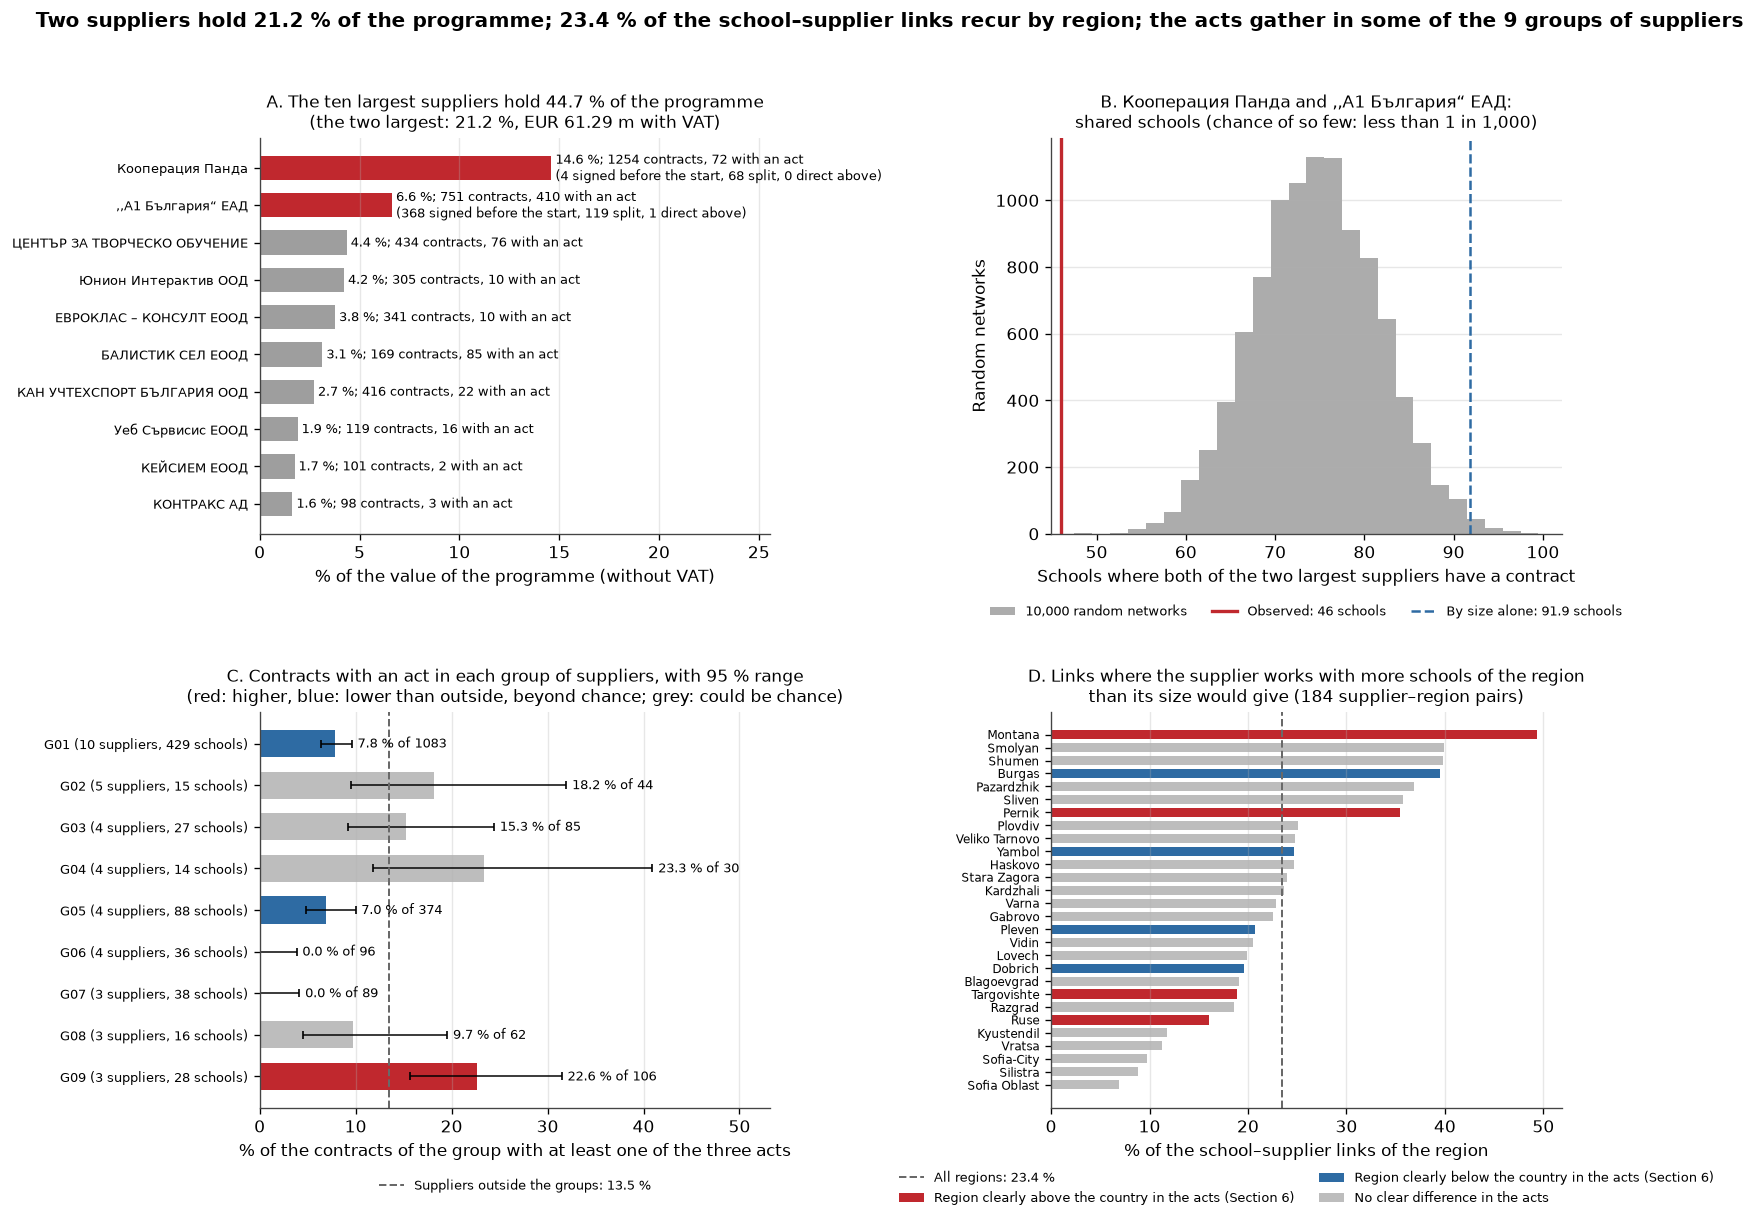

In [26]:
# Figure F2_5: concentration of the programme and steering at the level of the region and the country; every number in the figure is taken from this run.
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5), gridspec_kw={"hspace": 0.45, "wspace": 0.55})
axA, axB, axC, axD = axs.flat

# A. The ten largest suppliers by share of the programme (value without VAT), with their contracts with an act.
a8 = ven_tbl.head(10).iloc[::-1].copy()
for col in ("predated_contracts", "split_30d_contracts", "regime_mismatch_contracts"):
    a8[col] = a8["vendor_id"].map(t2.set_index("vendor_id")[col]).fillna(0)
yA = np.arange(len(a8))
axA.barh(yA, a8["share_val_pct"], color=["#c0282e" if i >= len(a8) - 2 else "#9e9e9e" for i in range(len(a8))], height=0.65)
for y, r in zip(yA, a8.itertuples()):
    lbl = f"{r.share_val_pct:.1f} %; {int(r.contracts)} contracts, {int(r.level1_contracts)} with an act"
    if r.vendor_id in top2_ids:
        lbl += f"\n({int(r.predated_contracts)} signed before the start, {int(r.split_30d_contracts)} split, {int(r.regime_mismatch_contracts)} direct above)"
    axA.text(r.share_val_pct + 0.2, y, lbl, va="center", fontsize=7.5)
axA.set_yticks(yA, [f"{s[:28]}" for s in a8["vendor_name"]], fontsize=8)
axA.set_xlim(0, a8["share_val_pct"].max() * 1.75)
axA.set_xlabel("% of the value of the programme (without VAT)")
axA.set_title(f"A. The ten largest suppliers hold {c10_pct:.1f} % of the programme\n(the two largest: {top2_val_incl / tot_prog_incl * 100:.1f} %, EUR {top2_val_incl / 1e6:.2f} m with VAT)", fontsize=10)

# B. Schools shared by the two largest suppliers: observed, in 10,000 random networks, and by their size alone.
axB.hist(mc_pa, bins=np.arange(mc_pa.min() - 0.5, mc_pa.max() + 1.5, 2), color="#9e9e9e", alpha=0.85, label="10,000 random networks")
axB.axvline(obs_pa, color="#c0282e", lw=2, label=f"Observed: {obs_pa} schools")
axB.axvline(exp_pa_bicm, color="#2e6ba3", ls="--", lw=1.5, label=f"By size alone: {exp_pa_bicm:.1f} schools")
axB.set_xlabel("Schools where both of the two largest suppliers have a contract")
axB.set_ylabel("Random networks")
axB.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=7.5, frameon=False)
axB.set_title(f"B. {ven_tbl['vendor_name'].iloc[0]} and {ven_tbl['vendor_name'].iloc[1]}:\nshared schools (chance of so few: {chance_text(p_pa_le)})", fontsize=10)

# C. Share of contracts with an act in each group of suppliers, against the suppliers outside the groups.
c8 = df_grps[df_grps["group_id"] != "Out of groups"].iloc[::-1]
out_rate8 = float(df_grps.loc[df_grps["group_id"] == "Out of groups", "level1_pct"].iloc[0])
yC = np.arange(len(c8))
colC = ["#c0282e" if (p <= 0.05 and v > out_rate8) else ("#2e6ba3" if p <= 0.05 else "#bdbdbd") for p, v in zip(c8["level1_p_vs_out"], c8["level1_pct"])]
ciC = np.array([wilson_ci(int(round(p * n / 100.0)), int(n))[1:] for p, n in zip(c8["level1_pct"], c8["contracts"])]) * 100.0
axC.barh(yC, c8["level1_pct"], color=colC, height=0.65)
axC.errorbar(c8["level1_pct"], yC, xerr=[c8["level1_pct"] - ciC[:, 0], ciC[:, 1] - c8["level1_pct"]], fmt="none", ecolor="black", elinewidth=0.9, capsize=2.5)
for y, r in zip(yC, c8.itertuples()):
    axC.text(ciC[y, 1] + 0.6, y, f"{r.level1_pct:.1f} % of {int(r.contracts)}", va="center", fontsize=7.5)
axC.axvline(out_rate8, color="dimgray", ls="--", lw=1.2, label=f"Suppliers outside the groups: {out_rate8:.1f} %")
axC.set_yticks(yC, [f"{g} ({int(n)} suppliers, {int(s)} schools)" for g, n, s in zip(c8["group_id"], c8["n_vendors"], c8["schools"])], fontsize=8)
axC.set_xlim(0, max(ciC[:, 1].max(), out_rate8) * 1.3)
axC.set_xlabel("% of the contracts of the group with at least one of the three acts")
axC.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=7.5, frameon=False)
axC.set_title("C. Contracts with an act in each group of suppliers, with 95 % range\n(red: higher, blue: lower than outside, beyond chance; grey: could be chance)", fontsize=10)

# D. By region: share of school-supplier links in which the supplier works with more schools of the region than its size would give.
# d8 and d8_status come from the conclusions cell (Section 6: regions clearly above or below the country in the acts).
yD = np.arange(len(d8))
colD = d8_status.map({"above": "#c0282e", "below": "#2e6ba3", "middle": "#bdbdbd"}).to_numpy()
axD.barh(yD, d8.to_numpy(), color=colD, height=0.7)
for c_, l_ in (("#c0282e", "Region clearly above the country in the acts (Section 6)"), ("#2e6ba3", "Region clearly below the country in the acts (Section 6)"), ("#bdbdbd", "No clear difference in the acts")):
    axD.barh([0], [0], color=c_, label=l_)
axD.axvline(sig_links / n_links * 100, color="dimgray", ls="--", lw=1.2, label=f"All regions: {sig_links / n_links * 100:.1f} %")
axD.set_yticks(yD, [OBLAST_EN.get(o, o) for o in d8.index], fontsize=7)
axD.set_xlabel("% of the school–supplier links of the region")
axD.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=7.5, frameon=False)
axD.set_title(f"D. Links where the supplier works with more schools of the region\nthan its size would give ({len(sig_ov_ob)} supplier–region pairs)", fontsize=10)

for ax in axs.flat:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y" if ax is axB else "x", alpha=0.3)
fig.suptitle(f"Two suppliers hold {top2_val_incl / tot_prog_incl * 100:.1f} % of the programme; {sig_links / n_links * 100:.1f} % of the school–supplier links recur by region; the acts gather in some of the {len(g8)} groups of suppliers", fontsize=12, fontweight="bold")
fig.savefig(FIG_DIR / "F2_5_concentration_steering.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.1 Five limitations of the study

The limitations below follow from the public data and from the way ADFI chooses the schools it inspects. Every number is taken from this run.

In [27]:
# Section 8.1: the five limitations of the study and what each of them touches; every figure is taken from this run (Sections 2, 4, 4.5, 5 and 7).
alt_vat = specs_df.iloc[1]
assert "excl. VAT" in str(alt_vat.iloc[0])
lim = [
    "Предметът и типът на договора не са в ИСУН. (The subject and the type of the contract are not in ISUN.) "
    f"The {n_c_all:,} contracts carry no subject or type, so supplies, services and works cannot be told apart: the threshold applied is the one for supplies "
    "and services, and the thresholds for works (50,000 / 80,000 BGN) are shown only in Figure F2_1, with the assumptions stated. "
    "It means that if some contracts were works, the purchases split within 30 days, the direct awards above the threshold and the prices just below it "
    "would be fewer for them; the contract signed before the project started does not depend on the threshold.",
    f"For {n_assumed_vat:,} contracts it is not known whether the amount includes VAT; they are taken as including VAT, the regime that dominates among the projects with a known VAT basis (Section 2). "
    f"Under the other assumption, the prices just below the threshold of Section 5 show {alt_vat['excess']:+.0f} contracts against the expected ({alt_vat['percent_excess']:+.0f} %), "
    f"with a chance of {chance_text(float(alt_vat['p_value']))}, against {base_fit['excess']:+.0f} ({base_fit['percent_excess']:+.0f} %) under the main assumption. "
    + ("It means that the excess just below the threshold does not come from the way VAT is treated."
       if float(alt_vat["p_value"]) <= 0.05 else
       "It means that the excess just below the threshold depends in part on the way VAT is treated: under the other assumption it is smaller "
       "and could be due to chance, which is why Section 5 treats the prices just below the threshold as a signal, not as proof."),
    "The public data contain no checklists of ex-ante control and no dates of the signatures of the financial controller, "
    "so an indicator shows a risk that the controller had to check, not a proven violation. "
    "It means that every conclusion of this study is about where the check before signature had to stop a commitment, not about who failed to do it.",
    f"The schools inspected by ADFI are not a random sample: ADFI inspected {n_aud_l1 / n_l1_7 * 100:.1f} % of the schools with an act and "
    f"{n_aud_no / n_no_l1 * 100:.1f} % of the others (chance of the difference: {chance_text(l1b['selection_p'])}; Section 7), "
    "so the comparison with Element 1 cannot be extended to the schools that were not inspected. "
    "It means that this touches only Section 7 and the ADFI figures of Section 8; H2 and the indicators are measured on all schools with a contract.",
    f"{int(anom_all.sum())} contracts have a signature date outside the period of the programme ({int(anom_pre.sum())} before 1 January 2023, "
    f"{int(anom_post.sum())} after {EXTRACTION_DATE}); " + (f"H2 is {h2_decision} with and without them (Section 4.5). It means that these dates do not change the main result." if h2_decision == h2_clean_decision else f"H2 is {h2_decision} with them and {h2_clean_decision} without them (Section 4.5). It means that the main result depends on these dates."),
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lim, 1)))

1. Предметът и типът на договора не са в ИСУН. (The subject and the type of the contract are not in ISUN.) The 11,128 contracts carry no subject or type, so supplies, services and works cannot be told apart: the threshold applied is the one for supplies and services, and the thresholds for works (50,000 / 80,000 BGN) are shown only in Figure F2_1, with the assumptions stated. It means that if some contracts were works, the purchases split within 30 days, the direct awards above the threshold and the prices just below it would be fewer for them; the contract signed before the project started does not depend on the threshold.

2. For 5,272 contracts it is not known whether the amount includes VAT; they are taken as including VAT, the regime that dominates among the projects with a known VAT basis (Section 2). Under the other assumption, the prices just below the threshold of Section 5 show +78 contracts against the expected (+38 %), with a chance of about 13.3 in 100, against +111 (+60 %